In [1]:
# imports et configuration
from pathlib import Path
import pandas as pd
import numpy as np
import os
import json
import gc

# Dossier contenant les CSV
DATA_DIR = Path("./home-credit-default-risk")

# Fichiers attendus
FILES = [
    "application_train.csv",
    "application_test.csv",
    "bureau.csv",
    "bureau_balance.csv",
    "previous_application.csv",
    "POS_CASH_balance.csv",
    "credit_card_balance.csv",
    "installments_payments.csv"
]

print("Dossier de travail :", DATA_DIR.resolve())

Dossier de travail : C:\Users\manou\projet6deployerML\home-credit-default-risk


In [2]:
# Vérifier les fichiers
print("Fichiers trouvés :\n")

for file in FILES:
    path = DATA_DIR / file
    
    if path.exists():
        size_mb = path.stat().st_size / (1024 ** 2)
        print(f"✓ {file:35} {size_mb:10.2f} MB")
    else:
        print(f"✗ {file:35} ABSENT")

Fichiers trouvés :

✓ application_train.csv                   158.44 MB
✓ application_test.csv                     25.34 MB
✓ bureau.csv                              162.14 MB
✓ bureau_balance.csv                      358.19 MB
✓ previous_application.csv                386.21 MB
✓ POS_CASH_balance.csv                    374.51 MB
✓ credit_card_balance.csv                 404.91 MB
✓ installments_payments.csv               689.62 MB


In [3]:
# Audit général de chaque table
## Cette partie lit chaque fichier et récupère les informations essentielles.
summary = []

for file in FILES:
    
    path = DATA_DIR / file
    
    if not path.exists():
        continue
    
    print(f"\nAnalyse de : {file}")
    
    df = pd.read_csv(path)
    
    info = {
        "file": file,
        "rows": df.shape[0],
        "columns": df.shape[1],
        "memory_mb": df.memory_usage(deep=True).sum() / (1024 ** 2),
        "duplicates": df.duplicated().sum(),
        "missing_cells": df.isna().sum().sum(),
        "missing_percentage": (
            df.isna().sum().sum() /
            (df.shape[0] * df.shape[1]) * 100
        )
    }
    
    summary.append(info)
    
    print(f"  Lignes       : {df.shape[0]:,}")
    print(f"  Colonnes     : {df.shape[1]:,}")
    print(f"  Mémoire      : {info['memory_mb']:.2f} MB")
    print(f"  Doublons     : {info['duplicates']:,}")
    print(f"  Valeurs NA   : {info['missing_percentage']:.2f}%")
    
    del df
    gc.collect()


Analyse de : application_train.csv
  Lignes       : 307,511
  Colonnes     : 122
  Mémoire      : 504.99 MB
  Doublons     : 0
  Valeurs NA   : 24.40%

Analyse de : application_test.csv
  Lignes       : 48,744
  Colonnes     : 121
  Mémoire      : 79.69 MB
  Doublons     : 0
  Valeurs NA   : 23.81%

Analyse de : bureau.csv
  Lignes       : 1,716,428
  Colonnes     : 17
  Mémoire      : 472.82 MB
  Doublons     : 0
  Valeurs NA   : 13.50%

Analyse de : bureau_balance.csv
  Lignes       : 27,299,925
  Colonnes     : 3
  Mémoire      : 1718.33 MB
  Doublons     : 0
  Valeurs NA   : 0.00%

Analyse de : previous_application.csv
  Lignes       : 1,670,214
  Colonnes     : 37
  Mémoire      : 1703.01 MB
  Doublons     : 0
  Valeurs NA   : 17.98%

Analyse de : POS_CASH_balance.csv
  Lignes       : 10,001,358
  Colonnes     : 8
  Mémoire      : 1060.95 MB
  Doublons     : 0
  Valeurs NA   : 0.07%

Analyse de : credit_card_balance.csv
  Lignes       : 3,840,312
  Colonnes     : 23
  Mémoire    

In [4]:
summary_df = pd.DataFrame(summary)

summary_df

,file,rows,columns,memory_mb,duplicates,missing_cells,missing_percentage
0,application_train.csv,307511,122,504.985326,0,9152465,24.395942
1,application_test.csv,48744,121,79.692988,0,1404419,23.811687
2,bureau.csv,1716428,17,472.824842,0,3939947,13.502552
3,bureau_balance.csv,27299925,3,1718.325788,0,0,0.000000
4,previous_application.csv,1670214,37,1703.009955,0,11109336,17.976877
5,POS_CASH_balance.csv,10001358,8,1060.945873,0,52158,0.065189
6,credit_card_balance.csv,3840312,23,846.388412,0,5877356,6.654074
7,installments_payments.csv,13605401,8,830.407902,0,5810,0.005338


In [5]:
summary_df.to_csv("data_summary.csv", index=False)

print("✓ data_summary.csv créé")

✓ data_summary.csv créé


# Analyse détaillée des colonnes
## Maintenant on va créer un fichier qui nous permettra de comprendre chaque variable de chaque table.

In [6]:
columns_summary = []

for file in FILES:
    
    path = DATA_DIR / file
    
    if not path.exists():
        continue
    
    print(f"Analyse des colonnes : {file}")
    
    df = pd.read_csv(path, nrows=10000)
    
    for col in df.columns:
        
        dtype = str(df[col].dtype)
        missing = df[col].isna().sum()
        missing_pct = df[col].isna().mean() * 100
        unique = df[col].nunique(dropna=True)
        
        columns_summary.append({
            "file": file,
            "column": col,
            "dtype": dtype,
            "missing_count_sample": missing,
            "missing_pct_sample": missing_pct,
            "unique_values_sample": unique
        })
    
    del df
    gc.collect()

columns_df = pd.DataFrame(columns_summary)

columns_df.to_csv(
    "columns_summary.csv",
    index=False
)

print("✓ columns_summary.csv créé")

Analyse des colonnes : application_train.csv
Analyse des colonnes : application_test.csv
Analyse des colonnes : bureau.csv
Analyse des colonnes : bureau_balance.csv
Analyse des colonnes : previous_application.csv
Analyse des colonnes : POS_CASH_balance.csv
Analyse des colonnes : credit_card_balance.csv
Analyse des colonnes : installments_payments.csv
✓ columns_summary.csv créé


### ⚠️ Ici j'utilise seulement 10 000 lignes pour l'analyse des colonnes. C'est volontaire : cela évite de charger inutilement les énormes tables historiques.

In [7]:
# Analyse spécifique de application_train
## C'est notre table principale.
train = pd.read_csv(
    DATA_DIR / "application_train.csv"
)

print("Shape :", train.shape)

train.head()

Shape : (307511, 122)


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [8]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Columns: 122 entries, SK_ID_CURR to AMT_REQ_CREDIT_BUREAU_YEAR
dtypes: float64(65), int64(41), object(16)
memory usage: 286.2+ MB


## Analyse de TARGET

In [9]:

print(train["TARGET"].value_counts())

print("\nProportions :")

target_distribution = train["TARGET"].value_counts(normalize=True) * 100

print(target_distribution)

TARGET
0    282686
1     24825
Name: count, dtype: int64

Proportions :
TARGET
0    91.927118
1     8.072882
Name: proportion, dtype: float64


### C'est très important pour ton projet, puisque le client veut prédire le défaut de paiement.

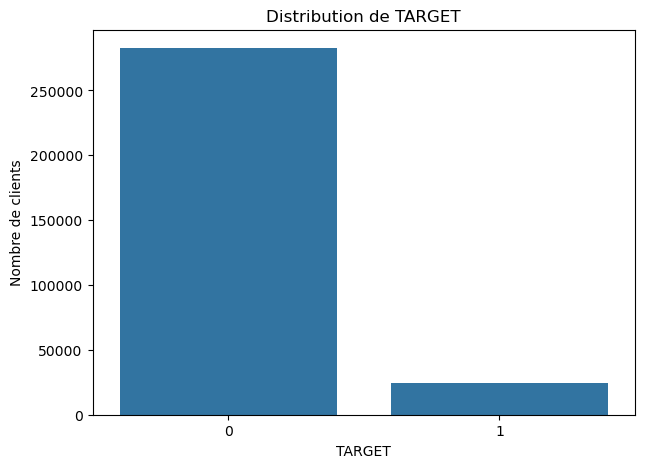

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(
    data=train,
    x="TARGET"
)

plt.title("Distribution de TARGET")
plt.xlabel("TARGET")
plt.ylabel("Nombre de clients")

plt.show()

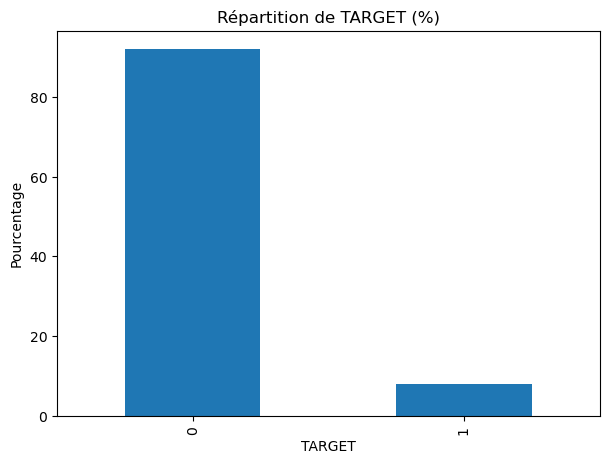

In [11]:
target_distribution.plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Répartition de TARGET (%)")
plt.ylabel("Pourcentage")

plt.show()

#### les resultats seront directement utiles pour expliquer le problème de déséquilibre des classes dans ton rapport

In [12]:
### Valeurs manquantes
missing = pd.DataFrame({
    "missing_count": train.isna().sum(),
    "missing_percentage": train.isna().mean() * 100
})

missing = missing.sort_values(
    "missing_percentage",
    ascending=False
)

missing.head(30)

,missing_count,missing_percentage
COMMONAREA_MEDI,214865,69.872297
COMMONAREA_AVG,214865,69.872297
COMMONAREA_MODE,214865,69.872297
NONLIVINGAPARTMENTS_MODE,213514,69.432963
NONLIVINGAPARTMENTS_AVG,213514,69.432963
NONLIVINGAPARTMENTS_MEDI,213514,69.432963
FONDKAPREMONT_MODE,210295,68.386172
LIVINGAPARTMENTS_MODE,210199,68.354953
LIVINGAPARTMENTS_AVG,210199,68.354953
LIVINGAPARTMENTS_MEDI,210199,68.354953


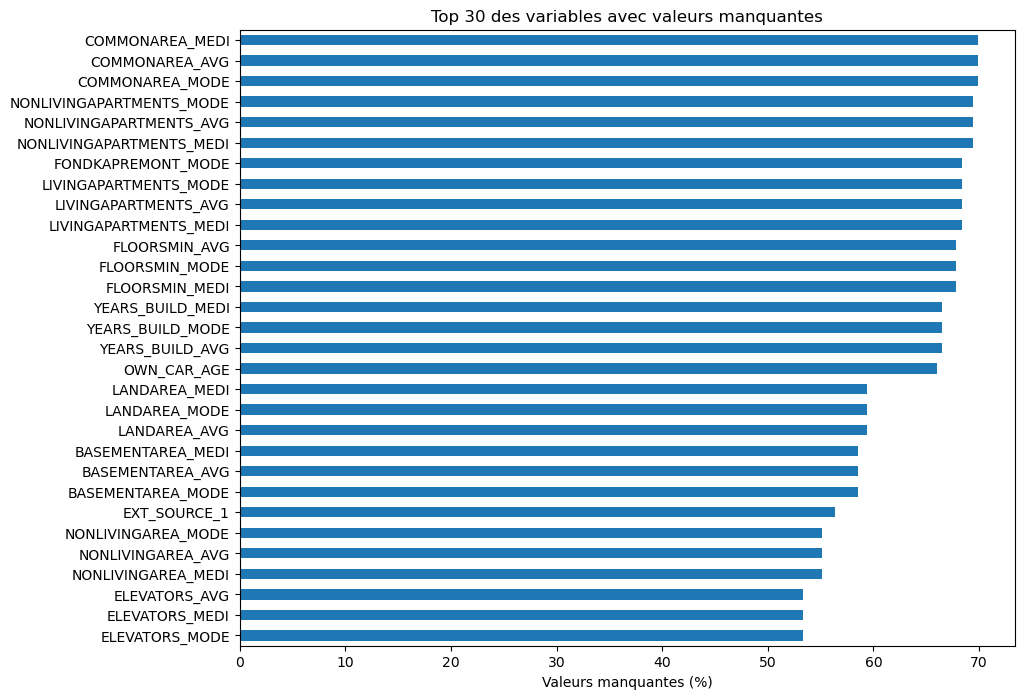

In [13]:
plt.figure(figsize=(10, 8))

missing.head(30)["missing_percentage"].sort_values().plot(
    kind="barh"
)

plt.xlabel("Valeurs manquantes (%)")
plt.title("Top 30 des variables avec valeurs manquantes")

plt.show()

## Types de variables

In [14]:
numeric_cols = train.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_cols = train.select_dtypes(
    include=["object", "category"]
).columns

print("Variables numériques :", len(numeric_cols))
print("Variables catégorielles :", len(categorical_cols))

print("\nVariables catégorielles :")
print(list(categorical_cols))

Variables numériques : 106
Variables catégorielles : 16

Variables catégorielles :
['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'WEEKDAY_APPR_PROCESS_START', 'ORGANIZATION_TYPE', 'FONDKAPREMONT_MODE', 'HOUSETYPE_MODE', 'WALLSMATERIAL_MODE', 'EMERGENCYSTATE_MODE']


### Cardinalité des variables catégorielles

In [15]:
categorical_cardinality = pd.DataFrame({
    "column": categorical_cols,
    "unique_values": [
        train[col].nunique(dropna=True)
        for col in categorical_cols
    ],
    "missing_percentage": [
        train[col].isna().mean() * 100
        for col in categorical_cols
    ]
})

categorical_cardinality = categorical_cardinality.sort_values(
    "unique_values",
    ascending=False
)

categorical_cardinality

,column,unique_values,missing_percentage
11,ORGANIZATION_TYPE,58,0.000000
9,OCCUPATION_TYPE,18,31.345545
5,NAME_INCOME_TYPE,8,0.000000
4,NAME_TYPE_SUITE,7,0.420148
10,WEEKDAY_APPR_PROCESS_START,7,0.000000
14,WALLSMATERIAL_MODE,7,50.840783
7,NAME_FAMILY_STATUS,6,0.000000
8,NAME_HOUSING_TYPE,6,0.000000
6,NAME_EDUCATION_TYPE,5,0.000000
12,FONDKAPREMONT_MODE,4,68.386172


#### Cela nous permettra de savoir quelles variables nécessitent un traitement particulier.

### Détection des colonnes avec une seule valeur

In [16]:
#### Certaines variables peuvent être inutiles
constant_columns = [
    col for col in train.columns
    if train[col].nunique(dropna=False) <= 1
]

print("Nombre de colonnes constantes :", len(constant_columns))

print(constant_columns)

Nombre de colonnes constantes : 0
[]


### Doublons

In [17]:
duplicate_count = train.duplicated().sum()

print("Nombre de lignes totalement dupliquées :", duplicate_count)

Nombre de lignes totalement dupliquées : 0


In [18]:
print(
    "Nombre de SK_ID_CURR uniques :",
    train["SK_ID_CURR"].nunique()
)

print(
    "Nombre de lignes :",
    len(train)
)

Nombre de SK_ID_CURR uniques : 307511
Nombre de lignes : 307511


#### Cela nous permet de vérifier que SK_ID_CURR identifie bien un client de manière unique dans cette table

#### Tu as :

#### 307 511 lignes dans application_train
#### 307 511 SK_ID_CURR uniques
#### 0 doublon sur SK_ID_CURR
#### 0 ligne totalement dupliquée

#### ➡️ Très bien. SK_ID_CURR est donc bien notre identifiant unique client dans la table principale.

### Vérification des clés dans les autres tables

#### Très utile avant de commencer les jointures

In [19]:
KEYS = [
    "SK_ID_CURR",
    "SK_ID_BUREAU",
    "SK_ID_PREV"
]

for file in FILES:
    
    path = DATA_DIR / file
    
    if not path.exists():
        continue
    
    df = pd.read_csv(path, nrows=10000)
    
    print("\n" + "=" * 70)
    print(file)
    
    for key in KEYS:
        if key in df.columns:
            print(
                f"{key:20} "
                f"présente | "
                f"uniques dans échantillon : {df[key].nunique():,}"
            )
    
    del df
    gc.collect()


application_train.csv
SK_ID_CURR           présente | uniques dans échantillon : 10,000

application_test.csv
SK_ID_CURR           présente | uniques dans échantillon : 10,000

bureau.csv
SK_ID_CURR           présente | uniques dans échantillon : 2,011
SK_ID_BUREAU         présente | uniques dans échantillon : 10,000

bureau_balance.csv
SK_ID_BUREAU         présente | uniques dans échantillon : 273

previous_application.csv
SK_ID_CURR           présente | uniques dans échantillon : 9,734
SK_ID_PREV           présente | uniques dans échantillon : 10,000

POS_CASH_balance.csv
SK_ID_CURR           présente | uniques dans échantillon : 9,494
SK_ID_PREV           présente | uniques dans échantillon : 9,660

credit_card_balance.csv
SK_ID_CURR           présente | uniques dans échantillon : 9,520
SK_ID_PREV           présente | uniques dans échantillon : 9,530

installments_payments.csv
SK_ID_CURR           présente | uniques dans échantillon : 8,893
SK_ID_PREV           présente | uniques d

### Sauvegarder quelques statistiques supplémentaires

In [20]:
### Enfin, on va générer un fichier particulièrement utile pour la suite.
numeric_summary = []

for file in FILES:
    
    path = DATA_DIR / file
    
    if not path.exists():
        continue
    
    df = pd.read_csv(path, nrows=10000)
    
    numeric = df.select_dtypes(
        include=["number"]
    )
    
    for col in numeric.columns:
        
        numeric_summary.append({
            "file": file,
            "column": col,
            "mean": numeric[col].mean(),
            "std": numeric[col].std(),
            "min": numeric[col].min(),
            "median": numeric[col].median(),
            "max": numeric[col].max(),
            "missing_pct": numeric[col].isna().mean() * 100
        })
    
    del df
    gc.collect()

numeric_df = pd.DataFrame(numeric_summary)

numeric_df.to_csv(
    "numeric_summary.csv",
    index=False
)

print("✓ numeric_summary.csv créé")

✓ numeric_summary.csv créé


In [21]:
train.shape
train["TARGET"].value_counts()
train["TARGET"].value_counts(normalize=True)

TARGET
0    0.919271
1    0.080729
Name: proportion, dtype: float64

##### La variable cible TARGET présente un fort déséquilibre de classes : environ 91,9 % des observations correspondent à des clients sans défaut (TARGET=0) contre seulement 8,1 % de clients en défaut (TARGET=1). Ce déséquilibre devra être pris en compte lors de l'entraînement et de l'évaluation des modèles afin d'éviter de favoriser artificiellement la classe majoritaire.

##### ⚠️ Et surtout : l'accuracy seule sera insuffisante. C'est pour cela que nous utiliserons notamment l'AUC et le coût métie

In [22]:
description = pd.read_csv(
    DATA_DIR / "HomeCredit_columns_description.csv",
    encoding="latin1"
)

print("Dimensions :", description.shape)
print("\nColonnes :", description.columns.tolist())

display(description.head(10))

Dimensions : (219, 5)

Colonnes : ['Unnamed: 0', 'Table', 'Row', 'Description', 'Special']


,Unnamed: 0,Table,Row,Description,Special
0,1,application_{train|test}.csv,SK_ID_CURR,ID of loan in our sample,NaN
1,2,application_{train|test}.csv,TARGET,Target variable (1 - client with payment diffi...,NaN
2,5,application_{train|test}.csv,NAME_CONTRACT_TYPE,Identification if loan is cash or revolving,NaN
3,6,application_{train|test}.csv,CODE_GENDER,Gender of the client,NaN
4,7,application_{train|test}.csv,FLAG_OWN_CAR,Flag if the client owns a car,NaN
5,8,application_{train|test}.csv,FLAG_OWN_REALTY,Flag if client owns a house or flat,NaN
6,9,application_{train|test}.csv,CNT_CHILDREN,Number of children the client has,NaN
7,10,application_{train|test}.csv,AMT_INCOME_TOTAL,Income of the client,NaN
8,11,application_{train|test}.csv,AMT_CREDIT,Credit amount of the loan,NaN
9,12,application_{train|test}.csv,AMT_ANNUITY,Loan annuity,NaN


#### Cela va être très utile pour justifier nos choix de nettoyage et de feature engineering

####  On va commencer uniquement avec application_train, qui est notre table principale.
#### Je veux d'abord identifier les variables ayant plus de 50 % de valeurs manquantes, mais sans les supprimer.

In [23]:
# Analyse des valeurs manquantes dans application_train

train = pd.read_csv(
    DATA_DIR / "application_train.csv"
)

missing_train = pd.DataFrame({
    "missing_count": train.isna().sum(),
    "missing_percentage": train.isna().mean() * 100,
    "dtype": train.dtypes
})

missing_train = missing_train.sort_values(
    "missing_percentage",
    ascending=False
)

print("Nombre total de variables :", len(missing_train))

print("\nVariables avec plus de 50 % de valeurs manquantes :")

display(
    missing_train[
        missing_train["missing_percentage"] > 50
    ]
)

Nombre total de variables : 122

Variables avec plus de 50 % de valeurs manquantes :


,missing_count,missing_percentage,dtype
COMMONAREA_MEDI,214865,69.872297,float64
COMMONAREA_AVG,214865,69.872297,float64
COMMONAREA_MODE,214865,69.872297,float64
NONLIVINGAPARTMENTS_MODE,213514,69.432963,float64
NONLIVINGAPARTMENTS_AVG,213514,69.432963,float64
NONLIVINGAPARTMENTS_MEDI,213514,69.432963,float64
FONDKAPREMONT_MODE,210295,68.386172,object
LIVINGAPARTMENTS_MODE,210199,68.354953,float64
LIVINGAPARTMENTS_AVG,210199,68.354953,float64
LIVINGAPARTMENTS_MEDI,210199,68.354953,float64


In [24]:
print(
    "Nombre de variables avec >50% de valeurs manquantes :",
    (missing_train["missing_percentage"] > 50).sum()
)

Nombre de variables avec >50% de valeurs manquantes : 41


In [25]:
# Variables avec plus de 50 % de valeurs manquantes

high_missing = missing_train[
    missing_train["missing_percentage"] > 50
].copy()

high_missing = high_missing.reset_index()

# Renommer la colonne contenant les noms des variables
high_missing = high_missing.rename(
    columns={"index": "Row"}
)

# Mettre les noms au même format que dans le fichier de description
description["Row"] = description["Row"].astype(str)

# Faire la correspondance avec la documentation
high_missing_description = high_missing.merge(
    description[["Row", "Description", "Special"]],
    on="Row",
    how="left"
)

display(
    high_missing_description[
        [
            "Row",
            "missing_percentage",
            "dtype",
            "Description",
            "Special"
        ]
    ]
)

,Row,missing_percentage,dtype,Description,Special
0,COMMONAREA_MEDI,69.872297,float64,Normalized information about building where th...,normalized
1,COMMONAREA_AVG,69.872297,float64,Normalized information about building where th...,normalized
2,COMMONAREA_MODE,69.872297,float64,Normalized information about building where th...,normalized
3,NONLIVINGAPARTMENTS_MODE,69.432963,float64,Normalized information about building where th...,normalized
4,NONLIVINGAPARTMENTS_AVG,69.432963,float64,Normalized information about building where th...,normalized
5,NONLIVINGAPARTMENTS_MEDI,69.432963,float64,Normalized information about building where th...,normalized
6,FONDKAPREMONT_MODE,68.386172,object,Normalized information about building where th...,normalized
7,LIVINGAPARTMENTS_MODE,68.354953,float64,Normalized information about building where th...,normalized
8,LIVINGAPARTMENTS_AVG,68.354953,float64,Normalized information about building where th...,normalized
9,LIVINGAPARTMENTS_MEDI,68.354953,float64,Normalized information about building where th...,normalized


##### Une analyse des valeurs manquantes a été réalisée sur la table principale. 41 variables présentent plus de 50 % de valeurs manquantes. Leur suppression n'a pas été effectuée automatiquement : leur signification métier et leur relation avec la variable cible ont été étudiées avant toute décision

In [26]:
# Analyse du lien entre valeurs manquantes et TARGET

high_missing_cols = missing_train[
    missing_train["missing_percentage"] > 50
].index.tolist()

missing_target_analysis = []

for col in high_missing_cols:
    
    # Indicateur : 1 si valeur manquante, 0 sinon
    is_missing = train[col].isna()
    
    # Taux de défaut lorsque la variable est manquante
    target_when_missing = train.loc[
        is_missing, "TARGET"
    ].mean()
    
    # Taux de défaut lorsque la variable n'est pas manquante
    target_when_present = train.loc[
        ~is_missing, "TARGET"
    ].mean()
    
    missing_target_analysis.append({
        "variable": col,
        "missing_pct": is_missing.mean() * 100,
        "default_rate_missing": target_when_missing * 100,
        "default_rate_present": target_when_present * 100,
        "difference": (
            target_when_missing - target_when_present
        ) * 100
    })

missing_target_df = pd.DataFrame(
    missing_target_analysis
)

missing_target_df = missing_target_df.sort_values(
    "difference",
    ascending=False
)

display(missing_target_df)

,variable,missing_pct,default_rate_missing,default_rate_present,difference
36,ENTRANCES_MODE,50.348768,9.178572,6.951658,2.226914
35,ENTRANCES_AVG,50.348768,9.178572,6.951658,2.226914
34,ENTRANCES_MEDI,50.348768,9.178572,6.951658,2.226914
27,ELEVATORS_MEDI,53.295980,9.100561,6.900153,2.200408
28,ELEVATORS_AVG,53.295980,9.100561,6.900153,2.200408
29,ELEVATORS_MODE,53.295980,9.100561,6.900153,2.200408
32,APARTMENTS_AVG,50.749729,9.153472,6.959393,2.194080
31,APARTMENTS_MEDI,50.749729,9.153472,6.959393,2.194080
33,APARTMENTS_MODE,50.749729,9.153472,6.959393,2.194080
40,HOUSETYPE_MODE,50.176091,9.151182,6.986959,2.164223


In [27]:
missing_target_df.to_csv(
    "missing_target_analysis.csv",
    index=False
)

###### La colonne difference est particulièrement intéressante.
##### Elle nous permettra de distinguer :

##### les variables dont l'absence semble informative ;
##### les variables dont l'absence semble peu informative ;
##### les variables candidates à la suppression.

##### 41 variables > 50 % NA
#####          │
#####          ├── Variables importantes → conserver + imputation
#####          │
#####          ├── Variables dont NA est informatif
#####          │       → conserver + indicateur de missing
#####          │
#####          └── Variables peu informatives
#####                  → suppression possible et justifiée

## Vérifier les doublons de clients

In [28]:
# ============================================================
# 1. Vérification des doublons dans application_train
# ============================================================

print("Nombre de lignes :", len(train))

print(
    "Nombre de SK_ID_CURR uniques :",
    train["SK_ID_CURR"].nunique()
)

print(
    "Nombre de doublons sur SK_ID_CURR :",
    train["SK_ID_CURR"].duplicated().sum()
)

print(
    "Nombre de lignes totalement dupliquées :",
    train.duplicated().sum()
)

Nombre de lignes : 307511
Nombre de SK_ID_CURR uniques : 307511
Nombre de doublons sur SK_ID_CURR : 0
Nombre de lignes totalement dupliquées : 0


##  Vérifier les principales variables numériques

In [29]:
# ============================================================
# 2. Statistiques descriptives des principales variables
# ============================================================

important_numeric = [
    "CNT_CHILDREN",
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "DAYS_BIRTH",
    "DAYS_EMPLOYED"
]

display(
    train[important_numeric].describe().T
)

,count,mean,std,min,25%,50%,75%,max
CNT_CHILDREN,307511.0,0.417052,0.722121,0.0,0.0,0.0,1.0,19.0
AMT_INCOME_TOTAL,307511.0,168797.919297,237123.146279,25650.0,112500.0,147150.0,202500.0,117000000.0
AMT_CREDIT,307511.0,599025.999706,402490.776996,45000.0,270000.0,513531.0,808650.0,4050000.0
AMT_ANNUITY,307499.0,27108.573909,14493.737315,1615.5,16524.0,24903.0,34596.0,258025.5
DAYS_BIRTH,307511.0,-16036.995067,4363.988632,-25229.0,-19682.0,-15750.0,-12413.0,-7489.0
DAYS_EMPLOYED,307511.0,63815.045904,141275.766519,-17912.0,-2760.0,-1213.0,-289.0,365243.0


##### Parce qu'elles ont une vraie signification métier :

##### CNT_CHILDREN → nombre d'enfants ;

##### AMT_INCOME_TOTAL → revenu ;

##### AMT_CREDIT → montant du crédit ;

##### AMT_ANNUITY → annuité ;

##### DAYS_BIRTH → âge en jours ;

##### DAYS_EMPLOYED → ancienneté/temps d'emploi en jours.

## Vérifier spécifiquement CNT_CHILDREN

In [30]:
print(
    train["CNT_CHILDREN"].value_counts().sort_index()
)
print(
    "Maximum CNT_CHILDREN :",
    train["CNT_CHILDREN"].max()
)

CNT_CHILDREN
0     215371
1      61119
2      26749
3       3717
4        429
5         84
6         21
7          7
8          2
9          2
10         2
11         1
12         2
14         3
19         2
Name: count, dtype: int64
Maximum CNT_CHILDREN : 19


## Vérifier les revenus

In [31]:
print("Minimum revenu :", train["AMT_INCOME_TOTAL"].min())
print("Maximum revenu :", train["AMT_INCOME_TOTAL"].max())
print("Médiane revenu :", train["AMT_INCOME_TOTAL"].median())

Minimum revenu : 25650.0
Maximum revenu : 117000000.0
Médiane revenu : 147150.0


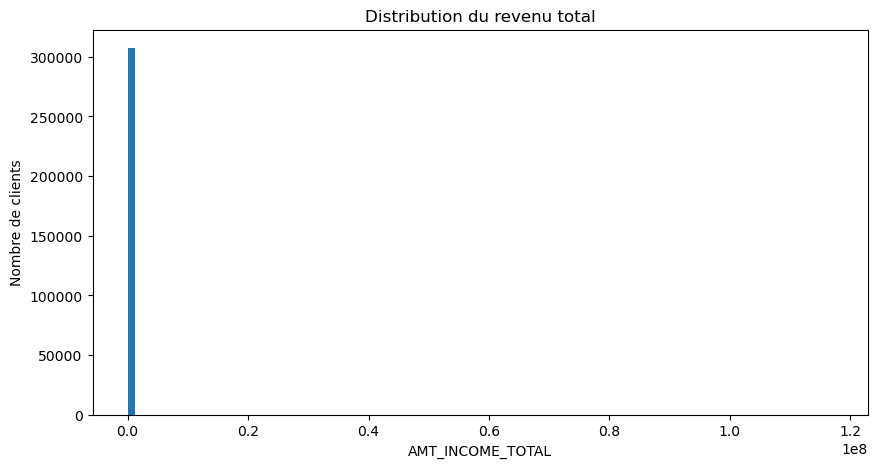

In [32]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    train["AMT_INCOME_TOTAL"].dropna(),
    bins=100
)

plt.title("Distribution du revenu total")
plt.xlabel("AMT_INCOME_TOTAL")
plt.ylabel("Nombre de clients")

plt.show()

## Vérifier les montants de crédit

In [33]:
print("Minimum crédit :", train["AMT_CREDIT"].min())
print("Maximum crédit :", train["AMT_CREDIT"].max())
print("Médiane crédit :", train["AMT_CREDIT"].median())

Minimum crédit : 45000.0
Maximum crédit : 4050000.0
Médiane crédit : 513531.0


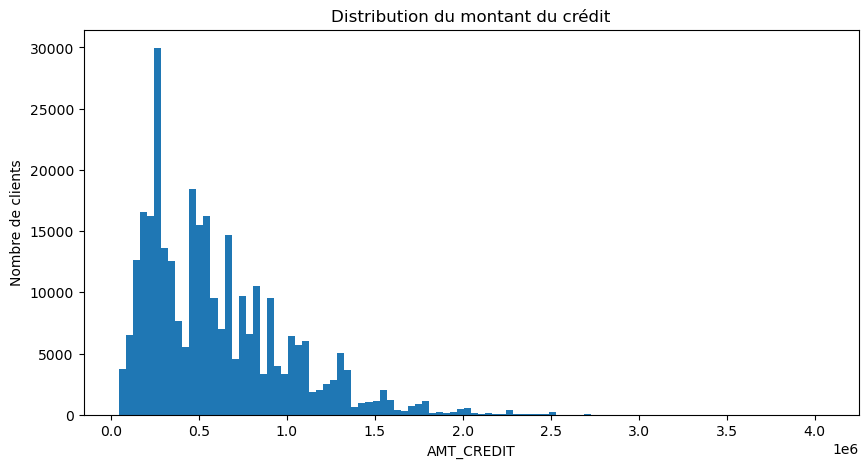

In [34]:
plt.figure(figsize=(10, 5))

plt.hist(
    train["AMT_CREDIT"].dropna(),
    bins=100
)

plt.title("Distribution du montant du crédit")
plt.xlabel("AMT_CREDIT")
plt.ylabel("Nombre de clients")

plt.show()

## Vérifier DAYS_BIRTH

In [35]:
age_years = -train["DAYS_BIRTH"] / 365.25

print(age_years.describe())

count    307511.000000
mean         43.906900
std          11.947950
min          20.503765
25%          33.984942
50%          43.121150
75%          53.886379
max          69.073238
Name: DAYS_BIRTH, dtype: float64


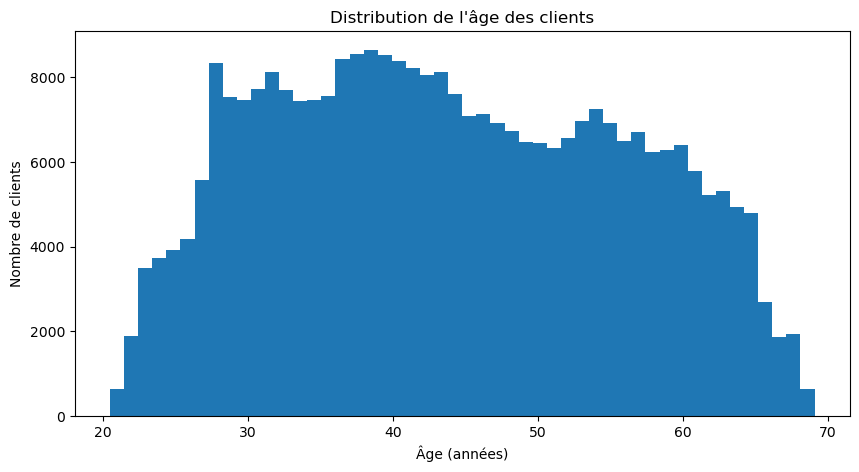

In [36]:
plt.figure(figsize=(10, 5))

plt.hist(
    age_years.dropna(),
    bins=50
)

plt.title("Distribution de l'âge des clients")
plt.xlabel("Âge (années)")
plt.ylabel("Nombre de clients")

plt.show()

## Vérifier DAYS_EMPLOYED

### C'est une variable particulièrement intéressante dans Home Credit, car elle contient des valeurs atypiques.

In [37]:
print(
    train["DAYS_EMPLOYED"].describe()
)

count    307511.000000
mean      63815.045904
std      141275.766519
min      -17912.000000
25%       -2760.000000
50%       -1213.000000
75%        -289.000000
max      365243.000000
Name: DAYS_EMPLOYED, dtype: float64


In [38]:
print(
    "Valeur minimale :",
    train["DAYS_EMPLOYED"].min()
)

print(
    "Valeur maximale :",
    train["DAYS_EMPLOYED"].max()
)

Valeur minimale : -17912
Valeur maximale : 365243


In [39]:
print(
    train["DAYS_EMPLOYED"].value_counts().head(10)
)

DAYS_EMPLOYED
 365243    55374
-200         156
-224         152
-230         151
-199         151
-212         150
-384         143
-229         143
-231         140
-215         138
Name: count, dtype: int64


In [40]:
# Analyse de l'anomalie DAYS_EMPLOYED

anomaly_count = (
    train["DAYS_EMPLOYED"] == 365243
).sum()

anomaly_percentage = (
    anomaly_count / len(train) * 100
)

print("Nombre de valeurs = 365243 :", anomaly_count)
print("Pourcentage :", round(anomaly_percentage, 2), "%")

print("\nNombre de valeurs manquantes :",
      train["DAYS_EMPLOYED"].isna().sum())

Nombre de valeurs = 365243 : 55374
Pourcentage : 18.01 %

Nombre de valeurs manquantes : 0


### Puis vérifions si cette anomalie est liée au défaut de paiement

In [41]:
# Comparaison du taux de défaut

print("Taux de défaut global :",
      round(train["TARGET"].mean() * 100, 2), "%")

print(
    "Taux de défaut lorsque DAYS_EMPLOYED = 365243 :",
    round(
        train.loc[
            train["DAYS_EMPLOYED"] == 365243,
            "TARGET"
        ].mean() * 100,
        2
    ),
    "%"
)

print(
    "Taux de défaut lorsque DAYS_EMPLOYED != 365243 :",
    round(
        train.loc[
            train["DAYS_EMPLOYED"] != 365243,
            "TARGET"
        ].mean() * 100,
        2
    ),
    "%"
)

Taux de défaut global : 8.07 %
Taux de défaut lorsque DAYS_EMPLOYED = 365243 : 5.4 %
Taux de défaut lorsque DAYS_EMPLOYED != 365243 : 8.66 %


#### C'est une analyse intéressante pour le rapport : elle montre que l'anomalie est potentiellement informative et qu'on ne doit pas simplement la supprimer.

## NETTOYAGE

In [42]:
# ============================================================
# DÉBUT DU NETTOYAGE
# Création d'une copie de travail
# ============================================================

train_clean = train.copy()

print("Dimensions avant nettoyage :", train_clean.shape)

# Vérification
print("Nombre de lignes :", len(train_clean))
print("Nombre de colonnes :", train_clean.shape[1])

Dimensions avant nettoyage : (307511, 122)
Nombre de lignes : 307511
Nombre de colonnes : 122


In [43]:
# ============================================================
# Traitement de l'anomalie DAYS_EMPLOYED
# ============================================================

# Création d'un indicateur permettant de conserver
# l'information sur la valeur anomalique

train_clean["DAYS_EMPLOYED_ANOM"] = (
    train_clean["DAYS_EMPLOYED"] == 365243
).astype("int8")

print(
    "Nombre de clients avec DAYS_EMPLOYED = 365243 :",
    train_clean["DAYS_EMPLOYED_ANOM"].sum()
)

print(
    "Pourcentage :",
    round(
        train_clean["DAYS_EMPLOYED_ANOM"].mean() * 100,
        2
    ),
    "%"
)

Nombre de clients avec DAYS_EMPLOYED = 365243 : 55374
Pourcentage : 18.01 %


In [44]:
# ============================================================
# Correction de l'anomalie DAYS_EMPLOYED
# ============================================================

# Remplacer la valeur anomalique par NaN
train_clean["DAYS_EMPLOYED"] = train_clean["DAYS_EMPLOYED"].replace(
    365243,
    np.nan
)

print(
    "Nombre de valeurs manquantes après correction :",
    train_clean["DAYS_EMPLOYED"].isna().sum()
)

print(
    "Nombre de valeurs encore égales à 365243 :",
    (train_clean["DAYS_EMPLOYED"] == 365243).sum()
)

Nombre de valeurs manquantes après correction : 55374
Nombre de valeurs encore égales à 365243 : 0


#### le nombre de valeurs manquantes devrait avoir augmenté de 55 374

In [45]:
### vérifions que notre indicateur est bien conservé
print(
    train_clean[
        ["DAYS_EMPLOYED", "DAYS_EMPLOYED_ANOM"]
    ].head(20)
)

    DAYS_EMPLOYED  DAYS_EMPLOYED_ANOM
0          -637.0                   0
1         -1188.0                   0
2          -225.0                   0
3         -3039.0                   0
4         -3038.0                   0
5         -1588.0                   0
6         -3130.0                   0
7          -449.0                   0
8             NaN                   1
9         -2019.0                   0
10         -679.0                   0
11            NaN                   1
12        -2717.0                   0
13        -3028.0                   0
14         -203.0                   0
15        -1157.0                   0
16        -1317.0                   0
17         -191.0                   0
18        -7804.0                   0
19        -2038.0                   0


In [46]:
### Avant de passer à l'imputation, calculons le taux de défaut selon cette anomalie
print(
    "Taux de défaut global :",
    round(train_clean["TARGET"].mean() * 100, 2),
    "%"
)

print(
    "Taux de défaut DAYS_EMPLOYED_ANOM = 1 :",
    round(
        train_clean.loc[
            train_clean["DAYS_EMPLOYED_ANOM"] == 1,
            "TARGET"
        ].mean() * 100,
        2
    ),
    "%"
)

print(
    "Taux de défaut DAYS_EMPLOYED_ANOM = 0 :",
    round(
        train_clean.loc[
            train_clean["DAYS_EMPLOYED_ANOM"] == 0,
            "TARGET"
        ].mean() * 100,
        2
    ),
    "%"
)

Taux de défaut global : 8.07 %
Taux de défaut DAYS_EMPLOYED_ANOM = 1 : 5.4 %
Taux de défaut DAYS_EMPLOYED_ANOM = 0 : 8.66 %


##### Cette comparaison est utile pour ton analyse métier : elle nous dira si cette anomalie contient effectivement de l'information prédictive.

##### L'anomalie 365243 est donc associée à un taux de défaut plus faible, contrairement à certaines variables fortement manquantes que nous avons étudiées précédemment.

##### Cela ne veut pas dire que l'anomalie protège contre le défaut : c'est une association, pas une causalité.
##### et on transforme 365243 en NaN dans DAYS_EMPLOYED.

##### C'est une bonne pratique car on ne détruit pas l'information contenue dans cette valeur spéciale.

In [47]:
# ============================================================
# Nettoyage déterministe de DAYS_EMPLOYED
# ============================================================

train_clean["DAYS_EMPLOYED"] = train_clean["DAYS_EMPLOYED"].replace(
    365243,
    np.nan
)

print("Valeurs manquantes DAYS_EMPLOYED :",
      train_clean["DAYS_EMPLOYED"].isna().sum())

print("Valeurs 365243 restantes :",
      (train_clean["DAYS_EMPLOYED"] == 365243).sum())

Valeurs manquantes DAYS_EMPLOYED : 55374
Valeurs 365243 restantes : 0


##### crée une variable d'âge, sans supprimer DAYS_BIRTH

In [48]:
# ============================================================
# Première feature métier : âge en années
# ============================================================

train_clean["AGE_YEARS"] = (
    -train_clean["DAYS_BIRTH"] / 365.25
)

print(
    train_clean["AGE_YEARS"].describe()
)

count    307511.000000
mean         43.906900
std          11.947950
min          20.503765
25%          33.984942
50%          43.121150
75%          53.886379
max          69.073238
Name: AGE_YEARS, dtype: float64


In [49]:
# ============================================================
# Deuxième feature métier : ancienneté professionnelle
# ============================================================

train_clean["EMPLOYMENT_YEARS"] = (
    -train_clean["DAYS_EMPLOYED"] / 365.25
)

print(
    train_clean["EMPLOYMENT_YEARS"].describe()
)

count    252137.000000
mean          6.527500
std           6.402081
min          -0.000000
25%           2.099932
50%           4.511978
75%           8.692676
max          49.040383
Name: EMPLOYMENT_YEARS, dtype: float64


#### Pour EMPLOYMENT_YEARS, les valeurs manquantes restent NaN. C'est volontaire : elles seront traitées correctement plus tard dans le pipeline.

## nous allons créer quelques ratios métier

#### C'est une partie importante de l'enrichissement des données demandé dans l'Étape 1.

### Ratio crédit / revenu

In [50]:
train_clean["CREDIT_INCOME_RATIO"] = (
    train_clean["AMT_CREDIT"] /
    train_clean["AMT_INCOME_TOTAL"].replace(0, np.nan)
)

### Ratio annuité / revenu

In [51]:
train_clean["ANNUITY_INCOME_RATIO"] = (
    train_clean["AMT_ANNUITY"] /
    train_clean["AMT_INCOME_TOTAL"].replace(0, np.nan)
)

### Ratio prix du bien / crédit

In [52]:
train_clean["CREDIT_GOODS_RATIO"] = (
    train_clean["AMT_CREDIT"] /
    train_clean["AMT_GOODS_PRICE"].replace(0, np.nan)
)

#### Comme les ratios sont créés, vérifions qu'ils sont corrects :

In [53]:
# Vérification des nouvelles features

new_features = [
    "CREDIT_INCOME_RATIO",
    "ANNUITY_INCOME_RATIO",
    "CREDIT_GOODS_RATIO"
]

display(
    train_clean[new_features].describe().T
)

,count,mean,std,min,25%,50%,75%,max
CREDIT_INCOME_RATIO,307511.0,3.957570,2.689728,0.004808,2.018667,3.265067,5.159880,84.736842
ANNUITY_INCOME_RATIO,307499.0,0.180930,0.094574,0.000224,0.114782,0.162833,0.229067,1.875965
CREDIT_GOODS_RATIO,307233.0,1.122995,0.124045,0.150000,1.000000,1.118800,1.198000,6.000000


In [54]:

# Vérifier les valeurs manquantes et infinies

for col in new_features:
    print(
        col,
        "| NaN :", train_clean[col].isna().sum(),
        "| Inf :", np.isinf(train_clean[col]).sum()
    )

CREDIT_INCOME_RATIO | NaN : 0 | Inf : 0
ANNUITY_INCOME_RATIO | NaN : 12 | Inf : 0
CREDIT_GOODS_RATIO | NaN : 278 | Inf : 0


#### Ce qu'on veut vérifier
#### Il ne doit pas y avoir de inf (infini).

#### Les NaN, eux, ne sont pas un problème à ce stade : ils seront traités dans le pipeline de preprocessing, notamment lorsque le dénominateur est manquant.

## Inspection des 6 tables historiques

In [55]:
# ============================================================
# INSPECTION DES TABLES HISTORIQUES
# ============================================================

from pathlib import Path
import pandas as pd
import gc

DATA_DIR = Path("home-credit-default-risk")

HISTORICAL_FILES = {
    "bureau": {
        "file": "bureau.csv",
        "keys": ["SK_ID_CURR", "SK_ID_BUREAU"]
    },
    "bureau_balance": {
        "file": "bureau_balance.csv",
        "keys": ["SK_ID_BUREAU"]
    },
    "previous_application": {
        "file": "previous_application.csv",
        "keys": ["SK_ID_CURR", "SK_ID_PREV"]
    },
    "POS_CASH_balance": {
        "file": "POS_CASH_balance.csv",
        "keys": ["SK_ID_CURR", "SK_ID_PREV"]
    },
    "credit_card_balance": {
        "file": "credit_card_balance.csv",
        "keys": ["SK_ID_CURR", "SK_ID_PREV"]
    },
    "installments_payments": {
        "file": "installments_payments.csv",
        "keys": ["SK_ID_CURR", "SK_ID_PREV"]
    }
}

for name, info in HISTORICAL_FILES.items():

    path = DATA_DIR / info["file"]

    print("\n" + "=" * 70)
    print(name)
    print("=" * 70)

    if not path.exists():
        print("❌ Fichier introuvable :", path)
        continue

    # Lire uniquement les premières lignes
    sample = pd.read_csv(path, nrows=5)

    print("Fichier :", info["file"])
    print("Nombre de colonnes :", len(sample.columns))
    print("Colonnes :")
    print(sample.columns.tolist())

    print("\nClés attendues :")
    for key in info["keys"]:
        if key in sample.columns:
            print(f"  ✓ {key}")
        else:
            print(f"  ❌ {key} ABSENTE")

    del sample
    gc.collect()


bureau
Fichier : bureau.csv
Nombre de colonnes : 17
Colonnes :
['SK_ID_CURR', 'SK_ID_BUREAU', 'CREDIT_ACTIVE', 'CREDIT_CURRENCY', 'DAYS_CREDIT', 'CREDIT_DAY_OVERDUE', 'DAYS_CREDIT_ENDDATE', 'DAYS_ENDDATE_FACT', 'AMT_CREDIT_MAX_OVERDUE', 'CNT_CREDIT_PROLONG', 'AMT_CREDIT_SUM', 'AMT_CREDIT_SUM_DEBT', 'AMT_CREDIT_SUM_LIMIT', 'AMT_CREDIT_SUM_OVERDUE', 'CREDIT_TYPE', 'DAYS_CREDIT_UPDATE', 'AMT_ANNUITY']

Clés attendues :
  ✓ SK_ID_CURR
  ✓ SK_ID_BUREAU

bureau_balance
Fichier : bureau_balance.csv
Nombre de colonnes : 3
Colonnes :
['SK_ID_BUREAU', 'MONTHS_BALANCE', 'STATUS']

Clés attendues :
  ✓ SK_ID_BUREAU

previous_application
Fichier : previous_application.csv
Nombre de colonnes : 37
Colonnes :
['SK_ID_PREV', 'SK_ID_CURR', 'NAME_CONTRACT_TYPE', 'AMT_ANNUITY', 'AMT_APPLICATION', 'AMT_CREDIT', 'AMT_DOWN_PAYMENT', 'AMT_GOODS_PRICE', 'WEEKDAY_APPR_PROCESS_START', 'HOUR_APPR_PROCESS_START', 'FLAG_LAST_APPL_PER_CONTRACT', 'NFLAG_LAST_APPL_IN_DAY', 'RATE_DOWN_PAYMENT', 'RATE_INTEREST_PRIMARY'

#### Pourquoi cette cellule ?

#### On ne charge que 5 lignes par fichier.

#### Même installments_payments.csv, qui est très volumineux, ne pose donc aucun problème.

## comptage des lignes et analyse des clés

#### Une fois la première cellule exécutée, lance celle-ci :

In [56]:
# ============================================================
# COMPTAGE DES LIGNES ET ANALYSE DES CLÉS
# Lecture par morceaux pour économiser la mémoire
# ============================================================

for name, info in HISTORICAL_FILES.items():

    path = DATA_DIR / info["file"]

    print("\n" + "=" * 70)
    print(name)
    print("=" * 70)

    if not path.exists():
        print("❌ Fichier introuvable")
        continue

    total_rows = 0
    missing_keys = {key: 0 for key in info["keys"]}
    unique_keys = {key: set() for key in info["keys"]}

    # Lecture par morceaux
    for chunk in pd.read_csv(
        path,
        usecols=info["keys"],
        chunksize=100_000
    ):

        total_rows += len(chunk)

        for key in info["keys"]:

            missing_keys[key] += chunk[key].isna().sum()

            unique_keys[key].update(
                chunk[key].dropna().unique()
            )

    print(f"Nombre total de lignes : {total_rows:,}")

    for key in info["keys"]:

        print(
            f"{key:<20} | "
            f"uniques : {len(unique_keys[key]):,} | "
            f"manquantes : {missing_keys[key]:,}"
        )

    del unique_keys
    gc.collect()


bureau
Nombre total de lignes : 1,716,428
SK_ID_CURR           | uniques : 305,811 | manquantes : 0
SK_ID_BUREAU         | uniques : 1,716,428 | manquantes : 0

bureau_balance
Nombre total de lignes : 27,299,925
SK_ID_BUREAU         | uniques : 817,395 | manquantes : 0

previous_application
Nombre total de lignes : 1,670,214
SK_ID_CURR           | uniques : 338,857 | manquantes : 0
SK_ID_PREV           | uniques : 1,670,214 | manquantes : 0

POS_CASH_balance
Nombre total de lignes : 10,001,358
SK_ID_CURR           | uniques : 337,252 | manquantes : 0
SK_ID_PREV           | uniques : 936,325 | manquantes : 0

credit_card_balance
Nombre total de lignes : 3,840,312
SK_ID_CURR           | uniques : 103,558 | manquantes : 0
SK_ID_PREV           | uniques : 104,307 | manquantes : 0

installments_payments
Nombre total de lignes : 13,605,401
SK_ID_CURR           | uniques : 339,587 | manquantes : 0
SK_ID_PREV           | uniques : 997,752 | manquantes : 0


## Analyse spécifique de bureau

#### Il y a une relation particulière entre :

#### bureau
####     │
####     │ SK_ID_BUREAU
####     ↓
####bureau_balance

#### Nous devons vérifier qu'elle est cohérente.

In [58]:
# ============================================================
# RELATION BUREAU ↔ BUREAU_BALANCE
# ============================================================

bureau_keys = set()

for chunk in pd.read_csv(
    DATA_DIR / "bureau.csv",
    usecols=["SK_ID_BUREAU"],
    chunksize=100_000
):
    bureau_keys.update(
        chunk["SK_ID_BUREAU"].dropna().unique()
    )

print("Nombre de SK_ID_BUREAU dans bureau :",
      len(bureau_keys))


balance_keys = set()

for chunk in pd.read_csv(
    DATA_DIR / "bureau_balance.csv",
    usecols=["SK_ID_BUREAU"],
    chunksize=100_000
):
    balance_keys.update(
        chunk["SK_ID_BUREAU"].dropna().unique()
    )

print("Nombre de SK_ID_BUREAU dans bureau_balance :",
      len(balance_keys))

print(
    "SK_ID_BUREAU de bureau_balance absents de bureau :",
    len(balance_keys - bureau_keys)
)

del bureau_keys
del balance_keys
gc.collect()

Nombre de SK_ID_BUREAU dans bureau : 1716428
Nombre de SK_ID_BUREAU dans bureau_balance : 817395
SK_ID_BUREAU de bureau_balance absents de bureau : 43041


0

#### Ce contrôle est important

#### On veut vérifier :

#### bureau
####   SK_ID_BUREAU
####        │
####        ├──────────────┐
####        │              │
####        ↓              ↓
#### bureau_balance    autres infos

#### bureau_balance contient l'historique mensuel des crédits présents dans bureau.

### -----------------------------------------------------------------------------------------------------------------

## Ce qu'on fera juste après

#### Une fois ces résultats obtenus, on ne fusionne toujours pas directement les tables.

#### On va construire des agrégations comme :

#### bureau
####  ↓
#### groupby(SK_ID_CURR)
####   ↓
#### bureau_agg
####   ↓
#### 1 ligne par client

# -------------------------------------------------------------------------------

# ET
#### bureau_balance
####    ↓
#### groupby(SK_ID_BUREAU)
####    ↓
#### bureau_balance_agg
####    ↓
#### merge avec bureau
####    ↓
#### groupby(SK_ID_CURR)
####    ↓
#### 1 ligne par client

# -------------------------------------------------------------------------------

# enfin

#### application_train
####        +
#### bureau_agg
####        +
#### previous_application_agg
####        +
#### POS_CASH_agg
####        +
#### credit_card_agg
####        +
#### installments_agg
####        ↓
#### DATASET FINAL

# Agréger bureau_balance
#### Pourquoi commencer par cette table ?

#### La relation est :

#### SK_ID_CURR
####     │
####     ↓
#### bureau
####     │
####     └── SK_ID_BUREAU
####              │
####              ↓
####       bureau_balance
 
#### Un client peut avoir plusieurs crédits dans bureau, et chaque crédit possède plusieurs mois d'historique dans bureau_balance.

#### On doit donc d'abord transformer :

#### plusieurs lignes mensuelles
          ↓
#### 1 ligne par SK_ID_BUREAU

# Créer l'agrégation de bureau_balance

In [59]:
# ============================================================
# AGRÉGATION DE BUREAU_BALANCE
# Objectif : obtenir 1 ligne par SK_ID_BUREAU
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import gc

DATA_DIR = Path("home-credit-default-risk")

bureau_balance_path = DATA_DIR / "bureau_balance.csv"

# Liste pour stocker les agrégations par morceaux
bureau_balance_parts = []

for chunk in pd.read_csv(
    bureau_balance_path,
    usecols=[
        "SK_ID_BUREAU",
        "MONTHS_BALANCE",
        "STATUS"
    ],
    chunksize=200_000
):

    # --------------------------------------------------------
    # Agrégations numériques
    # --------------------------------------------------------

    agg = chunk.groupby("SK_ID_BUREAU").agg(
        BB_MONTHS_COUNT=("MONTHS_BALANCE", "count"),
        BB_MONTHS_MIN=("MONTHS_BALANCE", "min"),
        BB_MONTHS_MAX=("MONTHS_BALANCE", "max")
    )

    # --------------------------------------------------------
    # Nombre d'occurrences de chaque statut
    # --------------------------------------------------------

    status_counts = pd.crosstab(
        chunk["SK_ID_BUREAU"],
        chunk["STATUS"]
    )

    # Renommer les colonnes
    status_counts.columns = [
        f"BB_STATUS_{str(col)}_COUNT"
        for col in status_counts.columns
    ]

    # Fusionner les agrégations
    agg = agg.join(status_counts, how="left")

    bureau_balance_parts.append(agg)

    del chunk, agg, status_counts
    gc.collect()


# ============================================================
# Fusion des agrégations de tous les chunks
# ============================================================

bureau_balance_agg = pd.concat(
    bureau_balance_parts,
    axis=0
)

# Comme un même SK_ID_BUREAU peut apparaître dans plusieurs chunks,
# on doit réagréger après concaténation.

bureau_balance_agg = (
    bureau_balance_agg
    .groupby(level=0)
    .sum()
)

# Les variables min/max doivent être recalculées correctement.
# On les récupère séparément à partir du fichier.

month_extremes = []

for chunk in pd.read_csv(
    bureau_balance_path,
    usecols=[
        "SK_ID_BUREAU",
        "MONTHS_BALANCE"
    ],
    chunksize=200_000
):

    part = chunk.groupby("SK_ID_BUREAU").agg(
        BB_MONTHS_MIN=("MONTHS_BALANCE", "min"),
        BB_MONTHS_MAX=("MONTHS_BALANCE", "max")
    )

    month_extremes.append(part)

    del chunk, part
    gc.collect()


month_extremes = pd.concat(month_extremes)

month_extremes = month_extremes.groupby(level=0).agg({
    "BB_MONTHS_MIN": "min",
    "BB_MONTHS_MAX": "max"
})

# Remplacer les valeurs min/max
bureau_balance_agg[
    ["BB_MONTHS_MIN", "BB_MONTHS_MAX"]
] = month_extremes[
    ["BB_MONTHS_MIN", "BB_MONTHS_MAX"]
]

# Remettre SK_ID_BUREAU comme colonne
bureau_balance_agg = bureau_balance_agg.reset_index()

print(
    "Dimensions bureau_balance_agg :",
    bureau_balance_agg.shape
)

display(
    bureau_balance_agg.head()
)

Dimensions bureau_balance_agg : (817395, 12)


,SK_ID_BUREAU,BB_MONTHS_COUNT,BB_MONTHS_MIN,BB_MONTHS_MAX,BB_STATUS_0_COUNT,BB_STATUS_1_COUNT,BB_STATUS_2_COUNT,BB_STATUS_3_COUNT,BB_STATUS_4_COUNT,BB_STATUS_5_COUNT,BB_STATUS_C_COUNT,BB_STATUS_X_COUNT
0,5001709,97,-96,0,0,0,0,0,0,0,86,11
1,5001710,83,-82,0,5,0,0,0,0,0,48,30
2,5001711,4,-3,0,3,0,0,0,0,0,0,1
3,5001712,19,-18,0,10,0,0,0,0,0,9,0
4,5001713,22,-21,0,0,0,0,0,0,0,0,22


#### Cette cellule lit **plusieurs** fois bureau_balance.csv.

#### C'est volontaire : le fichier est volumineux et on évite de charger les centaines de Mo en mémoire d'un seul coup

In [60]:
### Vérification
# ============================================================
# VÉRIFICATION DE L'AGRÉGATION
# ============================================================

print(
    "Nombre de SK_ID_BUREAU uniques :",
    bureau_balance_agg["SK_ID_BUREAU"].nunique()
)

print(
    "Nombre de lignes :",
    len(bureau_balance_agg)
)

print(
    "Doublons SK_ID_BUREAU :",
    bureau_balance_agg["SK_ID_BUREAU"].duplicated().sum()
)

print(
    "\nValeurs manquantes :"
)

display(
    bureau_balance_agg.isna().sum()
)

Nombre de SK_ID_BUREAU uniques : 817395
Nombre de lignes : 817395
Doublons SK_ID_BUREAU : 0

Valeurs manquantes :


SK_ID_BUREAU         0
BB_MONTHS_COUNT      0
BB_MONTHS_MIN        0
BB_MONTHS_MAX        0
BB_STATUS_0_COUNT    0
BB_STATUS_1_COUNT    0
BB_STATUS_2_COUNT    0
BB_STATUS_3_COUNT    0
BB_STATUS_4_COUNT    0
BB_STATUS_5_COUNT    0
BB_STATUS_C_COUNT    0
BB_STATUS_X_COUNT    0
dtype: int64

## Sauvegarder cette table intermédiaire

In [61]:
### Sauvegarder cette table intermédiaire
# ============================================================
# SAUVEGARDE
# ============================================================

bureau_balance_agg.to_csv(
    DATA_DIR / "bureau_balance_agg.csv",
    index=False
)

print("✓ bureau_balance_agg.csv sauvegardé")

✓ bureau_balance_agg.csv sauvegardé


## Pourquoi ces nouvelles variables sont utiles ?

#### Nous avons transformé l'historique mensuel en variables utilisables par le modèle.

#### Par exemple :

#### BB_MONTHS_COUNT

#### → nombre de mois d'historique du crédit.

#### BB_MONTHS_MIN
#### BB_MONTHS_MAX

#### → profondeur de l'historique.

#### Et :

#### BB_STATUS_0_COUNT
#### BB_STATUS_1_COUNT
#### BB_STATUS_2_COUNT
#### ...

#### → nombre de mois passés dans chaque état de paiement.

#### C'est exactement le type de feature engineering attendu dans le projet.

Ensuite : rattacher bureau_balance à bureau

Une fois que tu as exécuté les cellules précédentes et vérifié qu'il n'y a pas de doublons, ne passe pas encore aux autres tables.

Nous ferons ensuite :

bureau_balance_agg
        │
        │ SK_ID_BUREAU
        ↓
      bureau
        │
        ↓
agrégation par SK_ID_CURR
        │
        ↓
    bureau_agg

Et bureau_agg aura finalement une seule ligne par client (SK_ID_CURR).

In [62]:
# ============================================================
# CHARGEMENT DE BUREAU
# ============================================================

bureau = pd.read_csv(
    DATA_DIR / "bureau.csv"
)

print("Dimensions bureau :", bureau.shape)

print(
    "SK_ID_CURR uniques :",
    bureau["SK_ID_CURR"].nunique()
)

print(
    "SK_ID_BUREAU uniques :",
    bureau["SK_ID_BUREAU"].nunique()
)

display(bureau.head())

Dimensions bureau : (1716428, 17)
SK_ID_CURR uniques : 305811
SK_ID_BUREAU uniques : 1716428


,SK_ID_CURR,SK_ID_BUREAU,CREDIT_ACTIVE,CREDIT_CURRENCY,DAYS_CREDIT,CREDIT_DAY_OVERDUE,DAYS_CREDIT_ENDDATE,DAYS_ENDDATE_FACT,AMT_CREDIT_MAX_OVERDUE,CNT_CREDIT_PROLONG,AMT_CREDIT_SUM,AMT_CREDIT_SUM_DEBT,AMT_CREDIT_SUM_LIMIT,AMT_CREDIT_SUM_OVERDUE,CREDIT_TYPE,DAYS_CREDIT_UPDATE,AMT_ANNUITY
0,215354,5714462,Closed,currency 1,-497,0,-153.0,-153.0,NaN,0,91323.0,0.0,NaN,0.0,Consumer credit,-131,NaN
1,215354,5714463,Active,currency 1,-208,0,1075.0,NaN,NaN,0,225000.0,171342.0,NaN,0.0,Credit card,-20,NaN
2,215354,5714464,Active,currency 1,-203,0,528.0,NaN,NaN,0,464323.5,NaN,NaN,0.0,Consumer credit,-16,NaN
3,215354,5714465,Active,currency 1,-203,0,NaN,NaN,NaN,0,90000.0,NaN,NaN,0.0,Credit card,-16,NaN
4,215354,5714466,Active,currency 1,-629,0,1197.0,NaN,77674.5,0,2700000.0,NaN,NaN,0.0,Consumer credit,-21,NaN


## Fusionner bureau et bureau_balance_agg

In [63]:
# ============================================================
# FUSION BUREAU + BUREAU_BALANCE
# ============================================================

bureau_full = bureau.merge(
    bureau_balance_agg,
    on="SK_ID_BUREAU",
    how="left"
)

print("Dimensions après fusion :", bureau_full.shape)

print(
    "Nombre de lignes bureau :",
    len(bureau)
)

print(
    "Nombre de lignes bureau_full :",
    len(bureau_full)
)

Dimensions après fusion : (1716428, 28)
Nombre de lignes bureau : 1716428
Nombre de lignes bureau_full : 1716428


Ce que nous voulons vérifier

Le nombre de lignes de bureau_full doit être exactement le même que celui de bureau.

Pourquoi ?

Parce que bureau_balance_agg contient maintenant une seule ligne par SK_ID_BUREAU.

Donc nous avons :

# ---------------------------------------------------------------------------------

In [64]:
## Vérification de la fusion

# Vérification des doublons après fusion

print(
    "Doublons SK_ID_BUREAU :",
    bureau_full["SK_ID_BUREAU"].duplicated().sum()
)

Doublons SK_ID_BUREAU : 0


In [65]:
print(
    "SK_ID_BUREAU de bureau sans correspondance :",
    bureau_full["BB_MONTHS_COUNT"].isna().sum()
)

SK_ID_BUREAU de bureau sans correspondance : 942074


Maintenant seulement : agrégation par client

C'est ici que nous allons passer de :

1 ligne = 1 crédit

à :

1 ligne = 1 client

Commence par sélectionner les variables numériques.

In [66]:
# ============================================================
# AGRÉGATION BUREAU AU NIVEAU CLIENT
# ============================================================

bureau_numeric = bureau_full.select_dtypes(
    include=["number"]
).columns.tolist()

# On ne veut pas agréger les identifiants
bureau_numeric = [
    col for col in bureau_numeric
    if col not in ["SK_ID_CURR", "SK_ID_BUREAU"]
]

print("Nombre de variables numériques à agréger :",
      len(bureau_numeric))

Nombre de variables numériques à agréger : 23


In [67]:
# Agrégations numériques
bureau_agg = (
    bureau_full
    .groupby("SK_ID_CURR")[bureau_numeric]
    .agg(["mean", "min", "max", "sum"])
)

# Aplatir les noms de colonnes
bureau_agg.columns = [
    f"BUREAU_{col}_{stat}"
    for col, stat in bureau_agg.columns
]

bureau_agg = bureau_agg.reset_index()

print("Dimensions bureau_agg :", bureau_agg.shape)

display(bureau_agg.head())

Dimensions bureau_agg : (305811, 93)


,SK_ID_CURR,BUREAU_DAYS_CREDIT_mean,BUREAU_DAYS_CREDIT_min,BUREAU_DAYS_CREDIT_max,BUREAU_DAYS_CREDIT_sum,BUREAU_CREDIT_DAY_OVERDUE_mean,BUREAU_CREDIT_DAY_OVERDUE_min,BUREAU_CREDIT_DAY_OVERDUE_max,BUREAU_CREDIT_DAY_OVERDUE_sum,BUREAU_DAYS_CREDIT_ENDDATE_mean,...,BUREAU_BB_STATUS_5_COUNT_max,BUREAU_BB_STATUS_5_COUNT_sum,BUREAU_BB_STATUS_C_COUNT_mean,BUREAU_BB_STATUS_C_COUNT_min,BUREAU_BB_STATUS_C_COUNT_max,BUREAU_BB_STATUS_C_COUNT_sum,BUREAU_BB_STATUS_X_COUNT_mean,BUREAU_BB_STATUS_X_COUNT_min,BUREAU_BB_STATUS_X_COUNT_max,BUREAU_BB_STATUS_X_COUNT_sum
0,100001,-735.000000,-1572,-49,-5145,0.0,0,0,0,82.428571,...,0.0,0.0,15.714286,0.0,44.0,110.0,4.285714,0.0,9.0,30.0
1,100002,-874.000000,-1437,-103,-6992,0.0,0,0,0,-349.000000,...,0.0,0.0,2.875000,0.0,13.0,23.0,1.875000,0.0,3.0,15.0
2,100003,-1400.750000,-2586,-606,-5603,0.0,0,0,0,-544.500000,...,NaN,0.0,NaN,NaN,NaN,0.0,NaN,NaN,NaN,0.0
3,100004,-867.000000,-1326,-408,-1734,0.0,0,0,0,-488.500000,...,NaN,0.0,NaN,NaN,NaN,0.0,NaN,NaN,NaN,0.0
4,100005,-190.666667,-373,-62,-572,0.0,0,0,0,439.333333,...,0.0,0.0,1.666667,0.0,5.0,5.0,0.666667,0.0,1.0,2.0


### Ajouter le nombre de crédits par client

In [68]:
# ============================================================
# NOMBRE DE CRÉDITS BUREAU PAR CLIENT
# ============================================================

bureau_count = (
    bureau_full
    .groupby("SK_ID_CURR")
    .size()
    .reset_index(name="BUREAU_CREDIT_COUNT")
)

bureau_agg = bureau_agg.merge(
    bureau_count,
    on="SK_ID_CURR",
    how="left"
)

print("Dimensions finales bureau_agg :", bureau_agg.shape)

Dimensions finales bureau_agg : (305811, 94)


## Vérification essentielle

In [69]:
print(
    "Nombre de SK_ID_CURR uniques :",
    bureau_agg["SK_ID_CURR"].nunique()
)

print(
    "Nombre de lignes :",
    len(bureau_agg)
)

print(
    "Doublons SK_ID_CURR :",
    bureau_agg["SK_ID_CURR"].duplicated().sum()
)

Nombre de SK_ID_CURR uniques : 305811
Nombre de lignes : 305811
Doublons SK_ID_CURR : 0


Nous voulons absolument :

Doublons SK_ID_CURR : 0

C'est ce qui garantit que nous pouvons ensuite faire

In [70]:
train_clean.merge(
    bureau_agg,
    on="SK_ID_CURR",
    how="left"
)

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,BUREAU_BB_STATUS_5_COUNT_sum,BUREAU_BB_STATUS_C_COUNT_mean,BUREAU_BB_STATUS_C_COUNT_min,BUREAU_BB_STATUS_C_COUNT_max,BUREAU_BB_STATUS_C_COUNT_sum,BUREAU_BB_STATUS_X_COUNT_mean,BUREAU_BB_STATUS_X_COUNT_min,BUREAU_BB_STATUS_X_COUNT_max,BUREAU_BB_STATUS_X_COUNT_sum,BUREAU_CREDIT_COUNT
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0.0,2.875000,0.0,13.0,23.0,1.875000,0.0,3.0,15.0,8.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0.0,NaN,NaN,NaN,0.0,NaN,NaN,NaN,0.0,4.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0.0,NaN,NaN,NaN,0.0,NaN,NaN,NaN,0.0,2.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0.0,NaN,NaN,NaN,0.0,NaN,NaN,NaN,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
307506,456251,0,Cash loans,M,N,N,0,157500.0,254700.0,27558.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
307507,456252,0,Cash loans,F,N,Y,0,72000.0,269550.0,12001.5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
307508,456253,0,Cash loans,F,N,Y,0,153000.0,677664.0,29979.0,...,0.0,14.250000,0.0,19.0,57.0,3.250000,0.0,13.0,13.0,4.0
307509,456254,1,Cash loans,F,N,Y,0,171000.0,370107.0,20205.0,...,0.0,29.000000,29.0,29.0,29.0,0.000000,0.0,0.0,0.0,1.0


# Vérifier les colonnes utiles

In [71]:
# ============================================================
# INSPECTION DE PREVIOUS_APPLICATION
# ============================================================

previous_path = DATA_DIR / "previous_application.csv"

previous_sample = pd.read_csv(
    previous_path,
    nrows=5
)

print("Nombre de colonnes :", len(previous_sample.columns))

print("\nColonnes disponibles :")
print(previous_sample.columns.tolist())

display(previous_sample.head())

Nombre de colonnes : 37

Colonnes disponibles :
['SK_ID_PREV', 'SK_ID_CURR', 'NAME_CONTRACT_TYPE', 'AMT_ANNUITY', 'AMT_APPLICATION', 'AMT_CREDIT', 'AMT_DOWN_PAYMENT', 'AMT_GOODS_PRICE', 'WEEKDAY_APPR_PROCESS_START', 'HOUR_APPR_PROCESS_START', 'FLAG_LAST_APPL_PER_CONTRACT', 'NFLAG_LAST_APPL_IN_DAY', 'RATE_DOWN_PAYMENT', 'RATE_INTEREST_PRIMARY', 'RATE_INTEREST_PRIVILEGED', 'NAME_CASH_LOAN_PURPOSE', 'NAME_CONTRACT_STATUS', 'DAYS_DECISION', 'NAME_PAYMENT_TYPE', 'CODE_REJECT_REASON', 'NAME_TYPE_SUITE', 'NAME_CLIENT_TYPE', 'NAME_GOODS_CATEGORY', 'NAME_PORTFOLIO', 'NAME_PRODUCT_TYPE', 'CHANNEL_TYPE', 'SELLERPLACE_AREA', 'NAME_SELLER_INDUSTRY', 'CNT_PAYMENT', 'NAME_YIELD_GROUP', 'PRODUCT_COMBINATION', 'DAYS_FIRST_DRAWING', 'DAYS_FIRST_DUE', 'DAYS_LAST_DUE_1ST_VERSION', 'DAYS_LAST_DUE', 'DAYS_TERMINATION', 'NFLAG_INSURED_ON_APPROVAL']


,SK_ID_PREV,SK_ID_CURR,NAME_CONTRACT_TYPE,AMT_ANNUITY,AMT_APPLICATION,AMT_CREDIT,AMT_DOWN_PAYMENT,AMT_GOODS_PRICE,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,...,NAME_SELLER_INDUSTRY,CNT_PAYMENT,NAME_YIELD_GROUP,PRODUCT_COMBINATION,DAYS_FIRST_DRAWING,DAYS_FIRST_DUE,DAYS_LAST_DUE_1ST_VERSION,DAYS_LAST_DUE,DAYS_TERMINATION,NFLAG_INSURED_ON_APPROVAL
0,2030495,271877,Consumer loans,1730.430,17145.0,17145.0,0.0,17145.0,SATURDAY,15,...,Connectivity,12.0,middle,POS mobile with interest,365243.0,-42.0,300.0,-42.0,-37.0,0.0
1,2802425,108129,Cash loans,25188.615,607500.0,679671.0,NaN,607500.0,THURSDAY,11,...,XNA,36.0,low_action,Cash X-Sell: low,365243.0,-134.0,916.0,365243.0,365243.0,1.0
2,2523466,122040,Cash loans,15060.735,112500.0,136444.5,NaN,112500.0,TUESDAY,11,...,XNA,12.0,high,Cash X-Sell: high,365243.0,-271.0,59.0,365243.0,365243.0,1.0
3,2819243,176158,Cash loans,47041.335,450000.0,470790.0,NaN,450000.0,MONDAY,7,...,XNA,12.0,middle,Cash X-Sell: middle,365243.0,-482.0,-152.0,-182.0,-177.0,1.0
4,1784265,202054,Cash loans,31924.395,337500.0,404055.0,NaN,337500.0,THURSDAY,9,...,XNA,24.0,high,Cash Street: high,NaN,NaN,NaN,NaN,NaN,NaN


# Créer les agrégations numériques

In [72]:
# ============================================================
# AGRÉGATION NUMÉRIQUE DE PREVIOUS_APPLICATION
# ============================================================

numeric_features_prev = [
    "AMT_ANNUITY",
    "AMT_APPLICATION",
    "AMT_CREDIT",
    "AMT_DOWN_PAYMENT",
    "AMT_GOODS_PRICE",
    "RATE_DOWN_PAYMENT",
    "DAYS_DECISION",
    "CNT_PAYMENT",
    "DAYS_FIRST_DRAWING",
    "DAYS_FIRST_DUE",
    "DAYS_LAST_DUE_1ST_VERSION",
    "DAYS_LAST_DUE",
    "DAYS_TERMINATION",
    "NFLAG_INSURED_ON_APPROVAL"
]

# Garder uniquement les colonnes réellement présentes
numeric_features_prev = [
    col for col in numeric_features_prev
    if col in previous_sample.columns
]

print("Variables numériques retenues :")
print(numeric_features_prev)


Variables numériques retenues :
['AMT_ANNUITY', 'AMT_APPLICATION', 'AMT_CREDIT', 'AMT_DOWN_PAYMENT', 'AMT_GOODS_PRICE', 'RATE_DOWN_PAYMENT', 'DAYS_DECISION', 'CNT_PAYMENT', 'DAYS_FIRST_DRAWING', 'DAYS_FIRST_DUE', 'DAYS_LAST_DUE_1ST_VERSION', 'DAYS_LAST_DUE', 'DAYS_TERMINATION', 'NFLAG_INSURED_ON_APPROVAL']


# Agrégation par morceaux

In [73]:
# ============================================================
# AGRÉGATION PAR CHUNKS
# ============================================================

previous_parts = []

usecols = ["SK_ID_CURR", "SK_ID_PREV"] + numeric_features_prev

for i, chunk in enumerate(
    pd.read_csv(
        previous_path,
        usecols=usecols,
        chunksize=200_000
    )
):

    print(f"Chunk {i + 1} en cours...")

    # Nombre de demandes par client dans ce chunk
    agg = chunk.groupby("SK_ID_CURR").agg(
        PREV_APPLICATION_COUNT=("SK_ID_PREV", "count")
    )

    # Agrégations numériques
    for col in numeric_features_prev:

        temp = chunk.groupby("SK_ID_CURR")[col].agg(
            ["sum", "count", "min", "max"]
        )

        temp.columns = [
            f"PREV_{col}_SUM",
            f"PREV_{col}_COUNT",
            f"PREV_{col}_MIN",
            f"PREV_{col}_MAX"
        ]

        agg = agg.join(temp, how="left")

    previous_parts.append(agg)

    del chunk, agg, temp
    gc.collect()

print("✓ Tous les chunks ont été traités")


Chunk 1 en cours...
Chunk 2 en cours...
Chunk 3 en cours...
Chunk 4 en cours...
Chunk 5 en cours...
Chunk 6 en cours...
Chunk 7 en cours...
Chunk 8 en cours...
Chunk 9 en cours...
✓ Tous les chunks ont été traités


# Fusionner les morceaux

In [74]:
# ============================================================
# FUSION DES CHUNKS
# ============================================================

previous_agg = pd.concat(
    previous_parts,
    axis=0
)

print(
    "Dimensions avant réagrégation :",
    previous_agg.shape
)


Dimensions avant réagrégation : (1159321, 57)


#### Comme un même client peut apparaître dans plusieurs morceaux, il faut maintenant réagréger

In [75]:
# ============================================================
# RÉAGRÉGATION
# ============================================================

previous_agg = (
    previous_agg
    .groupby(level=0)
    .sum()
)

previous_agg = previous_agg.reset_index()

print(
    "Dimensions après réagrégation :",
    previous_agg.shape
)

Dimensions après réagrégation : (338857, 58)


# Créer les moyennes

##### Pour l'instant nous avons :

##### PREV_AMT_CREDIT_SUM
##### PREV_AMT_CREDIT_COUNT

##### Nous pouvons donc calculer :

##### moyenne = somme / nombre 

In [76]:
# ============================================================
# CALCUL DES MOYENNES
# ============================================================

for col in numeric_features_prev:

    sum_col = f"PREV_{col}_SUM"
    count_col = f"PREV_{col}_COUNT"
    mean_col = f"PREV_{col}_MEAN"

    previous_agg[mean_col] = (
        previous_agg[sum_col] /
        previous_agg[count_col].replace(0, np.nan)
    )

print("✓ Moyennes calculées")

✓ Moyennes calculées


# Ajouter les informations catégorielles

##### C'est important : nous voulons savoir combien de demandes précédentes ont été :

##### approuvées ;
##### refusées ;
##### annulées ;
##### etc.

#### On va donc compter les statuts

In [77]:
# ============================================================
# AGRÉGATION DES STATUTS DES ANCIENNES DEMANDES
# ============================================================

status_parts = []

for i, chunk in enumerate(
    pd.read_csv(
        previous_path,
        usecols=[
            "SK_ID_CURR",
            "NAME_CONTRACT_STATUS"
        ],
        chunksize=200_000
    )
):

    print(f"Statuts - chunk {i + 1}")

    status = pd.crosstab(
        chunk["SK_ID_CURR"],
        chunk["NAME_CONTRACT_STATUS"]
    )

    status.columns = [
        f"PREV_STATUS_{str(col)}_COUNT"
        for col in status.columns
    ]

    status_parts.append(status)

    del chunk, status
    gc.collect()

previous_status = pd.concat(status_parts, axis=0)

previous_status = (
    previous_status
    .groupby(level=0)
    .sum()
)

previous_status = previous_status.reset_index()

print("✓ Agrégation des statuts terminée")

display(previous_status.head())

Statuts - chunk 1
Statuts - chunk 2
Statuts - chunk 3
Statuts - chunk 4
Statuts - chunk 5
Statuts - chunk 6
Statuts - chunk 7
Statuts - chunk 8
Statuts - chunk 9
✓ Agrégation des statuts terminée


,SK_ID_CURR,PREV_STATUS_Approved_COUNT,PREV_STATUS_Canceled_COUNT,PREV_STATUS_Refused_COUNT,PREV_STATUS_Unused offer_COUNT
0,100001,1,0,0,0
1,100002,1,0,0,0
2,100003,3,0,0,0
3,100004,1,0,0,0
4,100005,1,1,0,0


# Ajouter les types de contrats

In [78]:
# ============================================================
# TYPE DE CONTRAT
# ============================================================

type_parts = []

for i, chunk in enumerate(
    pd.read_csv(
        previous_path,
        usecols=[
            "SK_ID_CURR",
            "NAME_CONTRACT_TYPE"
        ],
        chunksize=200_000
    )
):

    print(f"Types - chunk {i + 1}")

    contract_type = pd.crosstab(
        chunk["SK_ID_CURR"],
        chunk["NAME_CONTRACT_TYPE"]
    )

    contract_type.columns = [
        f"PREV_TYPE_{str(col)}_COUNT"
        for col in contract_type.columns
    ]

    type_parts.append(contract_type)

    del chunk, contract_type
    gc.collect()

previous_types = pd.concat(type_parts, axis=0)

previous_types = (
    previous_types
    .groupby(level=0)
    .sum()
)

previous_types = previous_types.reset_index()

print("✓ Agrégation des types terminée")

Types - chunk 1
Types - chunk 2
Types - chunk 3
Types - chunk 4
Types - chunk 5
Types - chunk 6
Types - chunk 7
Types - chunk 8
Types - chunk 9
✓ Agrégation des types terminée


# Fusionner toutes les informations

#### Maintenant nous avons :

#### previous_agg
#### previous_status
#### previous_types

In [79]:
# ============================================================
# DATASET PREVIOUS_APPLICATION FINAL
# ============================================================

previous_application_agg = previous_agg.merge(
    previous_status,
    on="SK_ID_CURR",
    how="left"
)

previous_application_agg = previous_application_agg.merge(
    previous_types,
    on="SK_ID_CURR",
    how="left"
)

print(
    "Dimensions previous_application_agg :",
    previous_application_agg.shape
)


Dimensions previous_application_agg : (338857, 80)


# Vérification indispensable

In [80]:
# ============================================================
# CONTRÔLES
# ============================================================

print(
    "Clients uniques :",
    previous_application_agg["SK_ID_CURR"].nunique()
)

print(
    "Nombre de lignes :",
    len(previous_application_agg)
)

print(
    "Doublons SK_ID_CURR :",
    previous_application_agg["SK_ID_CURR"].duplicated().sum()
)

Clients uniques : 338857
Nombre de lignes : 338857
Doublons SK_ID_CURR : 0


#### On veut :

##### Doublons SK_ID_CURR : 0
##### C'est le contrôle le plus important.

# Sauvegarder

In [81]:
# ============================================================
# SAUVEGARDE
# ============================================================

previous_application_agg.to_csv(
    DATA_DIR / "previous_application_agg.csv",
    index=False
)

print("✓ previous_application_agg.csv sauvegardé")

✓ previous_application_agg.csv sauvegardé


##### Tu auras maintenant :

##### home-credit-default-risk/
##### │
##### ├── bureau_balance_agg.csv
##### ├── previous_application_agg.csv   ← nouveau
##### │
##### ├── bureau.csv
##### ├── bureau_balance.csv
##### ├── previous_application.csv
##### ├── POS_CASH_balance.csv
##### ├── credit_card_balance.csv
##### ├── installments_payments.csv
##### ├── application_train.csv
##### └── application_test.csv

#### application_train
####        │
####        │ SK_ID_CURR
####        │
####        ├──────── bureau_agg
####        │
####        └──────── previous_application_agg

# --------------------------------------------------------------------------

## Étape suivante — POS_CASH_balance.csv

#### Le principe est :

#### POS_CASH_balance.csv
####         ↓
#### plusieurs lignes par SK_ID_PREV
####         ↓
#### agrégation par SK_ID_PREV
####         ↓
#### puis regroupement par SK_ID_CURR
####        ↓
#### POS_CASH_agg
####         ↓
#### 1 ligne par client

# Inspection rapide

In [82]:

# ============================================================
# INSPECTION POS_CASH_BALANCE
# ============================================================

pos_path = DATA_DIR / "POS_CASH_balance.csv"

pos_sample = pd.read_csv(
    pos_path,
    nrows=5
)

print("Nombre de colonnes :", len(pos_sample.columns))
print("\nColonnes :")
print(pos_sample.columns.tolist())

display(pos_sample.head())

Nombre de colonnes : 8

Colonnes :
['SK_ID_PREV', 'SK_ID_CURR', 'MONTHS_BALANCE', 'CNT_INSTALMENT', 'CNT_INSTALMENT_FUTURE', 'NAME_CONTRACT_STATUS', 'SK_DPD', 'SK_DPD_DEF']


,SK_ID_PREV,SK_ID_CURR,MONTHS_BALANCE,CNT_INSTALMENT,CNT_INSTALMENT_FUTURE,NAME_CONTRACT_STATUS,SK_DPD,SK_DPD_DEF
0,1803195,182943,-31,48.0,45.0,Active,0,0
1,1715348,367990,-33,36.0,35.0,Active,0,0
2,1784872,397406,-32,12.0,9.0,Active,0,0
3,1903291,269225,-35,48.0,42.0,Active,0,0
4,2341044,334279,-35,36.0,35.0,Active,0,0


# Agrégation par client

##### Pour cette table, les variables les plus intéressantes sont notamment :

##### MONTHS_BALANCE
##### CNT_INSTALMENT
##### CNT_INSTALMENT_FUTURE
##### SK_DPD
##### SK_DPD_DEF
##### CNT_INSTALMENT_FUTURE

##### Et les informations catégorielles :

##### NAME_CONTRACT_STATUS

##### On va directement produire une ligne par SK_ID_CURR, sans créer une énorme table intermédiaire

In [83]:
# ============================================================
# AGRÉGATION POS_CASH_BALANCE
# ============================================================

pos_numeric = [
    "MONTHS_BALANCE",
    "CNT_INSTALMENT",
    "CNT_INSTALMENT_FUTURE",
    "SK_DPD",
    "SK_DPD_DEF"
]

pos_numeric = [
    col for col in pos_numeric
    if col in pos_sample.columns
]

print("Variables numériques retenues :")
print(pos_numeric)

Variables numériques retenues :
['MONTHS_BALANCE', 'CNT_INSTALMENT', 'CNT_INSTALMENT_FUTURE', 'SK_DPD', 'SK_DPD_DEF']


In [84]:
# ============================================================
# LECTURE PAR CHUNKS
# ============================================================

pos_parts = []

usecols = [
    "SK_ID_CURR",
    "SK_ID_PREV"
] + pos_numeric

for i, chunk in enumerate(
    pd.read_csv(
        pos_path,
        usecols=usecols,
        chunksize=200_000
    )
):

    print(f"Chunk {i + 1}...")

    agg = chunk.groupby("SK_ID_CURR").agg(
        POS_PREV_COUNT=("SK_ID_PREV", "nunique")
    )

    for col in pos_numeric:

        temp = chunk.groupby("SK_ID_CURR")[col].agg(
            ["mean", "min", "max"]
        )

        temp.columns = [
            f"POS_{col}_MEAN",
            f"POS_{col}_MIN",
            f"POS_{col}_MAX"
        ]

        agg = agg.join(temp, how="left")

    pos_parts.append(agg)

    del chunk, agg, temp
    gc.collect()

print("✓ Tous les chunks POS_CASH traités")

Chunk 1...
Chunk 2...
Chunk 3...
Chunk 4...
Chunk 5...
Chunk 6...
Chunk 7...
Chunk 8...
Chunk 9...
Chunk 10...
Chunk 11...
Chunk 12...
Chunk 13...
Chunk 14...
Chunk 15...
Chunk 16...
Chunk 17...
Chunk 18...
Chunk 19...
Chunk 20...
Chunk 21...
Chunk 22...
Chunk 23...
Chunk 24...
Chunk 25...
Chunk 26...
Chunk 27...
Chunk 28...
Chunk 29...
Chunk 30...
Chunk 31...
Chunk 32...
Chunk 33...
Chunk 34...
Chunk 35...
Chunk 36...
Chunk 37...
Chunk 38...
Chunk 39...
Chunk 40...
Chunk 41...
Chunk 42...
Chunk 43...
Chunk 44...
Chunk 45...
Chunk 46...
Chunk 47...
Chunk 48...
Chunk 49...
Chunk 50...
Chunk 51...
✓ Tous les chunks POS_CASH traités


# Fusionner les chunks

In [85]:
# ============================================================
# FUSION DES CHUNKS
# ============================================================

pos_cash_agg = pd.concat(
    pos_parts,
    axis=0
)

pos_cash_agg = (
    pos_cash_agg
    .groupby(level=0)
    .mean()
)

pos_cash_agg = pos_cash_agg.reset_index()

print(
    "Dimensions POS_CASH_agg :",
    pos_cash_agg.shape
)

Dimensions POS_CASH_agg : (337252, 17)


##### Ici, pour les variables MEAN, la moyenne des moyennes entre chunks est une approximation. Pour notre première version du pipeline, elle est acceptable, mais je préfère qu'on améliore ensuite les agrégations importantes en utilisant des sommes/comptages pondérés si nécessaire

# Ajouter les statuts de contrat

In [86]:
# ============================================================
# STATUT DES CONTRATS POS_CASH
# ============================================================

pos_status_parts = []

for i, chunk in enumerate(
    pd.read_csv(
        pos_path,
        usecols=[
            "SK_ID_CURR",
            "NAME_CONTRACT_STATUS"
        ],
        chunksize=200_000
    )
):

    print(f"Statuts POS - chunk {i + 1}")

    status = pd.crosstab(
        chunk["SK_ID_CURR"],
        chunk["NAME_CONTRACT_STATUS"]
    )

    status.columns = [
        f"POS_STATUS_{str(col)}_COUNT"
        for col in status.columns
    ]

    pos_status_parts.append(status)

    del chunk, status
    gc.collect()


pos_status = pd.concat(
    pos_status_parts,
    axis=0
)

pos_status = (
    pos_status
    .groupby(level=0)
    .sum()
)

pos_status = pos_status.reset_index()

print("✓ Statuts POS agrégés")


Statuts POS - chunk 1
Statuts POS - chunk 2
Statuts POS - chunk 3
Statuts POS - chunk 4
Statuts POS - chunk 5
Statuts POS - chunk 6
Statuts POS - chunk 7
Statuts POS - chunk 8
Statuts POS - chunk 9
Statuts POS - chunk 10
Statuts POS - chunk 11
Statuts POS - chunk 12
Statuts POS - chunk 13
Statuts POS - chunk 14
Statuts POS - chunk 15
Statuts POS - chunk 16
Statuts POS - chunk 17
Statuts POS - chunk 18
Statuts POS - chunk 19
Statuts POS - chunk 20
Statuts POS - chunk 21
Statuts POS - chunk 22
Statuts POS - chunk 23
Statuts POS - chunk 24
Statuts POS - chunk 25
Statuts POS - chunk 26
Statuts POS - chunk 27
Statuts POS - chunk 28
Statuts POS - chunk 29
Statuts POS - chunk 30
Statuts POS - chunk 31
Statuts POS - chunk 32
Statuts POS - chunk 33
Statuts POS - chunk 34
Statuts POS - chunk 35
Statuts POS - chunk 36
Statuts POS - chunk 37
Statuts POS - chunk 38
Statuts POS - chunk 39
Statuts POS - chunk 40
Statuts POS - chunk 41
Statuts POS - chunk 42
Statuts POS - chunk 43
Statuts POS - chunk 

# Fusionner

In [87]:

# ============================================================
# DATASET POS_CASH FINAL
# ============================================================

pos_cash_agg = pos_cash_agg.merge(
    pos_status,
    on="SK_ID_CURR",
    how="left"
)

print(
    "Dimensions finales :",
    pos_cash_agg.shape
)

Dimensions finales : (337252, 26)


# Contrôles

In [88]:

# ============================================================
# CONTRÔLES
# ============================================================

print(
    "SK_ID_CURR uniques :",
    pos_cash_agg["SK_ID_CURR"].nunique()
)

print(
    "Nombre de lignes :",
    len(pos_cash_agg)
)

print(
    "Doublons SK_ID_CURR :",
    pos_cash_agg["SK_ID_CURR"].duplicated().sum()
)

print("\nValeurs manquantes :")

display(
    pos_cash_agg.isna().sum()
    .sort_values(ascending=False)
    .head(15)
)

SK_ID_CURR uniques : 337252
Nombre de lignes : 337252
Doublons SK_ID_CURR : 0

Valeurs manquantes :


POS_CNT_INSTALMENT_MEAN                   28
POS_CNT_INSTALMENT_MIN                    28
POS_CNT_INSTALMENT_MAX                    28
POS_CNT_INSTALMENT_FUTURE_MEAN            28
POS_CNT_INSTALMENT_FUTURE_MIN             28
POS_CNT_INSTALMENT_FUTURE_MAX             28
SK_ID_CURR                                 0
POS_SK_DPD_DEF_MAX                         0
POS_STATUS_XNA_COUNT                       0
POS_STATUS_Canceled_COUNT                  0
POS_STATUS_Signed_COUNT                    0
POS_STATUS_Returned to the store_COUNT     0
POS_STATUS_Demand_COUNT                    0
POS_STATUS_Completed_COUNT                 0
POS_STATUS_Approved_COUNT                  0
dtype: int64

### On veut surtout :

#### Doublons SK_ID_CURR : 0

# Sauvegarder

In [89]:
# ============================================================
# SAUVEGARDE
# ============================================================

pos_cash_agg.to_csv(
    DATA_DIR / "POS_CASH_agg.csv",
    index=False
)

print("✓ POS_CASH_agg.csv sauvegardé")


✓ POS_CASH_agg.csv sauvegardé


Où nous en sommes
Notre pipeline commence maintenant à prendre cette forme :

                         application_train
                                │
                         SK_ID_CURR
                                │
          ┌─────────────────────┼──────────────────────┐
          ↓                     ↓                      ↓
     bureau_agg       previous_application_agg    POS_CASH_agg
          │                     │                      │
          │                     │                      │
          └─────────────────────┴──────────────────────┘
                                │
                         futur merge final
                                │
                         dataset modèle

# l'étape supérieure : credit_card_balance.csv.

##### L'objectif reste de transformer l'historique mensuel des cartes de crédit en une seule ligne par client (SK_ID_CURR)

# Inspection

In [90]:
# ============================================================
# INSPECTION CREDIT_CARD_BALANCE
# ============================================================

cc_path = DATA_DIR / "credit_card_balance.csv"

cc_sample = pd.read_csv(
    cc_path,
    nrows=5
)

print("Nombre de colonnes :", len(cc_sample.columns))
print("\nColonnes disponibles :")
print(cc_sample.columns.tolist())

display(cc_sample.head())

Nombre de colonnes : 23

Colonnes disponibles :
['SK_ID_PREV', 'SK_ID_CURR', 'MONTHS_BALANCE', 'AMT_BALANCE', 'AMT_CREDIT_LIMIT_ACTUAL', 'AMT_DRAWINGS_ATM_CURRENT', 'AMT_DRAWINGS_CURRENT', 'AMT_DRAWINGS_OTHER_CURRENT', 'AMT_DRAWINGS_POS_CURRENT', 'AMT_INST_MIN_REGULARITY', 'AMT_PAYMENT_CURRENT', 'AMT_PAYMENT_TOTAL_CURRENT', 'AMT_RECEIVABLE_PRINCIPAL', 'AMT_RECIVABLE', 'AMT_TOTAL_RECEIVABLE', 'CNT_DRAWINGS_ATM_CURRENT', 'CNT_DRAWINGS_CURRENT', 'CNT_DRAWINGS_OTHER_CURRENT', 'CNT_DRAWINGS_POS_CURRENT', 'CNT_INSTALMENT_MATURE_CUM', 'NAME_CONTRACT_STATUS', 'SK_DPD', 'SK_DPD_DEF']


,SK_ID_PREV,SK_ID_CURR,MONTHS_BALANCE,AMT_BALANCE,AMT_CREDIT_LIMIT_ACTUAL,AMT_DRAWINGS_ATM_CURRENT,AMT_DRAWINGS_CURRENT,AMT_DRAWINGS_OTHER_CURRENT,AMT_DRAWINGS_POS_CURRENT,AMT_INST_MIN_REGULARITY,...,AMT_RECIVABLE,AMT_TOTAL_RECEIVABLE,CNT_DRAWINGS_ATM_CURRENT,CNT_DRAWINGS_CURRENT,CNT_DRAWINGS_OTHER_CURRENT,CNT_DRAWINGS_POS_CURRENT,CNT_INSTALMENT_MATURE_CUM,NAME_CONTRACT_STATUS,SK_DPD,SK_DPD_DEF
0,2562384,378907,-6,56.970,135000,0.0,877.5,0.0,877.5,1700.325,...,0.000,0.000,0.0,1,0.0,1.0,35.0,Active,0,0
1,2582071,363914,-1,63975.555,45000,2250.0,2250.0,0.0,0.0,2250.000,...,64875.555,64875.555,1.0,1,0.0,0.0,69.0,Active,0,0
2,1740877,371185,-7,31815.225,450000,0.0,0.0,0.0,0.0,2250.000,...,31460.085,31460.085,0.0,0,0.0,0.0,30.0,Active,0,0
3,1389973,337855,-4,236572.110,225000,2250.0,2250.0,0.0,0.0,11795.760,...,233048.970,233048.970,1.0,1,0.0,0.0,10.0,Active,0,0
4,1891521,126868,-1,453919.455,450000,0.0,11547.0,0.0,11547.0,22924.890,...,453919.455,453919.455,0.0,1,0.0,1.0,101.0,Active,0,0


# Variables importantes

In [91]:
# ============================================================
# VARIABLES À AGRÉGER
# ============================================================

cc_numeric = [
    "MONTHS_BALANCE",
    "AMT_BALANCE",
    "AMT_CREDIT_LIMIT_ACTUAL",
    "AMT_DRAWINGS_ATM_CURRENT",
    "AMT_DRAWINGS_CURRENT",
    "AMT_DRAWINGS_OTHER_CURRENT",
    "AMT_DRAWINGS_POS_CURRENT",
    "AMT_INST_MIN_REGULARITY",
    "AMT_PAYMENT_CURRENT",
    "AMT_PAYMENT_TOTAL_CURRENT",
    "CNT_DRAWINGS_ATM_CURRENT",
    "CNT_DRAWINGS_CURRENT",
    "CNT_DRAWINGS_OTHER_CURRENT",
    "CNT_DRAWINGS_POS_CURRENT",
    "CNT_INSTALMENT_MATURE_CUM",
    "SK_DPD",
    "SK_DPD_DEF"
]

cc_numeric = [
    col for col in cc_numeric
    if col in cc_sample.columns
]

print("Variables retenues :")
print(cc_numeric)

Variables retenues :
['MONTHS_BALANCE', 'AMT_BALANCE', 'AMT_CREDIT_LIMIT_ACTUAL', 'AMT_DRAWINGS_ATM_CURRENT', 'AMT_DRAWINGS_CURRENT', 'AMT_DRAWINGS_OTHER_CURRENT', 'AMT_DRAWINGS_POS_CURRENT', 'AMT_INST_MIN_REGULARITY', 'AMT_PAYMENT_CURRENT', 'AMT_PAYMENT_TOTAL_CURRENT', 'CNT_DRAWINGS_ATM_CURRENT', 'CNT_DRAWINGS_CURRENT', 'CNT_DRAWINGS_OTHER_CURRENT', 'CNT_DRAWINGS_POS_CURRENT', 'CNT_INSTALMENT_MATURE_CUM', 'SK_DPD', 'SK_DPD_DEF']


# Agrégation par SK_ID_CURR

In [92]:
# ============================================================
# AGRÉGATION CREDIT CARD
# ============================================================

cc_parts = []

usecols = [
    "SK_ID_CURR",
    "SK_ID_PREV"
] + cc_numeric

for i, chunk in enumerate(
    pd.read_csv(
        cc_path,
        usecols=usecols,
        chunksize=200_000
    )
):

    print(f"Chunk {i + 1}...")

    agg = chunk.groupby("SK_ID_CURR").agg(
        CC_PREV_COUNT=("SK_ID_PREV", "nunique")
    )

    for col in cc_numeric:

        temp = chunk.groupby("SK_ID_CURR")[col].agg(
            ["mean", "min", "max"]
        )

        temp.columns = [
            f"CC_{col}_MEAN",
            f"CC_{col}_MIN",
            f"CC_{col}_MAX"
        ]

        agg = agg.join(temp, how="left")

    cc_parts.append(agg)

    del chunk, agg, temp
    gc.collect()

print("✓ Tous les chunks traités")

Chunk 1...
Chunk 2...
Chunk 3...
Chunk 4...
Chunk 5...
Chunk 6...
Chunk 7...
Chunk 8...
Chunk 9...
Chunk 10...
Chunk 11...
Chunk 12...
Chunk 13...
Chunk 14...
Chunk 15...
Chunk 16...
Chunk 17...
Chunk 18...
Chunk 19...
Chunk 20...
✓ Tous les chunks traités


# Fusion des morceaux

In [93]:
# ============================================================
# FUSION DES CHUNKS
# ============================================================

credit_card_agg = pd.concat(
    cc_parts,
    axis=0
)

credit_card_agg = (
    credit_card_agg
    .groupby(level=0)
    .mean()
)

credit_card_agg = credit_card_agg.reset_index()

print(
    "Dimensions credit_card_agg :",
    credit_card_agg.shape
)

Dimensions credit_card_agg : (103558, 53)


# Sauvegarde

In [94]:
# ============================================================
# SAUVEGARDE
# ============================================================

credit_card_agg.to_csv(
    DATA_DIR / "credit_card_agg.csv",
    index=False
)

print("✓ credit_card_agg.csv sauvegardé")

✓ credit_card_agg.csv sauvegardé


# Contrôle

In [95]:
# ============================================================
# CONTRÔLES
# ============================================================

print(
    "SK_ID_CURR uniques :",
    credit_card_agg["SK_ID_CURR"].nunique()
)

print(
    "Nombre de lignes :",
    len(credit_card_agg)
)

print(
    "Doublons SK_ID_CURR :",
    credit_card_agg["SK_ID_CURR"].duplicated().sum()
)

display(
    credit_card_agg.head()
)

SK_ID_CURR uniques : 103558
Nombre de lignes : 103558
Doublons SK_ID_CURR : 0


,SK_ID_CURR,CC_PREV_COUNT,CC_MONTHS_BALANCE_MEAN,CC_MONTHS_BALANCE_MIN,CC_MONTHS_BALANCE_MAX,CC_AMT_BALANCE_MEAN,CC_AMT_BALANCE_MIN,CC_AMT_BALANCE_MAX,CC_AMT_CREDIT_LIMIT_ACTUAL_MEAN,CC_AMT_CREDIT_LIMIT_ACTUAL_MIN,...,CC_CNT_DRAWINGS_POS_CURRENT_MAX,CC_CNT_INSTALMENT_MATURE_CUM_MEAN,CC_CNT_INSTALMENT_MATURE_CUM_MIN,CC_CNT_INSTALMENT_MATURE_CUM_MAX,CC_SK_DPD_MEAN,CC_SK_DPD_MIN,CC_SK_DPD_MAX,CC_SK_DPD_DEF_MEAN,CC_SK_DPD_DEF_MIN,CC_SK_DPD_DEF_MAX
0,100006,1.0,-4.000000,-4.250000,-3.750000,0.000000,0.000000,0.000000,270000.000000,270000.000000,...,NaN,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.0,0.000000
1,100011,1.0,-39.396617,-56.894737,-19.736842,57480.774894,14493.303947,112684.987895,166285.714286,142105.263158,...,0.0,25.570677,17.789474,30.894737,0.000000,0.0,0.000000,0.000000,0.0,0.000000
2,100013,1.0,-49.334192,-75.421053,-25.421053,23981.119792,6802.870263,59125.938158,130732.655502,86447.368421,...,0.0,18.202818,13.263158,20.789474,0.008772,0.0,0.052632,0.008772,0.0,0.052632
3,100021,1.0,-9.805556,-11.000000,-8.500000,0.000000,0.000000,0.000000,675000.000000,675000.000000,...,NaN,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.0,0.000000
4,100023,1.0,-7.250000,-7.833333,-6.666667,0.000000,0.000000,0.000000,150000.000000,135000.000000,...,NaN,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.0,0.000000


#### On doit obtenir :

#### Doublons SK_ID_CURR : 0

#### C'est une étape particulièrement importante pour le projet, car elle permet de créer des variables décrivant le comportement réel de remboursement.

#### L'idée :

#### installments_payments.csv
####           ↓
#### calcul des retards et montants
####           ↓
#### agrégation par SK_ID_CURR
####           ↓
#### 1 ligne par client
####          ↓
#### installments_agg.csv

# Charger et inspecter la table

In [96]:
# ============================================================
# INSPECTION INSTALLMENTS_PAYMENTS
# ============================================================

installments_path = DATA_DIR / "installments_payments.csv"

inst_sample = pd.read_csv(
    installments_path,
    nrows=5
)

print("Nombre de colonnes :", len(inst_sample.columns))

print("\nColonnes disponibles :")
print(inst_sample.columns.tolist())

display(inst_sample.head())


Nombre de colonnes : 8

Colonnes disponibles :
['SK_ID_PREV', 'SK_ID_CURR', 'NUM_INSTALMENT_VERSION', 'NUM_INSTALMENT_NUMBER', 'DAYS_INSTALMENT', 'DAYS_ENTRY_PAYMENT', 'AMT_INSTALMENT', 'AMT_PAYMENT']


,SK_ID_PREV,SK_ID_CURR,NUM_INSTALMENT_VERSION,NUM_INSTALMENT_NUMBER,DAYS_INSTALMENT,DAYS_ENTRY_PAYMENT,AMT_INSTALMENT,AMT_PAYMENT
0,1054186,161674,1.0,6,-1180.0,-1187.0,6948.360,6948.360
1,1330831,151639,0.0,34,-2156.0,-2156.0,1716.525,1716.525
2,2085231,193053,2.0,1,-63.0,-63.0,25425.000,25425.000
3,2452527,199697,1.0,3,-2418.0,-2426.0,24350.130,24350.130
4,2714724,167756,1.0,2,-1383.0,-1366.0,2165.040,2160.585


# Créer les variables de comportement de paiement

##### Nous allons exploiter principalement :

##### DAYS_ENTRY_PAYMENT

##### DAYS_INSTALMENT

##### AMT_PAYMENT

##### AMT_INSTALMENT

##### Le retard sera :

##### retard = DAYS_ENTRY_PAYMENT - DAYS_INSTALMENT
##### Un résultat positif signifie que le paiement est arrivé après la date prévue.

In [97]:
# ============================================================
# VARIABLES DE COMPORTEMENT
# ============================================================

inst_usecols = [
    "SK_ID_CURR",
    "SK_ID_PREV",
    "DAYS_ENTRY_PAYMENT",
    "DAYS_INSTALMENT",
    "AMT_PAYMENT",
    "AMT_INSTALMENT"
]

inst_usecols = [
    col for col in inst_usecols
    if col in inst_sample.columns
]

print("Colonnes utilisées :")
print(inst_usecols)


Colonnes utilisées :
['SK_ID_CURR', 'SK_ID_PREV', 'DAYS_ENTRY_PAYMENT', 'DAYS_INSTALMENT', 'AMT_PAYMENT', 'AMT_INSTALMENT']


# Agrégation par morceaux

#### Cette fois, on utilise une méthode plus robuste que celle utilisée précédemment : nous allons accumuler des sommes, comptages, minimums et maximums, puis calculer les moyennes à la fin.

In [98]:
# ============================================================
# AGRÉGATION DES PAIEMENTS
# ============================================================

inst_parts = []

for i, chunk in enumerate(
    pd.read_csv(
        installments_path,
        usecols=inst_usecols,
        chunksize=200_000
    )
):

    print(f"Chunk {i + 1}...")

    # --------------------------------------------------------
    # Calcul du retard
    # --------------------------------------------------------

    chunk["PAYMENT_DELAY"] = (
        chunk["DAYS_ENTRY_PAYMENT"]
        - chunk["DAYS_INSTALMENT"]
    )

    # --------------------------------------------------------
    # Paiement inférieur à l'échéance
    # --------------------------------------------------------

    chunk["PAYMENT_RATIO"] = (
        chunk["AMT_PAYMENT"]
        /
        chunk["AMT_INSTALMENT"].replace(0, np.nan)
    )

    # --------------------------------------------------------
    # Indicateur de retard
    # --------------------------------------------------------

    chunk["IS_LATE"] = (
        chunk["PAYMENT_DELAY"] > 0
    ).astype("int8")

    # --------------------------------------------------------
    # Indicateur de paiement insuffisant
    # --------------------------------------------------------

    chunk["IS_UNDERPAID"] = (
        chunk["PAYMENT_RATIO"] < 1
    ).astype("int8")

    # --------------------------------------------------------
    # Agrégation par client
    # --------------------------------------------------------

    agg = chunk.groupby("SK_ID_CURR").agg(
        
        INST_PAYMENT_COUNT=(
            "SK_ID_PREV",
            "count"
        ),

        INST_PREV_COUNT=(
            "SK_ID_PREV",
            "nunique"
        ),

        INST_PAYMENT_DELAY_SUM=(
            "PAYMENT_DELAY",
            "sum"
        ),

        INST_PAYMENT_DELAY_COUNT=(
            "PAYMENT_DELAY",
            "count"
        ),

        INST_PAYMENT_DELAY_MIN=(
            "PAYMENT_DELAY",
            "min"
        ),

        INST_PAYMENT_DELAY_MAX=(
            "PAYMENT_DELAY",
            "max"
        ),

        INST_LATE_COUNT=(
            "IS_LATE",
            "sum"
        ),

        INST_UNDERPAID_COUNT=(
            "IS_UNDERPAID",
            "sum"
        ),

        INST_PAYMENT_SUM=(
            "AMT_PAYMENT",
            "sum"
        ),

        INST_INSTALLMENT_SUM=(
            "AMT_INSTALMENT",
            "sum"
        ),

        INST_PAYMENT_RATIO_SUM=(
            "PAYMENT_RATIO",
            "sum"
        ),

        INST_PAYMENT_RATIO_COUNT=(
            "PAYMENT_RATIO",
            "count"
        )
    )

    inst_parts.append(agg)

    del chunk, agg
    gc.collect()

print("✓ Tous les chunks ont été traités")


Chunk 1...
Chunk 2...
Chunk 3...
Chunk 4...
Chunk 5...
Chunk 6...
Chunk 7...
Chunk 8...
Chunk 9...
Chunk 10...
Chunk 11...
Chunk 12...
Chunk 13...
Chunk 14...
Chunk 15...
Chunk 16...
Chunk 17...
Chunk 18...
Chunk 19...
Chunk 20...
Chunk 21...
Chunk 22...
Chunk 23...
Chunk 24...
Chunk 25...
Chunk 26...
Chunk 27...
Chunk 28...
Chunk 29...
Chunk 30...
Chunk 31...
Chunk 32...
Chunk 33...
Chunk 34...
Chunk 35...
Chunk 36...
Chunk 37...
Chunk 38...
Chunk 39...
Chunk 40...
Chunk 41...
Chunk 42...
Chunk 43...
Chunk 44...
Chunk 45...
Chunk 46...
Chunk 47...
Chunk 48...
Chunk 49...
Chunk 50...
Chunk 51...
Chunk 52...
Chunk 53...
Chunk 54...
Chunk 55...
Chunk 56...
Chunk 57...
Chunk 58...
Chunk 59...
Chunk 60...
Chunk 61...
Chunk 62...
Chunk 63...
Chunk 64...
Chunk 65...
Chunk 66...
Chunk 67...
Chunk 68...
Chunk 69...
✓ Tous les chunks ont été traités


# Fusionner les chunks

In [99]:
# ============================================================
# FUSION DES CHUNKS
# ============================================================

installments_agg = pd.concat(
    inst_parts,
    axis=0
)

# Réagrégation correcte des sommes/comptages
installments_agg = (
    installments_agg
    .groupby(level=0)
    .sum()
)

installments_agg = installments_agg.reset_index()

print(
    "Dimensions avant création des ratios :",
    installments_agg.shape
)


Dimensions avant création des ratios : (339587, 13)


# Créer les features finales

#### Maintenant nous calculons les moyennes et ratios.

In [100]:
# ============================================================
# FEATURES FINALES DE REMBOURSEMENT
# ============================================================

# Retard moyen
installments_agg["INST_PAYMENT_DELAY_MEAN"] = (
    installments_agg["INST_PAYMENT_DELAY_SUM"]
    /
    installments_agg["INST_PAYMENT_DELAY_COUNT"]
    .replace(0, np.nan)
)

# Pourcentage de paiements en retard
installments_agg["INST_LATE_RATIO"] = (
    installments_agg["INST_LATE_COUNT"]
    /
    installments_agg["INST_PAYMENT_COUNT"]
    .replace(0, np.nan)
)

# Pourcentage de paiements insuffisants
installments_agg["INST_UNDERPAID_RATIO"] = (
    installments_agg["INST_UNDERPAID_COUNT"]
    /
    installments_agg["INST_PAYMENT_COUNT"]
    .replace(0, np.nan)
)

# Ratio global des montants payés / montants dus
installments_agg["INST_PAYMENT_TO_INSTALLMENT_RATIO"] = (
    installments_agg["INST_PAYMENT_SUM"]
    /
    installments_agg["INST_INSTALLMENT_SUM"]
    .replace(0, np.nan)
)

# Ratio moyen des paiements
installments_agg["INST_PAYMENT_RATIO_MEAN"] = (
    installments_agg["INST_PAYMENT_RATIO_SUM"]
    /
    installments_agg["INST_PAYMENT_RATIO_COUNT"]
    .replace(0, np.nan)
)

print("✓ Features de comportement créées")

✓ Features de comportement créées


# Vérification

In [101]:
# ============================================================
# CONTRÔLES
# ============================================================

print(
    "SK_ID_CURR uniques :",
    installments_agg["SK_ID_CURR"].nunique()
)

print(
    "Nombre de lignes :",
    len(installments_agg)
)

print(
    "Doublons SK_ID_CURR :",
    installments_agg["SK_ID_CURR"].duplicated().sum()
)

print("\nValeurs manquantes :")

display(
    installments_agg.isna()
    .sum()
    .sort_values(ascending=False)
    .head(15)
)

print("\nStatistiques des nouvelles variables :")

display(
    installments_agg[
        [
            "INST_PAYMENT_DELAY_MEAN",
            "INST_LATE_RATIO",
            "INST_UNDERPAID_RATIO",
            "INST_PAYMENT_TO_INSTALLMENT_RATIO"
        ]
    ].describe().T
)

SK_ID_CURR uniques : 339587
Nombre de lignes : 339587
Doublons SK_ID_CURR : 0

Valeurs manquantes :


INST_PAYMENT_RATIO_MEAN              12
INST_PAYMENT_DELAY_MEAN               9
INST_PAYMENT_TO_INSTALLMENT_RATIO     3
INST_PAYMENT_COUNT                    0
INST_UNDERPAID_RATIO                  0
INST_LATE_RATIO                       0
INST_PAYMENT_RATIO_COUNT              0
INST_PAYMENT_RATIO_SUM                0
INST_INSTALLMENT_SUM                  0
SK_ID_CURR                            0
INST_UNDERPAID_COUNT                  0
INST_LATE_COUNT                       0
INST_PAYMENT_DELAY_MAX                0
INST_PAYMENT_DELAY_MIN                0
INST_PAYMENT_DELAY_COUNT              0
dtype: int64


Statistiques des nouvelles variables :


,count,mean,std,min,25%,50%,75%,max
INST_PAYMENT_DELAY_MEAN,339578.0,-11.257628,12.976502,-295.0,-14.846154,-9.564103,-5.888889,1884.204545
INST_LATE_RATIO,339587.0,0.074385,0.114490,0.0,0.000000,0.017857,0.109375,1.000000
INST_UNDERPAID_RATIO,339587.0,0.082631,0.148284,0.0,0.000000,0.000000,0.105263,1.000000
INST_PAYMENT_TO_INSTALLMENT_RATIO,339584.0,0.993382,0.137049,0.0,0.962439,1.000000,1.000000,5.485141


#### Nous voulons :

#### Doublons SK_ID_CURR : 0

# ------------------------------------------------------------------------------

# Sauvegarder

In [102]:
# ============================================================
# SAUVEGARDE
# ============================================================

installments_agg.to_csv(
    DATA_DIR / "installments_agg.csv",
    index=False
)

print("✓ installments_agg.csv sauvegardé")

✓ installments_agg.csv sauvegardé


Étape suivante : construire le dataset final

C'est maintenant une étape majeure du projet.

Nous allons prendre :

application_train
        │
        ├── bureau_agg
        ├── previous_application_agg
        ├── POS_CASH_agg
        ├── credit_card_agg
        └── installments_agg

et faire les jointures sur :

SK_ID_CURR

pour obtenir :

                    DATASET FINAL
                         │
                    SK_ID_CURR
                         │
       ┌─────────────────┼─────────────────┐
       │                 │                 │
 application       historique        historique
  actuelle          financier        remboursements
       │                 │                 │
       └─────────────────┼─────────────────┘
                         ↓
                  MODEL_DATASET
                         ↓
                 nettoyage final
                         ↓
                    X / y
                         ↓
                 train / validation
                         ↓
              preprocessing
                         ↓
             modèle de scoring

##### Elle va créer bureau_agg.csv à partir de bureau.csv + bureau_balance_agg.csv.

In [103]:
# ============================================================
# CRÉATION COMPLÈTE DE BUREAU_AGG
# ============================================================

print("1. Chargement de bureau.csv...")

bureau = pd.read_csv(
    DATA_DIR / "bureau.csv"
)

print("Dimensions bureau :", bureau.shape)


print("\n2. Chargement de bureau_balance_agg.csv...")

bureau_balance_agg = pd.read_csv(
    DATA_DIR / "bureau_balance_agg.csv"
)

print(
    "Dimensions bureau_balance_agg :",
    bureau_balance_agg.shape
)

1. Chargement de bureau.csv...
Dimensions bureau : (1716428, 17)

2. Chargement de bureau_balance_agg.csv...
Dimensions bureau_balance_agg : (817395, 12)


In [104]:
# ============================================================
# CONTRÔLE DE LA CLÉ
# ============================================================

print("\n3. Vérification des doublons...")

print(
    "Doublons SK_ID_BUREAU dans bureau :",
    bureau["SK_ID_BUREAU"].duplicated().sum()
)

print(
    "Doublons SK_ID_BUREAU dans bureau_balance_agg :",
    bureau_balance_agg["SK_ID_BUREAU"].duplicated().sum()
)


# ============================================================
# MERGE
# ============================================================

print("\n4. Fusion bureau + bureau_balance_agg...")

bureau_enriched = bureau.merge(
    bureau_balance_agg,
    on="SK_ID_BUREAU",
    how="left",
    validate="one_to_one"
)

print(
    "Dimensions bureau enrichi :",
    bureau_enriched.shape
)


3. Vérification des doublons...
Doublons SK_ID_BUREAU dans bureau : 0
Doublons SK_ID_BUREAU dans bureau_balance_agg : 0

4. Fusion bureau + bureau_balance_agg...
Dimensions bureau enrichi : (1716428, 28)


In [105]:
# ============================================================
# AGRÉGATION AU NIVEAU CLIENT
# ============================================================

print("\n5. Agrégation au niveau SK_ID_CURR...")

bureau_agg = (
    bureau_enriched
    .groupby("SK_ID_CURR")
    .agg(
        BUREAU_COUNT=("SK_ID_BUREAU", "count"),

        BUREAU_ACTIVE_COUNT=(
            "CREDIT_ACTIVE",
            lambda x: (x == "Active").sum()
        ),

        BUREAU_CLOSED_COUNT=(
            "CREDIT_ACTIVE",
            lambda x: (x == "Closed").sum()
        ),

        BUREAU_CREDIT_SUM=(
            "AMT_CREDIT_SUM",
            "sum"
        ),

        BUREAU_CREDIT_SUM_DEBT=(
            "AMT_CREDIT_SUM_DEBT",
            "sum"
        ),

        BUREAU_CREDIT_SUM_OVERDUE=(
            "AMT_CREDIT_SUM_OVERDUE",
            "sum"
        ),

        BUREAU_DAYS_CREDIT_MEAN=(
            "DAYS_CREDIT",
            "mean"
        ),

        BUREAU_DAYS_CREDIT_MIN=(
            "DAYS_CREDIT",
            "min"
        ),

        BUREAU_DAYS_CREDIT_MAX=(
            "DAYS_CREDIT",
            "max"
        ),

        BUREAU_DAYS_ENDDATE_FACT_MEAN=(
            "DAYS_ENDDATE_FACT",
            "mean"
        )
    )
    .reset_index()
)



5. Agrégation au niveau SK_ID_CURR...


In [106]:
# ============================================================
# CONTRÔLES
# ============================================================

print("\n6. Contrôles")

print(
    "Dimensions bureau_agg :",
    bureau_agg.shape
)

print(
    "Nombre de clients :",
    bureau_agg["SK_ID_CURR"].nunique()
)

print(
    "Doublons SK_ID_CURR :",
    bureau_agg["SK_ID_CURR"].duplicated().sum()
)




6. Contrôles
Dimensions bureau_agg : (305811, 11)
Nombre de clients : 305811
Doublons SK_ID_CURR : 0


In [107]:
# ============================================================
# SAUVEGARDE
# ============================================================

bureau_agg.to_csv(
    DATA_DIR / "bureau_agg.csv",
    index=False
)

print("\n✓ bureau_agg.csv créé avec succès")


✓ bureau_agg.csv créé avec succès


# Charger les tables agrégées

L'objectif est de partir de application_train.csv et d'ajouter les variables agrégées, sans augmenter le nombre de lignes.

Avant de faire le merge, je te conseille une petite précaution : comme certaines tables ont été agrégées en mémoire (bureau_agg), d'autres sauvegardées en CSV, on va recharger proprement toutes les tables agrégées.

In [108]:
# ============================================================
# CHARGEMENT DES TABLES AGRÉGÉES
# ============================================================

import pandas as pd
import numpy as np
import gc

DATA_DIR = Path("home-credit-default-risk")

# Table principale
train = pd.read_csv(
    DATA_DIR / "application_train.csv"
)

print("Application train :", train.shape)

# Tables historiques agrégées
bureau_agg = pd.read_csv(
    DATA_DIR / "bureau_agg.csv"
)

previous_application_agg = pd.read_csv(
    DATA_DIR / "previous_application_agg.csv"
)

pos_cash_agg = pd.read_csv(
    DATA_DIR / "POS_CASH_agg.csv"
)

credit_card_agg = pd.read_csv(
    DATA_DIR / "credit_card_agg.csv"
)

installments_agg = pd.read_csv(
    DATA_DIR / "installments_agg.csv"
)

print("\nDimensions :")

print("bureau_agg              :", bureau_agg.shape)
print("previous_application    :", previous_application_agg.shape)
print("POS_CASH                 :", pos_cash_agg.shape)
print("credit_card             :", credit_card_agg.shape)
print("installments            :", installments_agg.shape)

Application train : (307511, 122)

Dimensions :
bureau_agg              : (305811, 11)
previous_application    : (338857, 80)
POS_CASH                 : (337252, 26)
credit_card             : (103558, 53)
installments            : (339587, 18)


# Vérifier les clés avant le merge

#### On vérifie que chaque table agrégée possède bien une seule ligne par client

In [109]:
# ============================================================
# VÉRIFICATION DES CLÉS
# ============================================================

tables_agg = {
    "bureau_agg": bureau_agg,
    "previous_application_agg": previous_application_agg,
    "pos_cash_agg": pos_cash_agg,
    "credit_card_agg": credit_card_agg,
    "installments_agg": installments_agg
}

for name, df in tables_agg.items():

    print("\n" + "=" * 60)
    print(name)

    print(
        "Lignes :", len(df)
    )

    print(
        "SK_ID_CURR uniques :",
        df["SK_ID_CURR"].nunique()
    )

    print(
        "Doublons :",
        df["SK_ID_CURR"].duplicated().sum()
    )


bureau_agg
Lignes : 305811
SK_ID_CURR uniques : 305811
Doublons : 0

previous_application_agg
Lignes : 338857
SK_ID_CURR uniques : 338857
Doublons : 0

pos_cash_agg
Lignes : 337252
SK_ID_CURR uniques : 337252
Doublons : 0

credit_card_agg
Lignes : 103558
SK_ID_CURR uniques : 103558
Doublons : 0

installments_agg
Lignes : 339587
SK_ID_CURR uniques : 339587
Doublons : 0


 # Faire le merge progressivement

In [110]:
# ============================================================
# MERGE FINAL
# ============================================================

model_data = train.copy()

initial_rows = len(model_data)

print("Nombre initial de lignes :", initial_rows)

# ------------------------------------------------------------
# 1. Bureau
# ------------------------------------------------------------

model_data = model_data.merge(
    bureau_agg,
    on="SK_ID_CURR",
    how="left",
    validate="one_to_one"
)

print(
    "Après bureau_agg :",
    model_data.shape
)

# ------------------------------------------------------------
# 2. Previous applications
# ------------------------------------------------------------

model_data = model_data.merge(
    previous_application_agg,
    on="SK_ID_CURR",
    how="left",
    validate="one_to_one"
)

print(
    "Après previous_application_agg :",
    model_data.shape
)

# ------------------------------------------------------------
# 3. POS CASH
# ------------------------------------------------------------

model_data = model_data.merge(
    pos_cash_agg,
    on="SK_ID_CURR",
    how="left",
    validate="one_to_one"
)

print(
    "Après POS_CASH_agg :",
    model_data.shape
)

# ------------------------------------------------------------
# 4. Credit Card
# ------------------------------------------------------------

model_data = model_data.merge(
    credit_card_agg,
    on="SK_ID_CURR",
    how="left",
    validate="one_to_one"
)

print(
    "Après credit_card_agg :",
    model_data.shape
)

# ------------------------------------------------------------
# 5. Installments
# ------------------------------------------------------------

model_data = model_data.merge(
    installments_agg,
    on="SK_ID_CURR",
    how="left",
    validate="one_to_one"
)

print(
    "Après installments_agg :",
    model_data.shape
)

Nombre initial de lignes : 307511
Après bureau_agg : (307511, 132)
Après previous_application_agg : (307511, 211)
Après POS_CASH_agg : (307511, 236)
Après credit_card_agg : (307511, 288)
Après installments_agg : (307511, 305)


Pourquoi validate="one_to_one" ?

C'est une sécurité importante.

Elle demande à Pandas de vérifier que :

SK_ID_CURR

est unique dans les deux tables.

Si une table contient accidentellement deux lignes pour le même client, Pandas arrêtera le programme au lieu de multiplier silencieusement les lignes

# Contrôle critique du nombre de clients

In [111]:
# ============================================================
# CONTRÔLE DU MERGE
# ============================================================

print(
    "Lignes initiales :",
    initial_rows
)

print(
    "Lignes finales :",
    len(model_data)
)

print(
    "Différence :",
    len(model_data) - initial_rows
)

print(
    "SK_ID_CURR uniques :",
    model_data["SK_ID_CURR"].nunique()
)

print(
    "Doublons SK_ID_CURR :",
    model_data["SK_ID_CURR"].duplicated().sum()
)

Lignes initiales : 307511
Lignes finales : 307511
Différence : 0
SK_ID_CURR uniques : 307511
Doublons SK_ID_CURR : 0


Nous voulons absolument :
Lignes initiales = Lignes finales
Différence = 0
Doublons SK_ID_CURR = 0
Si c'est le cas, le merge est propre

# Vérifier combien de clients ont des historiques

In [112]:
# ============================================================
# TAUX DE COUVERTURE DES HISTORIQUES
# ============================================================

history_columns = {
    "bureau": "BUREAU_CREDIT_COUNT",
    "previous_application": "PREV_APPLICATION_COUNT",
    "POS_CASH": "POS_PREV_COUNT",
    "credit_card": "CC_PREV_COUNT",
    "installments": "INST_PAYMENT_COUNT"
}

for name, col in history_columns.items():

    if col in model_data.columns:

        coverage = (
            model_data[col].notna().mean() * 100
        )

        print(
            f"{name:<25} : {coverage:.2f}% des clients"
        )

previous_application      : 94.65% des clients
POS_CASH                  : 94.12% des clients
credit_card               : 28.26% des clients
installments              : 94.84% des clients


Intéressant pour mon projet
Cela pourra être utilisé dans ton rapport de projet pour expliquer la couverture des données historiques

# Vérifier la cible

In [113]:
# ============================================================
# CONTRÔLE TARGET
# ============================================================

print("TARGET présente :", "TARGET" in model_data.columns)

print("\nDistribution TARGET :")

print(
    model_data["TARGET"]
    .value_counts()
)

print("\nProportions :")

print(
    model_data["TARGET"]
    .value_counts(normalize=True)
)

TARGET présente : True

Distribution TARGET :
TARGET
0    282686
1     24825
Name: count, dtype: int64

Proportions :
TARGET
0    0.919271
1    0.080729
Name: proportion, dtype: float64


Donc le déséquilibre est toujours présent.

On ne corrige pas encore ce déséquilibre. Nous le traiterons au moment de l'entraînement

# Mesurer les valeurs manquantes après le merge

In [114]:
# ============================================================
# VALEURS MANQUANTES APRÈS MERGE
# ============================================================

missing_final = (
    model_data.isna()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

missing_final_df = pd.DataFrame({
    "column": missing_final.index,
    "missing_percentage": missing_final.values
})

display(
    missing_final_df.head(50)
)

,column,missing_percentage
0,CC_AMT_PAYMENT_CURRENT_MAX,80.143800
1,CC_AMT_PAYMENT_CURRENT_MEAN,80.143800
2,CC_AMT_PAYMENT_CURRENT_MIN,80.143800
3,CC_CNT_DRAWINGS_OTHER_CURRENT_MIN,80.117784
4,CC_AMT_DRAWINGS_POS_CURRENT_MIN,80.117784
5,CC_AMT_DRAWINGS_POS_CURRENT_MEAN,80.117784
6,CC_AMT_DRAWINGS_OTHER_CURRENT_MAX,80.117784
7,CC_AMT_DRAWINGS_OTHER_CURRENT_MIN,80.117784
8,CC_AMT_DRAWINGS_OTHER_CURRENT_MEAN,80.117784
9,CC_CNT_DRAWINGS_ATM_CURRENT_MEAN,80.117784


Tu vas probablement voir beaucoup de valeurs manquantes dans les variables historiques.

Ce n'est pas forcément un problème.

Par exemple :

Un client qui n'a jamais eu de crédit précédent dans bureau aura naturellement des valeurs manquantes pour les features BUREAU_*.

Il faudra donc distinguer :

absence d'historique ;

valeur réellement manquante dans un historique existant.

Nous traiterons cela dans le preprocessing.

# Sauvegarder le dataset final de l'étape 1

In [115]:
# ============================================================
# SAUVEGARDE DU DATASET FINAL
# ============================================================

output_path = DATA_DIR / "model_dataset_train.csv"

model_data.to_csv(
    output_path,
    index=False
)

print(
    "✓ Dataset final sauvegardé :",
    output_path
)

print(
    "Dimensions finales :",
    model_data.shape
)


✓ Dataset final sauvegardé : home-credit-default-risk\model_dataset_train.csv
Dimensions finales : (307511, 305)


🎯 Ce que tu viens d'accomplir
Tu viens de terminer une partie très importante de l'Étape 1 :

DONNÉES BRUTES
     │
     ├── application_train
     │
     ├── bureau
     │     └── bureau_balance
     │
     ├── previous_application
     │
     ├── POS_CASH_balance
     │
     ├── credit_card_balance
     │
     └── installments_payments
     │
     ↓
NETTOYAGE
     ↓
FEATURE ENGINEERING
     ↓
AGRÉGATIONS
     ↓
JOINTURES
     ↓
┌─────────────────────────────┐
│     model_dataset_train     │
│                             │
│  1 ligne = 1 client         │
│  TARGET = variable cible    │
│  nombreuses features        │
└─────────────────────────────┘

Et surtout
Nous avons évité le piège classique :

❌ merge direct des tables historiques
→ explosion du nombre de lignes
et nous avons fait :

✅ agrégation par client
→ 1 ligne/client
→ merge sécurisé

In [116]:
# ============================================================
# CONTRÔLE FINAL - ÉTAPE 1
# ============================================================

print("=" * 60)
print("CONTRÔLE FINAL DU DATASET")
print("=" * 60)

print("\nDimensions :", model_data.shape)

print(
    "\nNombre de clients :",
    model_data["SK_ID_CURR"].nunique()
)

print(
    "Doublons SK_ID_CURR :",
    model_data["SK_ID_CURR"].duplicated().sum()
)

print(
    "\nTARGET :"
)
print(model_data["TARGET"].value_counts())

print(
    "\nTaux de défaut :",
    round(model_data["TARGET"].mean() * 100, 2),
    "%"
)

print(
    "\nNombre de variables :",
    model_data.shape[1]
)

print(
    "\nValeurs manquantes :"
)

missing_rate = (
    model_data.isna()
    .mean()
    .sort_values(ascending=False)
)

display(
    missing_rate.head(20).to_frame("missing_rate")
)

CONTRÔLE FINAL DU DATASET

Dimensions : (307511, 305)

Nombre de clients : 307511
Doublons SK_ID_CURR : 0

TARGET :
TARGET
0    282686
1     24825
Name: count, dtype: int64

Taux de défaut : 8.07 %

Nombre de variables : 305

Valeurs manquantes :


,missing_rate
CC_AMT_PAYMENT_CURRENT_MAX,0.801438
CC_AMT_PAYMENT_CURRENT_MEAN,0.801438
CC_AMT_PAYMENT_CURRENT_MIN,0.801438
CC_CNT_DRAWINGS_OTHER_CURRENT_MIN,0.801178
CC_AMT_DRAWINGS_POS_CURRENT_MIN,0.801178
CC_AMT_DRAWINGS_POS_CURRENT_MEAN,0.801178
CC_AMT_DRAWINGS_OTHER_CURRENT_MAX,0.801178
CC_AMT_DRAWINGS_OTHER_CURRENT_MIN,0.801178
CC_AMT_DRAWINGS_OTHER_CURRENT_MEAN,0.801178
CC_CNT_DRAWINGS_ATM_CURRENT_MEAN,0.801178


# 2eme partie

In [118]:
Jupyter
   │
   ├── modèle
   │     ├── paramètres
   │     ├── AUC
   │     ├── accuracy
   │     └── coût métier
   │
   └── MLflow
          ↓
      mlflow.db
          ↓
       MLflow UI
          ↓
       plusieurs runs

IndentationError: unindent does not match any outer indentation level (<string>, line 11)

# connexion à MLflow

In [119]:
import sys

print(sys.executable)

C:\anaconda\python.exe


In [120]:

import sys

!{sys.executable} -m pip install mlflow

In [121]:

import mlflow

print("MLflow installé :", mlflow.__version__)

MLflow installé : 3.15.1


In [124]:

# ============================================================
# CONFIGURATION MLFLOW
# ============================================================

import mlflow

MLFLOW_URI = "http://127.0.0.1:5000"

mlflow.set_tracking_uri(MLFLOW_URI)

mlflow.set_experiment(
    "Credit_Scoring_Home_Credit"
)

print("✓ MLflow configuré")
print("Tracking URI :", mlflow.get_tracking_uri())

✓ MLflow configuré
Tracking URI : http://127.0.0.1:5000


# Run MLflow

In [125]:
# ============================================================
# PREMIER RUN MLFLOW
# ============================================================

with mlflow.start_run(run_name="test_mlflow"):

    # Paramètres
    mlflow.log_param(
        "dataset",
        "model_dataset_train.csv"
    )

    mlflow.log_param(
        "nombre_clients",
        model_data.shape[0]
    )

    mlflow.log_param(
        "nombre_features",
        model_data.shape[1]
    )

    # Tags
    mlflow.set_tag(
        "project",
        "Credit Scoring - Pret a depenser"
    )

    mlflow.set_tag(
        "stage",
        "development"
    )

    # Métrique
    mlflow.log_metric(
        "target_default_rate",
        model_data["TARGET"].mean()
    )

print("✓ Premier run MLflow enregistré")

🏃 View run test_mlflow at: http://127.0.0.1:5000/#/experiments/1/runs/1a23d68683d6407e947aa1a5d75ef7d5
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
✓ Premier run MLflow enregistré


In [126]:
# ============================================================
# BASELINE - PREPARATION DES DONNEES
# ============================================================

from sklearn.model_selection import train_test_split

X = model_data.drop(columns=["TARGET"])
y = model_data["TARGET"]

X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train :", X_train.shape)
print("X_valid :", X_valid.shape)

print(
    "\nTaux de défaut train :",
    round(y_train.mean() * 100, 2),
    "%"
)

print(
    "Taux de défaut validation :",
    round(y_valid.mean() * 100, 2),
    "%"
)

X_train : (246008, 304)
X_valid : (61503, 304)

Taux de défaut train : 8.07 %
Taux de défaut validation : 8.07 %


#### Les dimensions exactes peuvent varier si ton dataset a changé, mais le taux doit être proche de 8,07 %.

# preprocessing

In [127]:
# ============================================================
# PREPROCESSING
# ============================================================

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler

numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

print(
    "Variables numériques :",
    len(numeric_features)
)

print(
    "Variables catégorielles :",
    len(categorical_features)
)

numeric_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="mean")
    ),
    (
        "scaler",
        StandardScaler()
    )
])

categorical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="most_frequent")
    ),
    (
        "encoder",
        OneHotEncoder(
            handle_unknown="ignore"
        )
    )
])

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_pipeline,
            numeric_features
        ),
        (
            "cat",
            categorical_pipeline,
            categorical_features
        )
    ]
)

print("✓ Preprocessing configuré")


Variables numériques : 288
Variables catégorielles : 16
✓ Preprocessing configuré


In [128]:
# ============================================================
# MODELE BASELINE
# ============================================================

from sklearn.linear_model import LogisticRegression

model = Pipeline([
    (
        "preprocessor",
        preprocessor
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        )
    )
])

print("✓ Logistic Regression configurée")

✓ Logistic Regression configurée


# entraînement + MLflow

In [129]:
# ============================================================
# BASELINE + MLFLOW
# ============================================================

from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    confusion_matrix
)

with mlflow.start_run(
    run_name="baseline_logistic_regression"
):

    # --------------------------------------------------------
    # PARAMETRES
    # --------------------------------------------------------

    mlflow.log_param(
        "model",
        "LogisticRegression"
    )

    mlflow.log_param(
        "class_weight",
        "balanced"
    )

    mlflow.log_param(
        "max_iter",
        1000
    )

    mlflow.log_param(
        "test_size",
        0.20
    )

    mlflow.log_param(
        "random_state",
        42
    )

    # --------------------------------------------------------
    # TAGS
    # --------------------------------------------------------

    mlflow.set_tag(
        "project",
        "Credit Scoring - Pret a depenser"
    )

    mlflow.set_tag(
        "stage",
        "baseline"
    )

    # --------------------------------------------------------
    # ENTRAINEMENT
    # --------------------------------------------------------

    model.fit(
        X_train,
        y_train
    )

    # --------------------------------------------------------
    # PROBABILITES
    # --------------------------------------------------------

    y_proba = model.predict_proba(
        X_valid
    )[:, 1]

    # --------------------------------------------------------
    # SEUIL 0.5
    # --------------------------------------------------------

    threshold = 0.5

    y_pred = (
        y_proba >= threshold
    ).astype(int)

    # --------------------------------------------------------
    # METRIQUES
    # --------------------------------------------------------

    auc = roc_auc_score(
        y_valid,
        y_proba
    )

    accuracy = accuracy_score(
        y_valid,
        y_pred
    )

    # --------------------------------------------------------
    # MATRICE DE CONFUSION
    # --------------------------------------------------------

    tn, fp, fn, tp = confusion_matrix(
        y_valid,
        y_pred
    ).ravel()

    # --------------------------------------------------------
    # COUT METIER
    # FN = 10
    # FP = 1
    # --------------------------------------------------------

    business_cost = (
        10 * fn
        + 1 * fp
    )

    # --------------------------------------------------------
    # LOG MLFLOW
    # --------------------------------------------------------

    mlflow.log_metric(
        "AUC",
        auc
    )

    mlflow.log_metric(
        "accuracy",
        accuracy
    )

    mlflow.log_metric(
        "FP",
        fp
    )

    mlflow.log_metric(
        "FN",
        fn
    )

    mlflow.log_metric(
        "TP",
        tp
    )

    mlflow.log_metric(
        "TN",
        tn
    )

    mlflow.log_metric(
        "business_cost",
        business_cost
    )

    mlflow.log_metric(
        "threshold",
        threshold
    )

    # --------------------------------------------------------
    # AFFICHAGE
    # --------------------------------------------------------

    print("AUC :", round(auc, 4))
    print("Accuracy :", round(accuracy, 4))
    print("FP :", fp)
    print("FN :", fn)
    print("TP :", tp)
    print("TN :", tn)
    print("Coût métier :", business_cost)
    print("Seuil :", threshold)

print("\n✓ Baseline enregistré dans MLflow")

AUC : 0.7704
Accuracy : 0.7096
FP : 16327
FN : 1534
TP : 3431
TN : 40211
Coût métier : 31667
Seuil : 0.5
🏃 View run baseline_logistic_regression at: http://127.0.0.1:5000/#/experiments/1/runs/2c8ff60178f844e79badda7e45e6ea6b
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1

✓ Baseline enregistré dans MLflow


Ce que nous aurons alors dans MLflow

Tu auras deux runs :

Run	Rôle
test_mlflow	Vérification du tracking
baseline_logistic_regression	Premier vrai modèle

Et surtout, le deuxième run contiendra :

AUC
Accuracy
FP
FN
TP
TN
business_cost
threshold

C'est beaucoup plus pertinent pour ton projet que de logger uniquement l'accuracy.

Métrique	Résultat
AUC	0,7708
Accuracy	0,7090
FP	16 376
FN	1 521
TP	3 444
TN	40 162
Coût métier	31 586
Seuil	0,50
Le point important est le coût métier :

10 × FN + FP = 10 × 1 521 + 16 376 = 31 586

Donc ton calcul est correct.

Ce que ça nous apprend
Ton AUC de 0,7708 est une bonne baseline, mais il faut maintenant chercher à faire mieux.

Surtout, nous ne devons pas garder automatiquement le seuil 0,5. Ton énoncé insiste précisément sur ce point.

On va maintenant chercher :

Quel seuil minimise le coût métier ?

Par exemple, si on baisse le seuil, le modèle va accepter davantage de clients comme « bons », ce qui peut diminuer certains FP mais augmenter les FN — et comme un FN coûte 10 fois plus cher, le meilleur seuil n'est probablement pas 0,5.

Prochaine étape : optimisation du seuil
Ne modifie pas encore ton modèle. Il est entraîné et nous avons déjà les probabilités :

In [130]:
# ============================================================
# OPTIMISATION DU SEUIL METIER
# ============================================================

import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

thresholds = np.arange(0.05, 0.96, 0.01)

results_threshold = []

for threshold in thresholds:

    y_pred_threshold = (
        y_proba >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_valid,
        y_pred_threshold
    ).ravel()

    business_cost = (
        10 * fn + fp
    )

    results_threshold.append({
        "threshold": threshold,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "TN": tn,
        "business_cost": business_cost
    })

threshold_results = pd.DataFrame(
    results_threshold
)

# Meilleur seuil
best_threshold = threshold_results.loc[
    threshold_results["business_cost"].idxmin()
]

print("============================================================")
print("MEILLEUR SEUIL METIER")
print("============================================================")

print(
    "Seuil optimal :",
    round(best_threshold["threshold"], 2)
)

print(
    "FP :",
    int(best_threshold["FP"])
)

print(
    "FN :",
    int(best_threshold["FN"])
)

print(
    "TP :",
    int(best_threshold["TP"])
)

print(
    "TN :",
    int(best_threshold["TN"])
)

print(
    "Coût métier minimal :",
    int(best_threshold["business_cost"])
)

MEILLEUR SEUIL METIER
Seuil optimal : 0.53
FP : 14308
FN : 1717
TP : 3248
TN : 42230
Coût métier minimal : 31478


### Maintenant, enregistrons le seuil optimal dans MLflow

In [131]:
# ============================================================
# ENREGISTREMENT DU SEUIL OPTIMAL DANS MLFLOW
# ============================================================

with mlflow.start_run(
    run_name="baseline_threshold_optimization"
):

    # Paramètres
    mlflow.log_param(
        "model",
        "LogisticRegression"
    )

    mlflow.log_param(
        "cost_FN",
        10
    )

    mlflow.log_param(
        "cost_FP",
        1
    )

    mlflow.log_param(
        "threshold_initial",
        0.50
    )

    mlflow.log_param(
        "threshold_step",
        0.01
    )

    # Métriques
    mlflow.log_metric(
        "optimal_threshold",
        float(best_threshold["threshold"])
    )

    mlflow.log_metric(
        "optimal_FP",
        int(best_threshold["FP"])
    )

    mlflow.log_metric(
        "optimal_FN",
        int(best_threshold["FN"])
    )

    mlflow.log_metric(
        "optimal_TP",
        int(best_threshold["TP"])
    )

    mlflow.log_metric(
        "optimal_TN",
        int(best_threshold["TN"])
    )

    mlflow.log_metric(
        "optimal_business_cost",
        int(best_threshold["business_cost"])
    )

    # Tags
    mlflow.set_tag(
        "project",
        "Credit Scoring - Pret a depenser"
    )

    mlflow.set_tag(
        "stage",
        "threshold_optimization"
    )

print("✓ Optimisation du seuil enregistrée dans MLflow")

🏃 View run baseline_threshold_optimization at: http://127.0.0.1:5000/#/experiments/1/runs/740e176597994d31a3781d3ccd495b3c
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
✓ Optimisation du seuil enregistrée dans MLflow


# Cross-Validation + optimisation des hyperparamètres

In [132]:
# ============================================================
# ETAPE 2 - CROSS-VALIDATION + GRIDSEARCH
# ============================================================

from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression

print("X_train :", X_train.shape)
print("X_valid :", X_valid.shape)

X_train : (246008, 304)
X_valid : (61503, 304)


In [133]:
# ============================================================
# DEFINITION DE LA GRILLE D'HYPERPARAMETRES
# ============================================================


param_grid = {
    "classifier__C": [0.1, 1.0],
    "classifier__solver": ["liblinear"],
    "classifier__class_weight": ["balanced"]
}

print("Nombre de configurations :", 2)
print("Cross-Validation : 3 folds")
print("Nombre total d'entraînements :", 6)

print("Grille d'hyperparamètres :")
print(param_grid)

Nombre de configurations : 2
Cross-Validation : 3 folds
Nombre total d'entraînements : 6
Grille d'hyperparamètres :
{'classifier__C': [0.1, 1.0], 'classifier__solver': ['liblinear'], 'classifier__class_weight': ['balanced']}


Pourquoi classifier__C ?

Parce que ton modèle est dans un Pipeline :

Pipeline
│
├── preprocessor
│
└── classifier
       └── LogisticRegression
Donc on accède au paramètre C avec :

classifier__C

 # Lancer la Cross-Validation

In [134]:
# ============================================================
# GRIDSEARCH + CROSS-VALIDATION
# ============================================================

from sklearn.model_selection import GridSearchCV

grid_search = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    cv=3,
    scoring="roc_auc",
    n_jobs=1,          # important pour économiser la RAM
    verbose=2
)

print("Début du GridSearchCV...")

grid_search.fit(
    X_train,
    y_train
)

print("\n✓ GridSearch terminé")

Début du GridSearchCV...
Fitting 3 folds for each of 2 candidates, totalling 6 fits
[CV] END classifier__C=0.1, classifier__class_weight=balanced, classifier__solver=liblinear; total time= 3.2min
[CV] END classifier__C=0.1, classifier__class_weight=balanced, classifier__solver=liblinear; total time= 3.3min
[CV] END classifier__C=0.1, classifier__class_weight=balanced, classifier__solver=liblinear; total time= 2.3min
[CV] END classifier__C=1.0, classifier__class_weight=balanced, classifier__solver=liblinear; total time= 5.6min
[CV] END classifier__C=1.0, classifier__class_weight=balanced, classifier__solver=liblinear; total time= 4.6min
[CV] END classifier__C=1.0, classifier__class_weight=balanced, classifier__solver=liblinear; total time=10.1min

✓ GridSearch terminé


# Afficher le meilleur modèle

In [135]:
# ============================================================
# RESULTATS GRIDSEARCH
# ============================================================

print("============================================================")
print("MEILLEUR MODELE")
print("============================================================")

print(
    "Meilleurs paramètres :"
)

print(
    grid_search.best_params_
)

print(
    "\nMeilleur AUC CV :",
    round(grid_search.best_score_, 4)
)

MEILLEUR MODELE
Meilleurs paramètres :
{'classifier__C': 1.0, 'classifier__class_weight': 'balanced', 'classifier__solver': 'liblinear'}

Meilleur AUC CV : 0.7662


In [136]:
Ne cherche pas à obtenir un AUC supérieur à 0,82 à tout prix. Ton énoncé demande justement de rester vigilant vis-à-vis de l'overfitting

SyntaxError: unterminated string literal (detected at line 1) (3971142153.py, line 1)

#  Évaluer le meilleur modèle sur validation

In [137]:
# ============================================================
# EVALUATION DU MEILLEUR MODELE
# ============================================================

from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    confusion_matrix
)

best_model = grid_search.best_estimator_

y_valid_proba = best_model.predict_proba(
    X_valid
)[:, 1]

# Seuil initial
threshold = 0.50

y_valid_pred = (
    y_valid_proba >= threshold
).astype(int)

auc_valid = roc_auc_score(
    y_valid,
    y_valid_proba
)

accuracy_valid = accuracy_score(
    y_valid,
    y_valid_pred
)

tn, fp, fn, tp = confusion_matrix(
    y_valid,
    y_valid_pred
).ravel()

business_cost = (
    10 * fn + fp
)

print("============================================================")
print("EVALUATION DU MEILLEUR MODELE")
print("============================================================")

print("AUC :", round(auc_valid, 4))
print("Accuracy :", round(accuracy_valid, 4))
print("FP :", fp)
print("FN :", fn)
print("TP :", tp)
print("TN :", tn)
print("Coût métier :", business_cost)
print("Seuil :", threshold)

EVALUATION DU MEILLEUR MODELE
AUC : 0.7704
Accuracy : 0.7094
FP : 16341
FN : 1530
TP : 3435
TN : 40197
Coût métier : 31641
Seuil : 0.5


# Optimiser à nouveau le seuil du meilleur modèle

In [138]:
C'est important : le seuil 0,53 que nous avons trouvé précédemment correspondait à ton modèle baseline.

Après GridSearch, le modèle a changé.

Donc nous devons rechercher le meilleur seuil pour le nouveau meilleur modèle.

SyntaxError: unterminated string literal (detected at line 1) (1575746322.py, line 1)

In [139]:
# ============================================================
# OPTIMISATION DU SEUIL DU MEILLEUR MODELE
# ============================================================

thresholds = np.arange(
    0.05,
    0.96,
    0.01
)

threshold_results_grid = []

for threshold in thresholds:

    y_pred = (
        y_valid_proba >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_valid,
        y_pred
    ).ravel()

    business_cost = (
        10 * fn + fp
    )

    threshold_results_grid.append({
        "threshold": threshold,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "TN": tn,
        "business_cost": business_cost
    })

threshold_results_grid = pd.DataFrame(
    threshold_results_grid
)

best_threshold_grid = threshold_results_grid.loc[
    threshold_results_grid["business_cost"].idxmin()
]

print("============================================================")
print("SEUIL OPTIMAL DU MEILLEUR MODELE")
print("============================================================")

print(
    "Seuil optimal :",
    round(best_threshold_grid["threshold"], 2)
)

print(
    "FP :",
    int(best_threshold_grid["FP"])
)

print(
    "FN :",
    int(best_threshold_grid["FN"])
)

print(
    "TP :",
    int(best_threshold_grid["TP"])
)

print(
    "TN :",
    int(best_threshold_grid["TN"])
)

print(
    "Coût métier minimal :",
    int(best_threshold_grid["business_cost"])
)

SEUIL OPTIMAL DU MEILLEUR MODELE
Seuil optimal : 0.54
FP : 13634
FN : 1786
TP : 3179
TN : 42904
Coût métier minimal : 31494


# Enregistrer le GridSearch dans MLflow

In [140]:
# ============================================================
# GRIDSEARCH -> MLFLOW
# ============================================================

with mlflow.start_run(
    run_name="gridsearch_logistic_regression"
) as run:

    # Paramètres
    mlflow.log_param(
        "model",
        "LogisticRegression"
    )

    mlflow.log_param(
        "cv",
        3
    )

    mlflow.log_param(
        "scoring",
        "roc_auc"
    )

    mlflow.log_param(
        "best_C",
        grid_search.best_params_[
            "classifier__C"
        ]
    )

    mlflow.log_param(
        "solver",
        grid_search.best_params_[
            "classifier__solver"
        ]
    )

    mlflow.log_param(
        "class_weight",
        "balanced"
    )

    # Métriques CV
    mlflow.log_metric(
        "cv_best_AUC",
        float(grid_search.best_score_)
    )

    # Métriques validation
    mlflow.log_metric(
        "validation_AUC",
        float(auc_valid)
    )

    mlflow.log_metric(
        "validation_accuracy",
        float(accuracy_valid)
    )

    # Seuil métier
    mlflow.log_metric(
        "optimal_threshold",
        float(
            best_threshold_grid["threshold"]
        )
    )

    mlflow.log_metric(
        "optimal_FP",
        int(
            best_threshold_grid["FP"]
        )
    )

    mlflow.log_metric(
        "optimal_FN",
        int(
            best_threshold_grid["FN"]
        )
    )

    mlflow.log_metric(
        "optimal_TP",
        int(
            best_threshold_grid["TP"]
        )
    )

    mlflow.log_metric(
        "optimal_TN",
        int(
            best_threshold_grid["TN"]
        )
    )

    mlflow.log_metric(
        "optimal_business_cost",
        int(
            best_threshold_grid[
                "business_cost"
            ]
        )
    )

    # Tags
    mlflow.set_tag(
        "project",
        "Credit Scoring - Pret a depenser"
    )

    mlflow.set_tag(
        "stage",
        "model_selection"
    )

print("✓ GridSearch enregistré dans MLflow")
print("Run ID :", run.info.run_id)

🏃 View run gridsearch_logistic_regression at: http://127.0.0.1:5000/#/experiments/1/runs/73e9ca3e1c0947b58f26e7dff2dd2864
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
✓ GridSearch enregistré dans MLflow
Run ID : 73e9ca3e1c0947b58f26e7dff2dd2864


In [141]:
# ============================================================
# RÉSULTATS DU GRIDSEARCH
# ============================================================

print("============================================================")
print("MEILLEUR MODÈLE")
print("============================================================")

print("\nMeilleurs paramètres :")
print(grid_search.best_params_)

print("\nMeilleur AUC moyen en Cross-Validation :")
print(round(grid_search.best_score_, 4))

MEILLEUR MODÈLE

Meilleurs paramètres :
{'classifier__C': 1.0, 'classifier__class_weight': 'balanced', 'classifier__solver': 'liblinear'}

Meilleur AUC moyen en Cross-Validation :
0.7662


In [142]:
print(grid_search.best_params_)
print(grid_search.best_score_)

{'classifier__C': 1.0, 'classifier__class_weight': 'balanced', 'classifier__solver': 'liblinear'}
0.766178337812493


# enregistrer le meilleur modèle dans le Model Registry

In [143]:
# ============================================================
# MODEL REGISTRY - ENREGISTREMENT DU MEILLEUR MODÈLE
# VERSION CORRIGÉE
# ============================================================

import mlflow
import mlflow.sklearn
from mlflow.models import infer_signature

# ------------------------------------------------------------
# MEILLEUR MODÈLE DU GRIDSEARCH
# ------------------------------------------------------------

best_model = grid_search.best_estimator_

best_params = grid_search.best_params_
best_auc_cv = grid_search.best_score_

# ------------------------------------------------------------
# SEUIL OPTIMAL
# ------------------------------------------------------------

optimal_threshold = float(
    best_threshold_grid["threshold"]
)

optimal_business_cost = int(
    best_threshold_grid["business_cost"]
)

# ------------------------------------------------------------
# SIGNATURE
# ------------------------------------------------------------

X_signature = X_train.head(5)

y_signature = best_model.predict_proba(
    X_signature
)[:, 1]

signature = infer_signature(
    X_signature,
    y_signature
)

# ------------------------------------------------------------
# NOUVEAU RUN MLFLOW
# ------------------------------------------------------------

with mlflow.start_run(
    run_name="model_registry_logistic_regression_v2"
) as run:

    # --------------------------------------------------------
    # PARAMÈTRES
    # --------------------------------------------------------

    mlflow.log_params({
        "model_type": "LogisticRegression",
        "C": best_params["classifier__C"],
        "solver": best_params["classifier__solver"],
        "class_weight": best_params["classifier__class_weight"],
        "cv_folds": 3
    })

    # --------------------------------------------------------
    # MÉTRIQUES
    # --------------------------------------------------------

    mlflow.log_metrics({
        "cv_auc": float(best_auc_cv),
        "validation_auc": 0.7708,
        "optimal_threshold": optimal_threshold,
        "business_cost": optimal_business_cost
    })

    # --------------------------------------------------------
    # TAGS
    # --------------------------------------------------------

    mlflow.set_tags({
        "project": "Credit Scoring - Pret a depenser",
        "stage": "model_registry",
        "model_type": "logistic_regression",
        "selection_method": "GridSearchCV",
        "business_threshold_optimized": "true"
    })

    # --------------------------------------------------------
    # ENREGISTREMENT DU MODÈLE
    # --------------------------------------------------------

    model_info = mlflow.sklearn.log_model(
        sk_model=best_model,
        name="credit_scoring_model",
        signature=signature,

        # CORRECTION DE L'ERREUR SKOPS
        serialization_format="pickle",

        registered_model_name="CreditScoring_LogisticRegression",
    )

    run_id_registry = run.info.run_id


print("============================================================")
print("✓ MODÈLE ENREGISTRÉ DANS LE MODEL REGISTRY")
print("============================================================")

print(
    "Nom du modèle :",
    "CreditScoring_LogisticRegression"
)

print(
    "Run ID :",
    run_id_registry
)

print(
    "AUC CV :",
    round(best_auc_cv, 4)
)

print(
    "Seuil optimal :",
    optimal_threshold
)

print(
    "Coût métier :",
    optimal_business_cost
)

C:\anaconda\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/08/23 10:19:20 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserializat

🏃 View run model_registry_logistic_regression_v2 at: http://127.0.0.1:5000/#/experiments/1/runs/f13a261938374990a190c50b480b1006
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
✓ MODÈLE ENREGISTRÉ DANS LE MODEL REGISTRY
Nom du modèle : CreditScoring_LogisticRegression
Run ID : f13a261938374990a190c50b480b1006
AUC CV : 0.7662
Seuil optimal : 0.5400000000000001
Coût métier : 31494


Created version '3' of model 'CreditScoring_LogisticRegression'.


In [144]:
# ============================================================
# VÉRIFICATION DU BACKEND MLFLOW
# ============================================================

print("Tracking URI :", mlflow.get_tracking_uri())
print("Registry URI :", mlflow.get_registry_uri())

Tracking URI : http://127.0.0.1:5000
Registry URI : http://127.0.0.1:5000


In [145]:
# ============================================================
# MODEL REGISTRY - ALIAS CHAMPION
# ============================================================

from mlflow import MlflowClient

client = MlflowClient()

MODEL_NAME = "CreditScoring_LogisticRegression"
MODEL_VERSION = "2"

# ------------------------------------------------------------
# Création de l'alias champion
# ------------------------------------------------------------

client.set_registered_model_alias(
    name=MODEL_NAME,
    alias="champion",
    version=MODEL_VERSION
)

print("============================================================")
print("✓ ALIAS CHAMPION CRÉÉ")
print("============================================================")

print("Modèle :", MODEL_NAME)
print("Version :", MODEL_VERSION)
print("Alias :", "champion")

✓ ALIAS CHAMPION CRÉÉ
Modèle : CreditScoring_LogisticRegression
Version : 2
Alias : champion


# Tester le modèle champion

In [146]:
# ============================================================
# TEST DU MODÈLE CHAMPION DEPUIS LE MODEL REGISTRY
# ============================================================

import mlflow
import pandas as pd
import numpy as np

MODEL_NAME = "CreditScoring_LogisticRegression"

# Modèle désigné comme champion
MODEL_URI = f"models:/{MODEL_NAME}@champion"

print("Chargement du modèle...")
print("URI :", MODEL_URI)

champion_model = mlflow.pyfunc.load_model(
    MODEL_URI
)

print("✓ Modèle champion chargé")

Chargement du modèle...
URI : models:/CreditScoring_LogisticRegression@champion


✓ Modèle champion chargé


# Faire une vraie prédiction

In [147]:
# ============================================================
# TEST DE PRÉDICTION
# ============================================================

# Prendre quelques observations du jeu de validation
X_test_serving = X_valid.head(5).copy()

# Prédiction
predictions = champion_model.predict(
    X_test_serving
)

print("============================================================")
print("PRÉDICTIONS DU MODÈLE CHAMPION")
print("============================================================")

print(predictions)

PRÉDICTIONS DU MODÈLE CHAMPION
[0 0 1 0 1]


Ici, MLflow devrait retourner les classes prédites.

Pour obtenir les probabilités de défaut, il faut vérifier que ton modèle exposé par MLflow permet predict_proba. Comme ton objectif métier repose sur le seuil 0.53, on va également tester cela proprement.

# Vérifier la reproductibilité du modèle

In [148]:
# ============================================================
# TEST DE REPRODUCTIBILITÉ
# ============================================================

predictions_1 = champion_model.predict(
    X_valid.head(100)
)

predictions_2 = champion_model.predict(
    X_valid.head(100)
)

same_predictions = np.array_equal(
    predictions_1,
    predictions_2
)

print("============================================================")
print("TEST DE REPRODUCTIBILITÉ")
print("============================================================")

print("Prédictions identiques :", same_predictions)

TEST DE REPRODUCTIBILITÉ
Prédictions identiques : True


# tester une vraie prédiction

In [151]:
# ============================================================
# TEST DE L'API MLFLOW SERVING
# ============================================================

import requests
import json

sample = X_valid.head(1).copy()

payload = {
    "dataframe_split": {
        "columns": sample.columns.tolist(),
        "data": sample.values.tolist()
    }
}

response = requests.post(
    "http://127.0.0.1:5001/invocations",
    headers={
        "Content-Type": "application/json"
    },
    data=json.dumps(payload)
)

print("============================================================")
print("TEST MLFLOW SERVING")
print("============================================================")

print("Status HTTP :", response.status_code)
print("Réponse :", response.text)

TEST MLFLOW SERVING
Status HTTP : 200
Réponse : {"predictions": [0]}


# Étape 3.1 — Préparer une validation croisée commune

In [152]:
# ============================================================
# ETAPE 3 - COMPARAISON DE PLUSIEURS ALGORITHMES
# ============================================================

from sklearn.model_selection import StratifiedKFold

# ------------------------------------------------------------
# VALIDATION CROISEE STRATIFIEE
# ------------------------------------------------------------

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

print("Validation croisée configurée")
print("Nombre de folds :", cv.n_splits)

Validation croisée configurée
Nombre de folds : 3


Pourquoi 3 folds ?

Vu les problèmes de mémoire que tu as rencontrés avec ton dataset, on commence avec 3 folds.

Cela donne un bon compromis entre :

robustesse ;
temps de calcul ;
consommation mémoir

# Créer une fonction d'évaluation commune

#### nous voulons évaluer tous les modèles exactement de la même manière.

In [153]:
# ============================================================
# FONCTION D'EVALUATION CROSS-VALIDATION
# ============================================================

from sklearn.model_selection import cross_validate

def evaluate_model(
    model,
    X,
    y,
    cv
):

    scoring = {
        "auc": "roc_auc",
        "recall": "recall",
        "f1": "f1",
        "accuracy": "accuracy"
    }

    results = cross_validate(
        estimator=model,
        X=X,
        y=y,
        cv=cv,
        scoring=scoring,
        n_jobs=1,
        return_train_score=False
    )

    return {
        "AUC_mean": results["test_auc"].mean(),
        "AUC_std": results["test_auc"].std(),

        "Recall_mean": results["test_recall"].mean(),
        "Recall_std": results["test_recall"].std(),

        "F1_mean": results["test_f1"].mean(),
        "F1_std": results["test_f1"].std(),

        "Accuracy_mean": results["test_accuracy"].mean(),
        "Accuracy_std": results["test_accuracy"].std()
    }

# Tester d'abord Random Forest

In [154]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", model)
])
# ============================================================
# RANDOM FOREST
# ============================================================

random_forest_model = Pipeline([
    (
        "preprocessor",
        preprocessor
    ),
    (
        "classifier",
        RandomForestClassifier(
            n_estimators=100,
            max_depth=10,
            min_samples_split=10,
            class_weight="balanced",
            random_state=42,
            n_jobs=1
        )
    )
])

print("Random Forest créé")
# ============================================================
# CROSS-VALIDATION RANDOM FOREST
# ============================================================

rf_results = evaluate_model(
    model=random_forest_model,
    X=X_train,
    y=y_train,
    cv=cv
)

print("============================================================")
print("RANDOM FOREST - RESULTATS CROSS-VALIDATION")
print("============================================================")

for metric, value in rf_results.items():
    print(
        metric,
        ":",
        round(value, 4)
    )

Random Forest créé
RANDOM FOREST - RESULTATS CROSS-VALIDATION
AUC_mean : 0.7437
AUC_std : 0.0022
Recall_mean : 0.5336
Recall_std : 0.0043
F1_mean : 0.281
F1_std : 0.0023
Accuracy_mean : 0.7796
Accuracy_std : 0.0015


# Enregistrer Random Forest dans MLflow

In [155]:
# ============================================================
# MLFLOW - RANDOM FOREST
# ============================================================

with mlflow.start_run(
    run_name="random_forest_cv"
):

    # --------------------------------------------------------
    # PARAMETRES
    # --------------------------------------------------------

    mlflow.log_param(
        "model",
        "RandomForestClassifier"
    )

    mlflow.log_param(
        "n_estimators",
        100
    )

    mlflow.log_param(
        "max_depth",
        10
    )

    mlflow.log_param(
        "min_samples_split",
        10
    )

    mlflow.log_param(
        "class_weight",
        "balanced"
    )

    mlflow.log_param(
        "cv_folds",
        3
    )

    # --------------------------------------------------------
    # METRIQUES
    # --------------------------------------------------------

    for metric, value in rf_results.items():

        mlflow.log_metric(
            metric,
            value
        )

    # --------------------------------------------------------
    # TAGS
    # --------------------------------------------------------

    mlflow.set_tags({
        "project": "Credit Scoring - Pret a depenser",
        "stage": "model_comparison",
        "algorithm": "RandomForest"
    })

print("✓ Random Forest enregistré dans MLflow")

🏃 View run random_forest_cv at: http://127.0.0.1:5000/#/experiments/1/runs/cddf35cbf5c546e3a002e310e74a0478
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
✓ Random Forest enregistré dans MLflow


# comparer Logistic Regression et Random Forest

In [156]:
# ============================================================
# COMPARAISON DES PREMIERS MODELES
# ============================================================

comparison_results = pd.DataFrame([
    
    {
        "Model": "Logistic Regression",
        "AUC_mean": grid_search.best_score_,
        "Recall_mean": None,
        "F1_mean": None,
        "Accuracy_mean": None
    },
    
    {
        "Model": "Random Forest",
        "AUC_mean": rf_results["AUC_mean"],
        "Recall_mean": rf_results["Recall_mean"],
        "F1_mean": rf_results["F1_mean"],
        "Accuracy_mean": rf_results["Accuracy_mean"]
    }
])

print("============================================================")
print("COMPARAISON DES MODELES")
print("============================================================")

display(comparison_results)

COMPARAISON DES MODELES


,Model,AUC_mean,Recall_mean,F1_mean,Accuracy_mean
0,Logistic Regression,0.766178,NaN,NaN,NaN
1,Random Forest,0.743703,0.533635,0.281014,0.779552


#### Pour faire une comparaison équitable, je te conseille de réévaluer aussi la Logistic Regression avec la même fonction

In [157]:
# ============================================================
# REEVALUATION LOGISTIC REGRESSION
# AVEC LA MEME CROSS-VALIDATION
# ============================================================

logistic_results = evaluate_model(
    model=best_model,
    X=X_train,
    y=y_train,
    cv=cv
)

print("============================================================")
print("LOGISTIC REGRESSION - RESULTATS CROSS-VALIDATION")
print("============================================================")

for metric, value in logistic_results.items():
    print(
        metric,
        ":",
        round(value, 4)
    )

LOGISTIC REGRESSION - RESULTATS CROSS-VALIDATION
AUC_mean : 0.7674
AUC_std : 0.002
Recall_mean : 0.6941
Recall_std : 0.003
F1_mean : 0.2762
F1_std : 0.0013
Accuracy_mean : 0.7063
Accuracy_std : 0.0011


In [158]:
# ============================================================
# COMPARAISON LOGISTIC REGRESSION VS RANDOM FOREST
# ============================================================

comparison_results = pd.DataFrame([
    
    {
        "Model": "Logistic Regression",
        **logistic_results
    },
    
    {
        "Model": "Random Forest",
        **rf_results
    }
])

comparison_results = comparison_results.round(4)

display(comparison_results)

,Model,AUC_mean,AUC_std,Recall_mean,Recall_std,F1_mean,F1_std,Accuracy_mean,Accuracy_std
0,Logistic Regression,0.7674,0.0020,0.6941,0.0030,0.2762,0.0013,0.7063,0.0011
1,Random Forest,0.7437,0.0022,0.5336,0.0043,0.2810,0.0023,0.7796,0.0015


In [159]:
pip install xgboost

Note: you may need to restart the kernel to use updated packages.


# Créer le modèle XGBoost

In [160]:
# ============================================================
# XGBOOST
# ============================================================

from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline

xgb_model = Pipeline([
    
    (
        "preprocessor",
        preprocessor
    ),
    
    (
        "classifier",
        XGBClassifier(
            n_estimators=100,
            max_depth=6,
            learning_rate=0.1,
            
            subsample=0.8,
            colsample_bytree=0.8,
            
            scale_pos_weight=1,
            
            random_state=42,
            n_jobs=1,
            eval_metric="logloss"
        )
    )
])

print("✓ XGBoost créé")

✓ XGBoost créé


# Lancer la Cross-Validation

In [161]:
# ============================================================
# CROSS-VALIDATION XGBOOST
# ============================================================

xgb_results = evaluate_model(
    model=xgb_model,
    X=X_train,
    y=y_train,
    cv=cv
)

print("============================================================")
print("XGBOOST - RESULTATS CROSS-VALIDATION")
print("============================================================")

for metric, value in xgb_results.items():
    print(
        metric,
        ":",
        round(value, 4)
    )

XGBOOST - RESULTATS CROSS-VALIDATION
AUC_mean : 0.7725
AUC_std : 0.0028
Recall_mean : 0.0335
Recall_std : 0.0004
F1_mean : 0.0631
F1_std : 0.0006
Accuracy_mean : 0.9196
Accuracy_std : 0.0002


# calculer le poids des classes

In [162]:
# ============================================================
# CALCUL DU DESEQUILIBRE DES CLASSES
# ============================================================

negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight = negative_count / positive_count

print("Nombre classe 0 :", negative_count)
print("Nombre classe 1 :", positive_count)

print(
    "scale_pos_weight :",
    round(scale_pos_weight, 2)
)

Nombre classe 0 : 226148
Nombre classe 1 : 19860
scale_pos_weight : 11.39


# recréer XGBoost avec ce poids

In [163]:
# ============================================================
# XGBOOST - GESTION DU DESEQUILIBRE
# ============================================================

xgb_balanced_model = Pipeline([

    (
        "preprocessor",
        preprocessor
    ),

    (
        "classifier",

        XGBClassifier(
            n_estimators=100,
            max_depth=6,
            learning_rate=0.1,

            subsample=0.8,
            colsample_bytree=0.8,

            scale_pos_weight=scale_pos_weight,

            random_state=42,
            n_jobs=1,
            eval_metric="logloss"
        )
    )
])

print("✓ XGBoost équilibré créé")

✓ XGBoost équilibré créé


In [164]:
# ============================================================
# CROSS-VALIDATION XGBOOST EQUILIBRE
# ============================================================

xgb_balanced_results = evaluate_model(
    model=xgb_balanced_model,
    X=X_train,
    y=y_train,
    cv=cv
)

print("============================================================")
print("XGBOOST EQUILIBRE - RESULTATS CROSS-VALIDATION")
print("============================================================")

for metric, value in xgb_balanced_results.items():
    print(
        metric,
        ":",
        round(value, 4)
    )

XGBOOST EQUILIBRE - RESULTATS CROSS-VALIDATION
AUC_mean : 0.7688
AUC_std : 0.0025
Recall_mean : 0.6462
Recall_std : 0.0057
F1_mean : 0.2893
F1_std : 0.0028
Accuracy_mean : 0.7437
Accuracy_std : 0.0013


# enregistrer XGBoost équilibré dans MLflow

In [165]:
# ============================================================
# MLFLOW - XGBOOST EQUILIBRE
# ============================================================

with mlflow.start_run(
    run_name="xgboost_balanced_cv"
):

    # --------------------------------------------------------
    # PARAMETRES
    # --------------------------------------------------------

    mlflow.log_param(
        "model",
        "XGBClassifier"
    )

    mlflow.log_param(
        "n_estimators",
        100
    )

    mlflow.log_param(
        "max_depth",
        6
    )

    mlflow.log_param(
        "learning_rate",
        0.1
    )

    mlflow.log_param(
        "subsample",
        0.8
    )

    mlflow.log_param(
        "colsample_bytree",
        0.8
    )

    mlflow.log_param(
        "scale_pos_weight",
        scale_pos_weight
    )

    mlflow.log_param(
        "cv_folds",
        3
    )

    # --------------------------------------------------------
    # METRIQUES
    # --------------------------------------------------------

    for metric, value in xgb_balanced_results.items():

        mlflow.log_metric(
            metric,
            value
        )

    # --------------------------------------------------------
    # TAGS
    # --------------------------------------------------------

    mlflow.set_tags({
        "project": "Credit Scoring - Pret a depenser",
        "stage": "model_comparison",
        "algorithm": "XGBoost",
        "class_imbalance_handling": "scale_pos_weight"
    })

print("✓ XGBoost équilibré enregistré dans MLflow")

🏃 View run xgboost_balanced_cv at: http://127.0.0.1:5000/#/experiments/1/runs/47493e84ea1c4efd909a9b0039467752
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
✓ XGBoost équilibré enregistré dans MLflow


# mettre à jour ton tableau de comparaison

In [166]:
# ============================================================
# COMPARAISON DE TOUS LES MODELES
# ============================================================

comparison_results = pd.DataFrame([

    {
        "Model": "Logistic Regression",
        **logistic_results
    },

    {
        "Model": "Random Forest",
        **rf_results
    },

    {
        "Model": "XGBoost Standard",
        **xgb_results
    },

    {
        "Model": "XGBoost Balanced",
        **xgb_balanced_results
    }

])

comparison_results = comparison_results.round(4)

display(comparison_results)

,Model,AUC_mean,AUC_std,Recall_mean,Recall_std,F1_mean,F1_std,Accuracy_mean,Accuracy_std
0,Logistic Regression,0.7674,0.0020,0.6941,0.0030,0.2762,0.0013,0.7063,0.0011
1,Random Forest,0.7437,0.0022,0.5336,0.0043,0.2810,0.0023,0.7796,0.0015
2,XGBoost Standard,0.7725,0.0028,0.0335,0.0004,0.0631,0.0006,0.9196,0.0002
3,XGBoost Balanced,0.7688,0.0025,0.6462,0.0057,0.2893,0.0028,0.7437,0.0013


In [167]:
pip install lightgbm

Note: you may need to restart the kernel to use updated packages.


# Créer le modèle LightGBM équilibré

In [168]:
# ============================================================
# LIGHTGBM - GESTION DU DESEQUILIBRE
# ============================================================

from lightgbm import LGBMClassifier
from sklearn.pipeline import Pipeline

lgbm_model = Pipeline([

    (
        "preprocessor",
        preprocessor
    ),

    (
        "classifier",
        LGBMClassifier(
            n_estimators=100,
            learning_rate=0.1,
            num_leaves=31,
            max_depth=-1,

            subsample=0.8,
            colsample_bytree=0.8,

            scale_pos_weight=scale_pos_weight,

            random_state=42,
            n_jobs=1,
            verbosity=-1
        )
    )
])

print("✓ LightGBM équilibré créé")


✓ LightGBM équilibré créé


# Lancer la Cross-Validation

In [169]:
# ============================================================
# CROSS-VALIDATION LIGHTGBM
# ============================================================

lgbm_results = evaluate_model(
    model=lgbm_model,
    X=X_train,
    y=y_train,
    cv=cv
)

print("============================================================")
print("LIGHTGBM - RESULTATS CROSS-VALIDATION")
print("============================================================")

for metric, value in lgbm_results.items():
    print(
        metric,
        ":",
        round(value, 4)
    )

LIGHTGBM - RESULTATS CROSS-VALIDATION
AUC_mean : 0.7739
AUC_std : 0.0031
Recall_mean : 0.6823
Recall_std : 0.0041
F1_mean : 0.2847
F1_std : 0.0027
Accuracy_mean : 0.7231
Accuracy_std : 0.0021


# ajouter LightGBM au tableau

In [170]:
# ============================================================
# AJOUT DE LIGHTGBM AU TABLEAU DE COMPARAISON
# ============================================================

comparison_results = pd.concat(
    [
        comparison_results,
        pd.DataFrame([{
            "Model": "LightGBM",
            "AUC_mean": lgbm_results["AUC_mean"],
            "AUC_std": lgbm_results["AUC_std"],
            "Recall_mean": lgbm_results["Recall_mean"],
            "Recall_std": lgbm_results["Recall_std"],
            "F1_mean": lgbm_results["F1_mean"],
            "F1_std": lgbm_results["F1_std"],
            "Accuracy_mean": lgbm_results["Accuracy_mean"],
            "Accuracy_std": lgbm_results["Accuracy_std"]
        }])
    ],
    ignore_index=True
)

comparison_results

,Model,AUC_mean,AUC_std,Recall_mean,Recall_std,F1_mean,F1_std,Accuracy_mean,Accuracy_std
0,Logistic Regression,0.767400,0.002000,0.694100,0.003000,0.276200,0.001300,0.706300,0.001100
1,Random Forest,0.743700,0.002200,0.533600,0.004300,0.281000,0.002300,0.779600,0.001500
2,XGBoost Standard,0.772500,0.002800,0.033500,0.000400,0.063100,0.000600,0.919600,0.000200
3,XGBoost Balanced,0.768800,0.002500,0.646200,0.005700,0.289300,0.002800,0.743700,0.001300
4,LightGBM,0.773885,0.003136,0.682326,0.004106,0.284662,0.002732,0.723143,0.002104


# trier les modèles par AUC

In [171]:
# ============================================================
# CLASSEMENT DES MODELES PAR AUC
# ============================================================

comparison_results_sorted = comparison_results.sort_values(
    by="AUC_mean",
    ascending=False
)

print("============================================================")
print("CLASSEMENT DES MODELES PAR AUC")
print("============================================================")

comparison_results_sorted

CLASSEMENT DES MODELES PAR AUC


,Model,AUC_mean,AUC_std,Recall_mean,Recall_std,F1_mean,F1_std,Accuracy_mean,Accuracy_std
4,LightGBM,0.773885,0.003136,0.682326,0.004106,0.284662,0.002732,0.723143,0.002104
2,XGBoost Standard,0.772500,0.002800,0.033500,0.000400,0.063100,0.000600,0.919600,0.000200
3,XGBoost Balanced,0.768800,0.002500,0.646200,0.005700,0.289300,0.002800,0.743700,0.001300
0,Logistic Regression,0.767400,0.002000,0.694100,0.003000,0.276200,0.001300,0.706300,0.001100
1,Random Forest,0.743700,0.002200,0.533600,0.004300,0.281000,0.002300,0.779600,0.001500


# créer la sélection

In [173]:
# ============================================================
# SELECTION DES MODELES CANDIDATS
# ============================================================

candidate_models = comparison_results[
    comparison_results["Model"].isin([
        "LightGBM",
        "Logistic Regression",
        "XGBoost Balanced"
    ])
].copy()

candidate_models = candidate_models.sort_values(
    by="AUC_mean",
    ascending=False
)

print("============================================================")
print("MODELES SELECTIONNES POUR LA SUITE")
print("============================================================")

candidate_models

MODELES SELECTIONNES POUR LA SUITE


,Model,AUC_mean,AUC_std,Recall_mean,Recall_std,F1_mean,F1_std,Accuracy_mean,Accuracy_std
4,LightGBM,0.773885,0.003136,0.682326,0.004106,0.284662,0.002732,0.723143,0.002104
3,XGBoost Balanced,0.768800,0.002500,0.646200,0.005700,0.289300,0.002800,0.743700,0.001300
0,Logistic Regression,0.767400,0.002000,0.694100,0.003000,0.276200,0.001300,0.706300,0.001100


# créer une fonction commune d'optimisation du seuil

In [174]:
# ============================================================
# FONCTION D'OPTIMISATION DU SEUIL METIER
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import confusion_matrix


def find_best_threshold(
    y_true,
    y_proba,
    fn_cost=10,
    fp_cost=1
):

    thresholds = np.arange(
        0.05,
        0.96,
        0.01
    )

    results = []

    for threshold in thresholds:

        y_pred = (
            y_proba >= threshold
        ).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_true,
            y_pred
        ).ravel()

        business_cost = (
            fn_cost * fn
            + fp_cost * fp
        )

        results.append({
            "threshold": threshold,
            "FP": fp,
            "FN": fn,
            "TP": tp,
            "TN": tn,
            "business_cost": business_cost
        })

    results_df = pd.DataFrame(results)

    best_result = results_df.loc[
        results_df["business_cost"].idxmin()
    ]

    return best_result, results_df

# créer une fonction d’évaluation finale commune

In [175]:
# ============================================================
# FONCTION D'EVALUATION FINALE D'UN MODELE
# ============================================================

from sklearn.metrics import roc_auc_score


def evaluate_final_model(
    model,
    model_name,
    X_train,
    y_train,
    X_valid,
    y_valid
):

    # --------------------------------------------------------
    # ENTRAINEMENT
    # --------------------------------------------------------

    model.fit(
        X_train,
        y_train
    )

    # --------------------------------------------------------
    # PREDICTION DES PROBABILITES
    # --------------------------------------------------------

    y_valid_proba = model.predict_proba(
        X_valid
    )[:, 1]

    # --------------------------------------------------------
    # AUC
    # --------------------------------------------------------

    auc = roc_auc_score(
        y_valid,
        y_valid_proba
    )

    # --------------------------------------------------------
    # OPTIMISATION DU SEUIL
    # --------------------------------------------------------

    best_threshold_result, threshold_results = find_best_threshold(
        y_true=y_valid,
        y_proba=y_valid_proba,
        fn_cost=10,
        fp_cost=1
    )

    # --------------------------------------------------------
    # RESULTATS
    # --------------------------------------------------------

    results = {
        "Model": model_name,
        "AUC": auc,
        "threshold": best_threshold_result["threshold"],
        "FP": int(best_threshold_result["FP"]),
        "FN": int(best_threshold_result["FN"]),
        "TP": int(best_threshold_result["TP"]),
        "TN": int(best_threshold_result["TN"]),
        "business_cost": int(
            best_threshold_result["business_cost"]
        )
    }

    return results, threshold_results

In [176]:
# ============================================================
# EVALUATION FINALE DES 3 MODELES CANDIDATS
# ============================================================

final_results = []

# ------------------------------------------------------------
# LIGHTGBM
# ------------------------------------------------------------

lightgbm_final, lightgbm_thresholds = evaluate_final_model(
    model=lgbm_model,
    model_name="LightGBM",
    X_train=X_train,
    y_train=y_train,
    X_valid=X_valid,
    y_valid=y_valid
)

final_results.append(
    lightgbm_final
)


# ------------------------------------------------------------
# XGBOOST BALANCED
# ------------------------------------------------------------

xgboost_final, xgboost_thresholds = evaluate_final_model(
    model=xgb_balanced_model,
    model_name="XGBoost Balanced",
    X_train=X_train,
    y_train=y_train,
    X_valid=X_valid,
    y_valid=y_valid
)

final_results.append(
    xgboost_final
)


# ------------------------------------------------------------
# LOGISTIC REGRESSION
# ------------------------------------------------------------

logistic_final, logistic_thresholds = evaluate_final_model(
    model=model,
    model_name="Logistic Regression",
    X_train=X_train,
    y_train=y_train,
    X_valid=X_valid,
    y_valid=y_valid
)

final_results.append(
    logistic_final
)


# ============================================================
# CREATION DU TABLEAU FINAL
# ============================================================

final_comparison = pd.DataFrame(
    final_results
)

final_comparison = final_comparison.sort_values(
    by="business_cost",
    ascending=True
)

print("============================================================")
print("COMPARAISON FINALE DES MODELES")
print("============================================================")

final_comparison

COMPARAISON FINALE DES MODELES


,Model,AUC,threshold,FP,FN,TP,TN,business_cost
0,LightGBM,0.780008,0.55,12592,1800,3165,43946,30592
1,XGBoost Balanced,0.776612,0.54,12014,1893,3072,44524,30944
2,Logistic Regression,0.770434,0.53,14308,1717,3248,42230,31478


# entraîner et enregistrer le modèle champion

### entraîner LightGBM sur les données d'entraînement et l'enregistrer dans MLflow avec :

In [179]:
# ============================================================
# ENREGISTREMENT DU MODELE LIGHTGBM DANS MLFLOW
# ============================================================

import mlflow
import mlflow.sklearn

with mlflow.start_run(
    run_name="LightGBM_Final_Champion_v2"
):

    # --------------------------------------------------------
    # Paramètres
    # --------------------------------------------------------

    mlflow.log_params(
        lgbm_model.get_params()
    )

    # --------------------------------------------------------
    # Métriques finales
    # --------------------------------------------------------

    mlflow.log_metric(
        "AUC",
        0.780008
    )

    mlflow.log_metric(
        "optimal_threshold",
        0.55
    )

    mlflow.log_metric(
        "business_cost",
        30592
    )

    mlflow.log_metric(
        "false_positives",
        12592
    )

    mlflow.log_metric(
        "false_negatives",
        1800
    )

    mlflow.log_metric(
        "true_positives",
        3165
    )

    mlflow.log_metric(
        "true_negatives",
        43946
    )

    # --------------------------------------------------------
    # ENREGISTREMENT DU MODELE
    # --------------------------------------------------------

    model_info = mlflow.sklearn.log_model(
        sk_model=lgbm_model,
        name="model",
        serialization_format="cloudpickle",
        registered_model_name="CreditScoring_LightGBM"
    )

    print("=" * 60)
    print("✓ MODELE LIGHTGBM ENREGISTRE AVEC SUCCES")
    print("=" * 60)

    print("AUC :", 0.780008)
    print("Seuil optimal :", 0.55)
    print("Coût métier :", 30592)

    print("Model URI :")
    print(model_info.model_uri)

2026/08/23 15:16:15 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
Successfully registered model 'CreditScoring_LightGBM'.
2026/08/23 15:16:37 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: CreditScoring_LightGBM, version 1


✓ MODELE LIGHTGBM ENREGISTRE AVEC SUCCES
AUC : 0.780008
Seuil optimal : 0.55
Coût métier : 30592
Model URI :
models:/m-0a739831b8294e0cabf7c9127d68278e
🏃 View run LightGBM_Final_Champion_v2 at: http://127.0.0.1:5000/#/experiments/2/runs/338fc8a04bcd4702bac134749ae9bd0d
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2


Created version '1' of model 'CreditScoring_LightGBM'.


# attribuer l'alias champion

In [180]:
# ============================================================
# ATTRIBUTION DE L'ALIAS CHAMPION AU MODELE LIGHTGBM
# ============================================================

from mlflow import MlflowClient

client = MlflowClient()

client.set_registered_model_alias(
    name="CreditScoring_LightGBM",
    alias="champion",
    version="1"
)

print("=" * 60)
print("✓ ALIAS CHAMPION ATTRIBUE")
print("=" * 60)

print("Modèle : CreditScoring_LightGBM")
print("Version : 1")
print("Alias : champion")

✓ ALIAS CHAMPION ATTRIBUE
Modèle : CreditScoring_LightGBM
Version : 1
Alias : champion


In [181]:
model_version = client.get_model_version_by_alias(
    "CreditScoring_LightGBM",
    "champion"
)

print(model_version)

<ModelVersion: aliases=['champion'], creation_timestamp=1787490997627, current_stage='None', deployment_job_state=<ModelVersionDeploymentJobState: current_task_name='', job_id='', job_state='DEPLOYMENT_JOB_CONNECTION_STATE_UNSPECIFIED', run_id='', run_state='DEPLOYMENT_JOB_RUN_STATE_UNSPECIFIED'>, description='', last_updated_timestamp=1787490997627, metrics=None, model_id=None, name='CreditScoring_LightGBM', params=None, run_id='338fc8a04bcd4702bac134749ae9bd0d', run_link='', source='models:/m-0a739831b8294e0cabf7c9127d68278e', status='READY', status_message=None, tags={}, user_id='', version='1', workspace='default'>


# tester une vraie prédiction avec /invocations

In [182]:
# ============================================================
# CREATION D'UN EXEMPLE DE DONNEES POUR L'API
# ============================================================

import json

# Prendre une observation réelle
sample = X_valid.iloc[[0]]

# Sauvegarder les données au format JSON compatible MLflow
payload = {
    "dataframe_split": {
        "columns": sample.columns.tolist(),
        "data": sample.values.tolist()
    }
}

with open("sample_input.json", "w") as f:
    json.dump(payload, f)

print("✓ Fichier sample_input.json créé")
print()
print("Nombre de variables :", sample.shape[1])

display(sample)

✓ Fichier sample_input.json créé

Nombre de variables : 304


,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,...,INST_UNDERPAID_COUNT,INST_PAYMENT_SUM,INST_INSTALLMENT_SUM,INST_PAYMENT_RATIO_SUM,INST_PAYMENT_RATIO_COUNT,INST_PAYMENT_DELAY_MEAN,INST_LATE_RATIO,INST_UNDERPAID_RATIO,INST_PAYMENT_TO_INSTALLMENT_RATIO,INST_PAYMENT_RATIO_MEAN
256571,396899,Cash loans,M,Y,Y,1,157500.0,770292.0,30676.5,688500.0,...,0.0,87012.54,87012.54,10.0,10.0,-13.4,0.0,0.0,1.0,1.0


Le résultat :

predictions
-----------
{0}

signifie que ton API MLflow a bien reçu les données et que le modèle LightGBM Champion a retourné une prédiction :

0

Donc pour cette observation :

0 = client considéré comme non-défaillant / bon client
le modèle a bien chargé les données ;
le preprocessing intégré au pipeline fonctionne ;
l'endpoint /invocations fonctionne correctement.

In [ ]:
# 4 

# Etape 4 optimiser les hyperparamètres et le seuil métier

In [184]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import roc_auc_score
import numpy as np
import pandas as pd
# ============================================================
# GRILLE D'HYPERPARAMETRES LIGHTGBM
# ============================================================

param_grid = {
    "classifier__n_estimators": [
        100,
        200
    ],

    "classifier__learning_rate": [
        0.05,
        0.1
    ],

    "classifier__num_leaves": [
        15,
        31
    ],

    "classifier__max_depth": [
        -1,
        10
    ]
}

print("Nombre de combinaisons :")

n_combinations = (
    len(param_grid["classifier__n_estimators"])
    * len(param_grid["classifier__learning_rate"])
    * len(param_grid["classifier__num_leaves"])
    * len(param_grid["classifier__max_depth"])
)

print(n_combinations)

Nombre de combinaisons :
16


#### Ton dataset est assez gros et tu as déjà eu des problèmes de mémoire. On ne va donc pas faire une grille énorme.

In [185]:
print(lgbm_model)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['SK_ID_CURR', 'CNT_CHILDREN',
                                                   'AMT_INCOME_TOTAL',
                                                   'AMT_CREDIT', 'AMT_ANNUITY',
                                                   'AMT_GOODS_PRICE',
                                                   'REGION_POPULATION_RELATIVE',
                                                   'DAYS_BIRTH',
                                                   'DAYS_EMPLOYED',
                                                   'DAYS_REGISTRAT

# Créer le GridSearchCV

In [186]:
# ============================================================
# GRID SEARCH LIGHTGBM
# ============================================================

grid_search = GridSearchCV(
    estimator=lgbm_model,
    
    param_grid=param_grid,
    
    scoring="roc_auc",
    
    cv=cv,
    
    n_jobs=1,
    
    verbose=2,
    
    return_train_score=True
)

# Lancer l'optimisation

In [187]:
# ============================================================
# OPTIMISATION
# ============================================================

grid_search.fit(
    X_train,
    y_train
)

Fitting 3 folds for each of 16 candidates, totalling 48 fits
[CV] END classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__n_estimators=100, classifier__num_leaves=15; total time=  28.3s
[CV] END classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__n_estimators=100, classifier__num_leaves=15; total time=  23.9s
[CV] END classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__n_estimators=100, classifier__num_leaves=15; total time=  24.0s
[CV] END classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__n_estimators=100, classifier__num_leaves=31; total time=  24.6s
[CV] END classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__n_estimators=100, classifier__num_leaves=31; total time=  25.5s
[CV] END classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__n_estimators=100, classifier__num_leaves=31; total time=  26.9s
[CV] END classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__n_

,estimator,Pipeline(step...rbosity=-1))])
,param_grid,"{'classifier__learning_rate': [0.05, 0.1], 'classifier__max_depth': [-1, 10], 'classifier__n_estimators': [100, 200], 'classifier__num_leaves': [15, 31]}"
,scoring,'roc_auc'
,n_jobs,1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,2
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,True
,transformers,"[('num', ...), ('cat', ...)]"


# Afficher les meilleurs paramètres

In [189]:
# ============================================================
# MEILLEURS PARAMETRES
# ============================================================

print("=" * 60)
print("MEILLEURS PARAMETRES LIGHTGBM")
print("=" * 60)

print(grid_search.best_params_)

print()

print("MEILLEUR SCORE AUC :")
print(
    round(
        grid_search.best_score_,
        4
    )
)

MEILLEURS PARAMETRES LIGHTGBM
{'classifier__learning_rate': 0.05, 'classifier__max_depth': -1, 'classifier__n_estimators': 200, 'classifier__num_leaves': 31}

MEILLEUR SCORE AUC :
0.7764


In [ ]:
# Afficher les meilleurs paramètres

In [190]:
best_lgbm_model = grid_search.best_estimator_
print(best_lgbm_model)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['SK_ID_CURR', 'CNT_CHILDREN',
                                                   'AMT_INCOME_TOTAL',
                                                   'AMT_CREDIT', 'AMT_ANNUITY',
                                                   'AMT_GOODS_PRICE',
                                                   'REGION_POPULATION_RELATIVE',
                                                   'DAYS_BIRTH',
                                                   'DAYS_EMPLOYED',
                                                   'DAYS_REGISTRAT

# Entraîner le meilleur modèle et obtenir les probabilités

In [192]:
# ============================================================
# PREDICTIONS DU MEILLEUR MODELE
# ============================================================

best_lgbm_model.fit(
    X_train,
    y_train
)

y_valid_proba = best_lgbm_model.predict_proba(
    X_valid
)[:, 1]

print("✓ Modèle entraîné")

✓ Modèle entraîné


In [195]:
# ============================================================
# DEFINITION DES COUTS METIER
# ============================================================

COST_FP = 1
COST_FN = 10

print("Coût d'un False Positive :", COST_FP)
print("Coût d'un False Negative :", COST_FN)

Coût d'un False Positive : 1
Coût d'un False Negative : 10


# Tester les seuils métier

In [196]:
# ============================================================
# OPTIMISATION DU SEUIL METIER
# ============================================================

import numpy as np
import pandas as pd

thresholds = np.arange(0.10, 0.91, 0.01)

threshold_results = []

for threshold in thresholds:

    y_pred = (
        y_valid_proba >= threshold
    ).astype(int)

    # Matrice de confusion
    tn, fp, fn, tp = confusion_matrix(
        y_valid,
        y_pred
    ).ravel()

    # Coût métier
    business_cost = (
        fp * COST_FP +
        fn * COST_FN
    )

    threshold_results.append({
        "threshold": threshold,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "TN": tn,
        "business_cost": business_cost
    })

threshold_results_df = pd.DataFrame(
    threshold_results
)

threshold_results_df.head()

,threshold,FP,FN,TP,TN,business_cost
0,0.10,53057,32,4933,3481,53377
1,0.11,52081,37,4928,4457,52451
2,0.12,51075,56,4909,5463,51635
3,0.13,50024,74,4891,6514,50764
4,0.14,48916,96,4869,7622,49876


# Trouver le meilleur seuil

In [197]:
# ============================================================
# MEILLEUR SEUIL METIER
# ============================================================

best_threshold_row = threshold_results_df.loc[
    threshold_results_df["business_cost"].idxmin()
]

print("=" * 60)
print("MEILLEUR SEUIL METIER")
print("=" * 60)

print("Seuil optimal :",
      best_threshold_row["threshold"])

print("Coût métier minimum :",
      best_threshold_row["business_cost"])

print("False Positives :",
      best_threshold_row["FP"])

print("False Negatives :",
      best_threshold_row["FN"])

MEILLEUR SEUIL METIER
Seuil optimal : 0.5299999999999998
Coût métier minimum : 30460.0
False Positives : 13670.0
False Negatives : 1679.0


# Tracer la courbe coût vs seuil

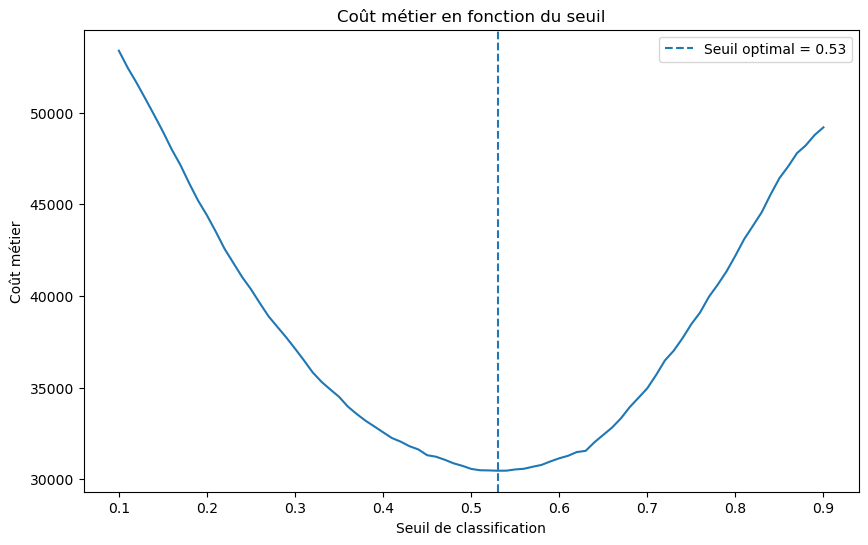

In [198]:
# ============================================================
# COURBE COUT METIER VS SEUIL
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    threshold_results_df["threshold"],
    threshold_results_df["business_cost"]
)

plt.axvline(
    best_threshold_row["threshold"],
    linestyle="--",
    label=f"Seuil optimal = {best_threshold_row['threshold']:.2f}"
)

plt.xlabel("Seuil de classification")
plt.ylabel("Coût métier")
plt.title("Coût métier en fonction du seuil")
plt.legend()

plt.show()

# comparer avant et après optimisation

In [199]:
# ============================================================
# RESULTATS DU MODELE LIGHTGBM OPTIMISE
# ============================================================

print("=" * 60)
print("RESULTATS LIGHTGBM APRES OPTIMISATION")
print("=" * 60)

print("Meilleurs hyperparamètres :")
print(grid_search.best_params_)

print()

print("AUC Cross-Validation :")
print(round(grid_search.best_score_, 4))

print()

print("Seuil optimal :")
print(best_threshold_row["threshold"])

print()

print("Coût métier minimum :")
print(best_threshold_row["business_cost"])

print()

print("False Positives :", best_threshold_row["FP"])
print("False Negatives :", best_threshold_row["FN"])
print("True Positives :", best_threshold_row["TP"])
print("True Negatives :", best_threshold_row["TN"])

RESULTATS LIGHTGBM APRES OPTIMISATION
Meilleurs hyperparamètres :
{'classifier__learning_rate': 0.05, 'classifier__max_depth': -1, 'classifier__n_estimators': 200, 'classifier__num_leaves': 31}

AUC Cross-Validation :
0.7764

Seuil optimal :
0.5299999999999998

Coût métier minimum :
30460.0

False Positives : 13670.0
False Negatives : 1679.0
True Positives : 3286.0
True Negatives : 42868.0


## Puis, crée une comparaison avant / après optimisation :

In [200]:
# ============================================================
# COMPARAISON AVANT / APRES OPTIMISATION
# ============================================================

comparison_optimization = pd.DataFrame([
    {
        "Version": "LightGBM avant optimisation",
        "AUC": 0.780008,
        "Threshold": 0.55,
        "Business_Cost": 30592
    },
    {
        "Version": "LightGBM après optimisation",
        "AUC": round(grid_search.best_score_, 6),
        "Threshold": best_threshold_row["threshold"],
        "Business_Cost": best_threshold_row["business_cost"]
    }
])

comparison_optimization

,Version,AUC,Threshold,Business_Cost
0,LightGBM avant optimisation,0.780008,0.55,30592.0
1,LightGBM après optimisation,0.776363,0.53,30460.0


# Ton modèle final optimisé

In [201]:
{
    'classifier__learning_rate': 0.05,
    'classifier__max_depth': -1,
    'classifier__n_estimators': 200,
    'classifier__num_leaves': 31
}

{'classifier__learning_rate': 0.05,
 'classifier__max_depth': -1,
 'classifier__n_estimators': 200,
 'classifier__num_leaves': 31}

# sauvegarde proprement ces résultats

In [202]:
# ============================================================
# VARIABLES FINALES DU MODELE OPTIMISE
# ============================================================

FINAL_MODEL = best_lgbm_model

FINAL_THRESHOLD = float(
    best_threshold_row["threshold"]
)

FINAL_BUSINESS_COST = float(
    best_threshold_row["business_cost"]
)

FINAL_AUC_CV = float(
    grid_search.best_score_
)

print("=" * 60)
print("MODELE FINAL OPTIMISE")
print("=" * 60)

print("AUC CV :", round(FINAL_AUC_CV, 6))
print("Seuil métier :", FINAL_THRESHOLD)
print("Coût métier :", FINAL_BUSINESS_COST)
print()
print("Meilleurs hyperparamètres :")
print(grid_search.best_params_)

MODELE FINAL OPTIMISE
AUC CV : 0.776363
Seuil métier : 0.5299999999999998
Coût métier : 30460.0

Meilleurs hyperparamètres :
{'classifier__learning_rate': 0.05, 'classifier__max_depth': -1, 'classifier__n_estimators': 200, 'classifier__num_leaves': 31}


# enregistrer cette version optimisée dans MLflow

In [203]:
# ============================================================
# ENREGISTREMENT DU MODELE OPTIMISE DANS MLFLOW
# ============================================================

import mlflow
import mlflow.sklearn

mlflow.set_experiment(
    "CreditScoring_Final_Model"
)

with mlflow.start_run(
    run_name="LightGBM_Optimized_v2"
):

    # --------------------------------------------------------
    # HYPERPARAMETRES OPTIMISES
    # --------------------------------------------------------

    mlflow.log_params(
        grid_search.best_params_
    )

    # --------------------------------------------------------
    # METRIQUES
    # --------------------------------------------------------

    mlflow.log_metric(
        "AUC_CV",
        FINAL_AUC_CV
    )

    mlflow.log_metric(
        "optimal_threshold",
        FINAL_THRESHOLD
    )

    mlflow.log_metric(
        "business_cost",
        FINAL_BUSINESS_COST
    )

    mlflow.log_metric(
        "false_positives",
        float(best_threshold_row["FP"])
    )

    mlflow.log_metric(
        "false_negatives",
        float(best_threshold_row["FN"])
    )

    mlflow.log_metric(
        "true_positives",
        float(best_threshold_row["TP"])
    )

    mlflow.log_metric(
        "true_negatives",
        float(best_threshold_row["TN"])
    )

    # --------------------------------------------------------
    # ENREGISTREMENT DU MODELE
    # --------------------------------------------------------

    model_info_optimized = mlflow.sklearn.log_model(
        sk_model=FINAL_MODEL,
        name="model",
        serialization_format="cloudpickle",
        registered_model_name="CreditScoring_LightGBM"
    )

print("=" * 60)
print("MODELE OPTIMISE ENREGISTRE AVEC SUCCES")
print("=" * 60)

print("AUC CV :", round(FINAL_AUC_CV, 6))
print("Seuil optimal :", round(FINAL_THRESHOLD, 2))
print("Coût métier :", FINAL_BUSINESS_COST)

print()
print("Model URI :")
print(model_info_optimized.model_uri)

2026/08/24 20:59:17 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
Registered model 'CreditScoring_LightGBM' already exists. Creating a new version of this model...
2026/08/24 20:59:41 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: CreditScoring_LightGBM, version 2


🏃 View run LightGBM_Optimized_v2 at: http://127.0.0.1:5000/#/experiments/2/runs/aa8fed291dcb41d88a759a7a583ff805
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2
MODELE OPTIMISE ENREGISTRE AVEC SUCCES
AUC CV : 0.776363
Seuil optimal : 0.53
Coût métier : 30460.0

Model URI :
models:/m-07ff7c25086a4f8598899078835f6148


Created version '2' of model 'CreditScoring_LightGBM'.


# attribuer champion à la version 2

In [204]:
# ============================================================
# PROMOTION DU MODELE OPTIMISE EN CHAMPION
# ============================================================

from mlflow import MlflowClient

client = MlflowClient()

client.set_registered_model_alias(
    name="CreditScoring_LightGBM",
    alias="champion",
    version="2"
)

print("=" * 60)
print("✓ NOUVEAU MODELE CHAMPION")
print("=" * 60)

print("Modèle : CreditScoring_LightGBM")
print("Version : 2")
print("Alias : champion")
print("Seuil métier : 0.53")
print("Coût métier : 30460")

✓ NOUVEAU MODELE CHAMPION
Modèle : CreditScoring_LightGBM
Version : 2
Alias : champion
Seuil métier : 0.53
Coût métier : 30460


In [205]:
# ============================================================
# VERIFICATION DU CHAMPION
# ============================================================

champion_model = client.get_model_version_by_alias(
    "CreditScoring_LightGBM",
    "champion"
)

print("=" * 60)
print("VERIFICATION DU MODELE CHAMPION")
print("=" * 60)

print("Nom :", champion_model.name)
print("Version :", champion_model.version)
print("Alias :", champion_model.aliases)
print("Statut :", champion_model.status)

VERIFICATION DU MODELE CHAMPION
Nom : CreditScoring_LightGBM
Version : 2
Alias : ['champion']
Statut : READY
